# Predicting Churn as a Communication Problem

The analytical notebook behind the TCC *Customer Churn Classification on a Telecom Benchmark: Comparing Models, Explaining XGBoost, and Developing Hypotheses for Digital Communication*.

**Author:** Artur Pedrotti Grochau · **Advisor:** Prof. Dr. Matheus Cavalcanti Pestana
**Institution:** FGV ECMI, Graduação em Comunicação Digital · 2026

## What this notebook is for

The written TCC tells the argument; this notebook is where every number in it is produced. It follows the six CRISP-DM phases on the IBM Telco Customer Churn benchmark (7,043 records of a fictional operator): it prepares the data, tunes five model families, compares them on the same holdout, shows how the decision cutoff changes who is flagged, and explains one XGBoost model with SHAP. Every table and figure is written to `thesis_exports/`, and the report reads them from there.

## Where each section of the TCC comes from

| TCC section | Notebook section |
|---|---|
| 3 Methodology: data and preparation | [Business understanding](#business-understanding) → [Data understanding](#data-understanding) → [Data preparation](#data-preparation) |
| 3 Methodology: five models | [Modeling](#modeling) |
| 5.1 Who leaves | [Data understanding](#data-understanding) |
| 5.2 Five models compared | [Evaluation](#evaluation) |
| 5.3 The cutoff | [Thresholds make the outreach burden visible](#evaluation) |
| 5.4 Signals the model relies on | [SHAP explanation](#explainability) |
| 5.5 From signals to communication hypotheses | [Signal-to-test tables](#signal-to-test) |
| Demo used in the presentation | [Offline demo export](#demo-export) |

Charts the TCC does not use (numeric and category distributions, correlations, SHAP dependence plots) are kept in an appendix at the end.

### Main findings

- **The models rank customers about equally well.** Holdout ROC-AUC goes from 0.836 (SVM) to 0.848 (XGBoost), a spread of about one point.
- **The cutoff matters more than the model.** For XGBoost, lowering the cutoff from 0.50 to 0.07 flags 364 instead of 198 of the 374 churners, but also 584 instead of 96 customers who stayed.
- **Contract type and tenure carry the strongest signals**, about 40% of the grouped SHAP attribution. This describes what the model uses, not why people leave.
- **The communication contribution is a method**: each signal becomes a question, an alternative explanation and a test a platform could run. None of those tests is run here.

## Reproduce the analysis

1. Python 3.14 and the pinned dependencies in `requirements.txt`: `uv venv --python 3.14`, then `uv pip install --python .venv/bin/python -r requirements.txt`. On macOS, XGBoost also needs `libomp` (see README).
2. Work from the repository root. The input is `data/WA_Fn-UseC_-Telco-Customer-Churn.csv`; its checksum is pinned in README.
3. Run all cells from top to bottom; partial reruns can keep stale kernel state.
4. `scripts/verify_reproducibility.sh` executes a copy and compares the exported tables with the committed ones.

A full run takes about 25 minutes on an Apple M5 Pro, most of it SVM fitting.

### Setup and reproducibility

The next audit examines types, missing values, blank strings and duplicate rows. `RANDOM_STATE = 42` is reused for splits, stochastic estimators, search sampling, cross-validation and bootstrap resampling. It fixes those choices for comparison; it does not remove uncertainty about other datasets or sampling designs.

Exact library versions are pinned. Parallel numerical routines can differ slightly across machines, so the reproducibility check compares numerical exports within tolerance. Bootstrap intervals below resample predictions from the fitted models; they do not quantify variability from retraining, retuning or changing the initial split.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
RANDOM_STATE = 42

print(f"RANDOM_STATE set to: {RANDOM_STATE}")

import os
import time
import warnings

# Suppress verbose sklearn parallel warnings across main and worker processes.
os.environ["PYTHONWARNINGS"] = ",".join(
    filter(
        None,
        [
            os.environ.get("PYTHONWARNINGS", ""),
            "ignore::UserWarning:sklearn.utils.parallel",
        ],
    )
)

from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import auc, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore", category=UserWarning, module=r"sklearn\.utils\.parallel")
# Narrow deprecation filters. The pinned stack is bleeding-edge (pandas 3,
# scikit-learn 1.8), so FutureWarnings are expected; they are silenced only
# for these two libraries rather than globally, so anything unexpected from
# elsewhere still surfaces.
warnings.filterwarnings("ignore", category=FutureWarning, module=r"sklearn(\.|$)")
warnings.filterwarnings("ignore", category=FutureWarning, module=r"pandas(\.|$)")
# scikit-learn 1.8 deprecates LogisticRegression(penalty=...) in favour of
# l1_ratio and warns that the two "look inconsistent" whenever penalty is
# given explicitly. The explicit penalty is still honoured (for saga,
# penalty="l1" sets the L1 weight to 1/C and the L2 weight to 0), so the
# fits are exactly what the search space names. The warning is noise and is
# silenced here, with the reasoning stated in the Logistic Regression note.
warnings.filterwarnings("ignore", message=r"Inconsistent values: penalty=", category=UserWarning)
warnings.filterwarnings("ignore", message=r"'penalty' was deprecated", category=FutureWarning)

print("Modeling dependencies loaded.")

RANDOM_STATE set to: 42
Modeling dependencies loaded.


In [2]:
# Figure styling and save_figure helper.
#
# A single source of truth for figure appearance and export paths.
# Every later figure should go through save_figure(fig, name); the
# helper writes a vector PDF (for thesis insertion) and a 300 dpi PNG
# (for screen review and rendering in markdown previews) at the same
# canonical thesis_exports/figures/<name>.{pdf,png} location.

from typing import Optional
from matplotlib.figure import Figure

# `Path` is imported in the setup cell above.

# Colorblind-safe palette applied globally; individual figures may
# pass their own palette to seaborn calls but the default is shared.
PLOT_PALETTE = sns.color_palette("colorblind")
sns.set_palette(PLOT_PALETTE)

# One colour per model, used by every model-comparison figure in the
# notebook (ROC, calibration, threshold/cost, repeated CV, split ratio).
# Before this, the same model appeared green in one figure and pink in
# another because each figure fell back to its own colour cycle.
MODEL_ORDER = ["Logistic Regression", "Random Forest", "XGBoost", "SVM", "MLP"]
MODEL_COLORS = {name: PLOT_PALETTE[i] for i, name in enumerate(MODEL_ORDER)}


def model_color(name: str):
    """Stable colour for a model name; unknown names extend the palette."""
    if name not in MODEL_COLORS:
        MODEL_COLORS[name] = PLOT_PALETTE[len(MODEL_COLORS) % len(PLOT_PALETTE)]
    return MODEL_COLORS[name]

plt.rcParams.update({
    "figure.dpi": 110,            # screen rendering
    "savefig.dpi": 300,           # print/PDF rendering
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "legend.fontsize": 9,
    "legend.frameon": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 13,
    "lines.linewidth": 1.7,
})

# Two canonical export directories, defined once. Every later cell writes
# through FIGURES_DIR / TABLES_DIR -- earlier revisions carried five aliases
# (EXPORTS_TABLES_EARLY / EXPORTS_TABLES / EXPORTS_TABLES_LATE /
# EXPORTS_FIGURES) for these same two paths.
FIGURES_DIR = Path("thesis_exports/figures")
TABLES_DIR = Path("thesis_exports/tables")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(
    fig: Optional[Figure],
    name: str,
    *,
    formats=("pdf", "png"),
    close: bool = False,
) -> list[Path]:
    """Save a figure to thesis_exports/figures/<name>.<ext> for each ext.

    Parameters
    ----------
    fig
        A matplotlib Figure. If None, uses the current pyplot figure
        (`plt.gcf()`) so callers that drew with the pyplot API still work.
    name
        Filename stem (no extension). Will overwrite existing files at
        the same stem so re-runs are idempotent.
    formats
        Iterable of extensions; defaults to PDF (vector) + PNG (raster).
    close
        Release the figure after writing. Defaults to False on purpose:
        every caller here calls `save_figure(...)` *before* `plt.show()`,
        and closing first would suppress the inline render in the executed
        notebook. Cells that build figures in a loop close explicitly with
        `plt.close(fig)` after `plt.show()`.

    Returns
    -------
    list[Path]
        The paths written, useful for a `print(saved)` line in the cell.
    """
    if fig is None:
        fig = plt.gcf()
    out_paths: list[Path] = []
    for ext in formats:
        out = FIGURES_DIR / f"{name}.{ext}"
        # dpi only affects raster formats; bbox handled via rcParams
        fig.savefig(out)
        out_paths.append(out)
    if close:
        plt.close(fig)
    return out_paths


print("Figure styling + save_figure() helper ready (vector PDF + 300 dpi PNG).")
print(f"Export directories: {FIGURES_DIR} and {TABLES_DIR}")
print(f"Shared model palette: {', '.join(MODEL_ORDER)}")


Figure styling + save_figure() helper ready (vector PDF + 300 dpi PNG).
Export directories: thesis_exports/figures and thesis_exports/tables
Shared model palette: Logistic Regression, Random Forest, XGBoost, SVM, MLP


In [3]:
from pathlib import Path
import pandas as pd

dataset_path_candidates = [
    Path("WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("data") / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]

file_path = next((candidate for candidate in dataset_path_candidates if candidate.exists()), None)
if file_path is None:
    raise FileNotFoundError(
        "Dataset file not found. Expected WA_Fn-UseC_-Telco-Customer-Churn.csv in the project root or data/."
    )

df = pd.read_csv(file_path)
print(f"Dataset loaded from: {file_path.as_posix()}")
print(f"Dataset shape: {df.shape}")
print("\nPreview (first 5 rows):")
print(df.head(5))
print("\nDataset schema:")
df.info()

Dataset loaded from: data/WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset shape: (7043, 21)

Preview (first 5 rows):
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     F

<a id="business-understanding"></a>
## CRISP-DM: Business Understanding

### The decision this study illustrates

A communication team has limited capacity to contact users. A score can help organize a review queue, but a false alarm can waste attention, create anxiety or lead to an unwanted offer. A missed case may leave an unresolved problem unnoticed. The analysis shows how the cutoff changes these error counts.

The unit is one customer record with IBM's retrospective label: whether the customer left within the last month. The study evaluates classification of this recorded label. It cannot establish a forecast made before the departure.

ROC-AUC is the primary tuning metric. Precision, recall and F1 describe decisions at probability 0.50; Brier score and reliability diagrams examine probability quality. A threshold sweep assigns illustrative penalties to errors. Those penalties are neither measured campaign costs nor estimates of the effect of contacting someone.

XGBoost is fixed as the illustrative explanation model because its trees can be explained with TreeSHAP and exported to the offline demo. This October revision makes that choice explicit after the original results were examined. It does not select a deployment winner from the holdout.

### Communication contribution

On a social platform, leaving can affect participation and relationships with other users. Understanding that process would require platform activity, user accounts of their experience and a defined departure outcome. This dataset contains none of those measures. Contract type, tenure, services and charges instead provide a bounded example for moving from a model signal to a communication hypothesis.

The proposed workflow is: **observe a signal → consider competing explanations → formulate a response → evaluate it with users**. A relationship should not be treated as successful merely because cancellation is difficult. Voluntary disengagement, contact preferences and ease of exit belong in the evaluation.

### Theoretical questions, distinct from measurements

Work on media habits (LaRose, 2010) and the habit-goal relationship (Wood and Neal, 2007) motivates examining repeated behavior in a stable context. Months since signup alone do not provide those observations. Commitment-trust theory (Morgan and Hunt, 1994) motivates asking about trust and commitment, which would require appropriately designed measures rather than an add-on subscription flag.

Platform research also considers network effects (McIntyre and Srinivasan, 2017). Their relevance here is conceptual: the Telco file contains no network or participation data from which to estimate effects on other users. These theories shape questions for a future platform study; they are not constructs validated by this notebook.

### Scope

One curated benchmark; cross-sectional records; five model families; associative explanations; hypothetical interventions. Portability to communication-platform data remains untested.

<a id="data-understanding"></a>
## CRISP-DM: Data Understanding

### Phase objective
Establish what the data is and what it can support: provenance, data quality, class balance, and how churn distributes across the features.

### In-scope deliverables
- Provenance and label definition of the benchmark.
- Focused EDA for data quality, imbalance, and churn-relevant relationships.

### Scope boundary
This section stops before the preparation pipeline, which has its own phase header below.

### Glossary for a non-specialist reader

| Term | Meaning in this study |
|---|---|
| **Churn** | Leaving the service; IBM defines this recorded label retrospectively over the last month. |
| **CRISP-DM** | A workflow covering business understanding, data understanding, preparation, modeling, evaluation and deployment planning. |
| **Stratified split** | A train/test division that keeps approximately the same churn proportion in both parts. |
| **Cross-validation (CV)** | Training on several subsets and scoring the remaining folds. Reusing folds for model selection makes their later scores internal diagnostics, not an independent final estimate. |
| **Precision** | The share of flagged records whose recorded label is churn. |
| **Recall** | The share of recorded churners that are flagged. |
| **F1** | The harmonic mean of precision and recall. |
| **ROC-AUC** | How often a random churner receives a higher score than a random non-churner, with half credit for ties. It summarizes ranking across cutoffs. |
| **Threshold** | The score cutoff used to flag a record. Changing it alters the error counts. |
| **Illustrative error cost** | `(FN penalty × missed churners + FP penalty × false alarms) / number of records`. It excludes intervention effectiveness and actual campaign costs. |
| **Calibration** | Agreement between predicted probabilities and observed frequencies in comparable groups. |
| **Brier score** | Mean squared probability error. Lower is better overall, but it combines calibration, discrimination and outcome uncertainty. It is not a calibration-only measure. |
| **Reliability diagram** | Binned mean predicted probability against observed churn frequency; the bin size and counts affect its interpretation. |
| **Platt scaling** | The sigmoid mapping used by SVC to convert its decision scores to probabilities. Its probability cutoff can disagree with its native classification rule. |
| **Isotonic calibration** | A fitted monotone remapping of scores to probabilities. Here it is a supplementary comparison, trained within the training data. |
| **Bootstrap interval** | An interval from resampling the holdout rows. Here it conditions on fitted models and fixed class counts; it does not include the entire model-selection uncertainty. |
| **DeLong test** | A test of an AUC difference measured on the same records. A non-significant result does not establish equivalence. |
| **Overfitting gap** | Difference between a training score and a held-out score. It is a diagnostic, not proof that overfitting is absent. |
| **Learning curve** | Scores at different training sizes. It describes the sizes and settings examined, not an ultimate performance ceiling. |
| **SHAP** | Attribution of a model prediction to input features under the explainer's assumptions. It does not identify causes or prove an intervention works. |
| **Log-odds / base value** | The additive score scale used for XGBoost SHAP and its reference starting value. Applying the logistic function converts the total to a probability. |
| **Permutation importance** | The change in model score when one feature is shuffled. Correlated features and sampling variability affect it. |
| **Cramér's V** | A summary of association between categorical variables. |
| **SMOTE** | A method that generates minority-class training examples. It is not used here. |

The [SHAP section](#explainability) explains the terminology adopted for interpretability and explainability.

### Dataset provenance and scope

The IBM Telco Customer Churn file contains 7,043 records and 21 fields. IBM documents a fictional telecommunications operator; the record-construction process is not documented. The repository pins the publicly redistributed file by checksum. It is a curated benchmark, and its measured performance cannot be assumed to describe a real operator.

IBM describes the label as whether the customer left within the last month. The file lacks event timestamps, documented covariate observation times and a follow-up design. The classification task therefore concerns the recorded label, with no validated prospective horizon.

Telco was chosen as a manageable public example with interpretable service and subscription fields. Other adjacent public datasets exist, including the KKBox subscription-streaming challenge. External replication is future work. Neither this choice nor internal cross-validation demonstrates transfer to social-media churn.

Sources: [IBM sample guide](https://www.ibm.com/docs/SSEP7J_11.1.0/com.ibm.swg.ba.cognos.ig_smples.doc/ig_smples.pdf?view=kc); [WSDM 2018 challenge description](https://www.wsdm-conference.org/2018/call-for-participants.html).

In [4]:
# Unified feature audit + data quality diagnostics
# Requires pandas >= 3.0: passing "str" to select_dtypes raises TypeError on pandas 2.x, so do not downgrade the pandas pin (see requirements.txt).
categorical_like = df.select_dtypes(include=["object", "str", "category", "bool"]).columns.tolist()
numeric_like = df.select_dtypes(include=["number"]).columns.tolist()

blank_counts = []
for col in df.columns:
    if col in categorical_like:
        blank_counts.append((df[col].astype(str).str.strip() == "").sum())
    else:
        blank_counts.append(0)

audit_df = pd.DataFrame(
    {
        "column": df.columns,
        "dtype": df.dtypes.astype(str).values,
        "type_group": ["numeric" if c in numeric_like else "categorical-like" for c in df.columns],
        "missing_values": [df[c].isna().sum() for c in df.columns],
        "blank_strings": blank_counts,
        "n_unique": [df[c].nunique(dropna=False) for c in df.columns],
    }
).sort_values(["missing_values", "blank_strings", "n_unique"], ascending=False).reset_index(drop=True)

display(audit_df)
print(f"\nDuplicate rows: {df.duplicated().sum()}")

anomaly_df = audit_df[(audit_df["missing_values"] > 0) | (audit_df["blank_strings"] > 0)]
if len(anomaly_df) > 0:
    print("\nColumns with anomalies (missing or blank strings):")
    display(anomaly_df)
else:
    print("\nNo missing/blank anomalies detected in current raw view.")

# Focused anomaly inspection: TotalCharges blank strings and numeric coercion
if "TotalCharges" in df.columns:
    totalcharges_blank = (df["TotalCharges"].astype(str).str.strip() == "").sum()
    totalcharges_probe = pd.to_numeric(df["TotalCharges"], errors="coerce")
    totalcharges_coerced_nan = totalcharges_probe.isna().sum()

    print(f"\nTotalCharges dtype (raw): {df['TotalCharges'].dtype}")
    print(f"TotalCharges blank strings: {totalcharges_blank}")
    print(f"TotalCharges NaN after numeric coercion probe: {totalcharges_coerced_nan}")

    if totalcharges_coerced_nan > 0:
        display(
            df.loc[
                totalcharges_probe.isna(),
                ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"],
            ].head(10)
        )

,column,dtype,type_group,missing_values,blank_strings,n_unique
0,TotalCharges,str,categorical-like,0,11,6531
1,customerID,str,categorical-like,0,0,7043
2,MonthlyCharges,float64,numeric,0,0,1585
3,tenure,int64,numeric,0,0,73
4,PaymentMethod,str,categorical-like,0,0,4
5,MultipleLines,str,categorical-like,0,0,3
6,InternetService,str,categorical-like,0,0,3
7,OnlineSecurity,str,categorical-like,0,0,3
8,OnlineBackup,str,categorical-like,0,0,3
9,DeviceProtection,str,categorical-like,0,0,3



Duplicate rows: 0

Columns with anomalies (missing or blank strings):


,column,dtype,type_group,missing_values,blank_strings,n_unique
0,TotalCharges,str,categorical-like,0,11,6531



TotalCharges dtype (raw): str
TotalCharges blank strings: 11
TotalCharges NaN after numeric coercion probe: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


### Audit finding

`TotalCharges` contains 11 blank strings. All occur with `tenure = 0` and `Churn = No`. The audit finds no duplicate rows and no other missing entries in the supplied file. This is a check of visible data quality, not confirmation that the recorded values or construction process are valid.

The preparation section documents the decision to replace these blanks with zero, an assumption consistent with newly opened accounts rather than a fact established by billing histories.

,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


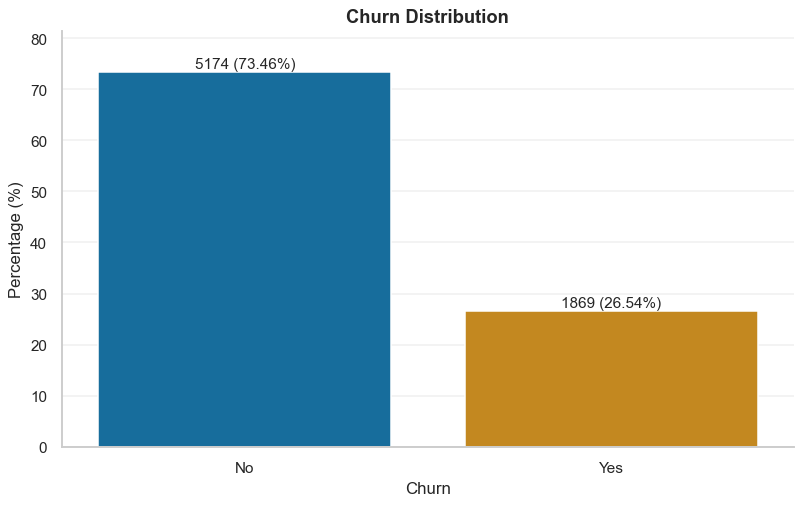

In [5]:
# Target distribution and class imbalance check
churn_counts = df["Churn"].value_counts(dropna=False)
churn_percent = (df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(2)

churn_distribution = pd.DataFrame(
    {
        "count": churn_counts,
        "percentage": churn_percent,
    }
)
display(churn_distribution)

plt.figure(figsize=(7.5, 4.8))
ax = sns.barplot(
    x=churn_percent.index,
    y=churn_percent.values,
    hue=churn_percent.index,
    palette=[PLOT_PALETTE[0], PLOT_PALETTE[1]],
    legend=False,
)

for i, label in enumerate(churn_percent.index):
    ax.text(
        i,
        churn_percent.iloc[i] + 0.8,
        f"{churn_counts.iloc[i]} ({churn_percent.iloc[i]:.2f}%)",
        ha="center",
        fontsize=10,
    )

ax.set_title("Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Percentage (%)")
plt.ylim(0, max(churn_percent.values) + 8)
plt.tight_layout()
save_figure(plt.gcf(), "eda_churn_distribution")
plt.show()

### Class balance and the choice not to resample

There are 1,869 churners and 5,174 retained records: about 26.54% and 73.46%. Stratified splitting and CV preserve these proportions approximately. The training split contains 1,495 churners, about 299 in each five-fold validation partition.

The workflow retains the original class distribution. Some model search spaces include class weighting, while the evaluation reports threshold-specific errors and probability quality. Synthetic resampling was not compared, so no claim is made that it would necessarily help or harm these models. If considered later, it must occur within training folds and its effect on probabilities must be checked.

**Figure 1. Churn class distribution.** The bars describe the supplied benchmark. They do not estimate churn prevalence on a social platform.

In [6]:
# Numeric descriptive statistics
eda_numeric_df = df.copy()
eda_numeric_df["TotalCharges_num"] = pd.to_numeric(eda_numeric_df["TotalCharges"], errors="coerce")

numeric_focus = ["tenure", "MonthlyCharges", "TotalCharges_num"]
numeric_stats = eda_numeric_df[numeric_focus].describe().T
numeric_stats["missing"] = eda_numeric_df[numeric_focus].isna().sum()

display(numeric_stats)

,count,mean,std,min,25%,50%,75%,max,missing
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,0
TotalCharges_num,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,11


### Numeric profile

`tenure` averages 32.4 months (median 29, range 0–72). `MonthlyCharges` averages 64.76 (median 70.35), while non-missing `TotalCharges` averages 2,283.30 (median 1,397). The latter arrives as text and is converted to numeric. These are durations and billed amounts, not measures of relationship quality.

,feature,max_churn_rate_pct,min_churn_rate_pct,gap_pct_points
0,Contract,42.71,2.83,39.88
1,InternetService,41.89,7.40,34.49
2,OnlineSecurity,41.77,7.40,34.37
3,TechSupport,41.64,7.40,34.24
4,PaymentMethod,45.29,15.24,30.05
5,SeniorCitizen,41.68,23.61,18.07
6,PaperlessBilling,33.57,16.33,17.24
7,Dependents,31.28,15.45,15.83
8,Partner,32.96,19.66,13.30
9,gender,26.92,26.16,0.76


,feature,level,count,churn_rate_pct
0,PaymentMethod,Electronic check,2365,45.29
1,Contract,Month-to-month,3875,42.71
2,InternetService,Fiber optic,3096,41.89
3,OnlineSecurity,No,3498,41.77
4,SeniorCitizen,Yes,1142,41.68
5,TechSupport,No,3473,41.64
6,PaperlessBilling,Yes,4171,33.57
7,Partner,No,3641,32.96
8,Dependents,No,4933,31.28
9,gender,Female,3488,26.92


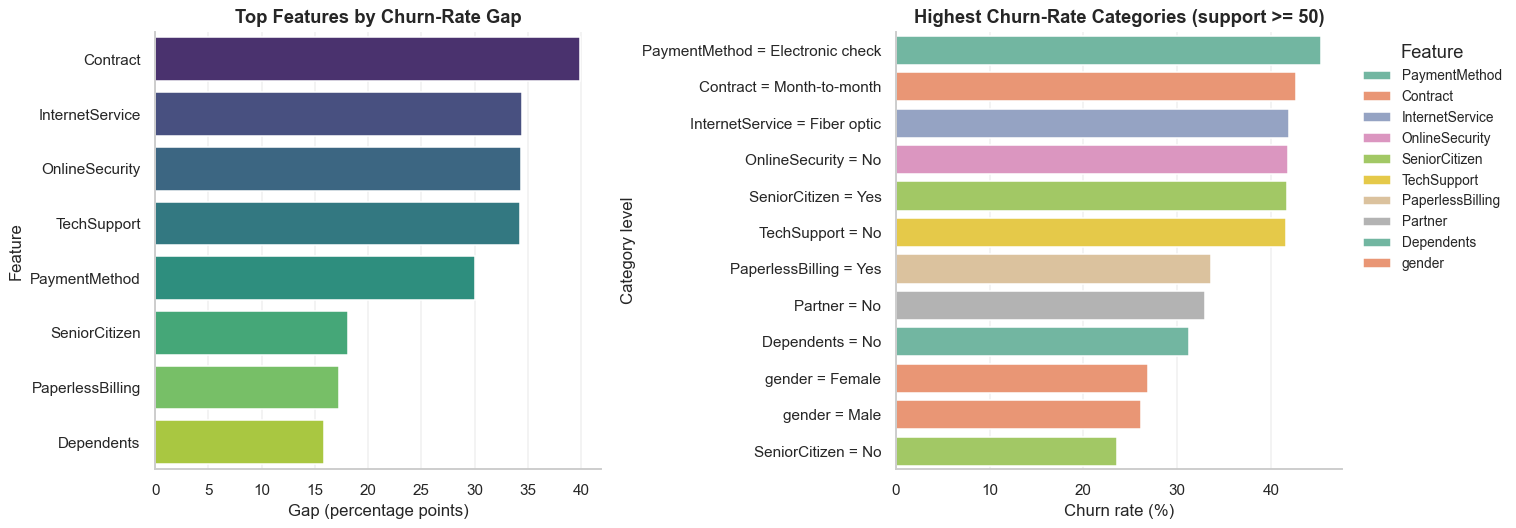

In [7]:
# Categorical features vs churn rate
categorical_for_churn = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling",
    "OnlineSecurity",
    "TechSupport",
]

analysis_df = df.copy()
analysis_df["SeniorCitizen"] = analysis_df["SeniorCitizen"].map({0: "No", 1: "Yes"}).fillna(
    analysis_df["SeniorCitizen"].astype(str)
)

churn_rate_rows = []
feature_gaps = []

for col in categorical_for_churn:
    grouped = analysis_df.groupby(col)["Churn"]
    rates = (grouped.apply(lambda s: (s == "Yes").mean() * 100)).round(2)
    counts = grouped.size()

    for level in rates.index:
        churn_rate_rows.append(
            {
                "feature": col,
                "level": level,
                "count": int(counts.loc[level]),
                "churn_rate_pct": float(rates.loc[level]),
            }
        )

    feature_gaps.append(
        {
            "feature": col,
            "max_churn_rate_pct": float(rates.max()),
            "min_churn_rate_pct": float(rates.min()),
            "gap_pct_points": float((rates.max() - rates.min()).round(2)),
        }
    )

churn_rate_table = pd.DataFrame(churn_rate_rows).sort_values("churn_rate_pct", ascending=False).reset_index(drop=True)
churn_gap_table = pd.DataFrame(feature_gaps).sort_values("gap_pct_points", ascending=False).reset_index(drop=True)

display(churn_gap_table)
display(
    churn_rate_table[churn_rate_table["count"] >= 50]
    .sort_values("churn_rate_pct", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=churn_gap_table.head(8),
    x="gap_pct_points",
    y="feature",
    hue="feature",
    palette="viridis",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Top Features by Churn-Rate Gap")
axes[0].set_xlabel("Gap (percentage points)")
axes[0].set_ylabel("Feature")

top_levels = (
    churn_rate_table[churn_rate_table["count"] >= 50]
    .sort_values("churn_rate_pct", ascending=False)
    .head(12)
)
top_levels["feature_level"] = top_levels["feature"] + " = " + top_levels["level"].astype(str)

sns.barplot(
    data=top_levels,
    x="churn_rate_pct",
    y="feature_level",
    hue="feature",
    palette="Set2",
    dodge=False,
    ax=axes[1],
)
axes[1].set_title("Highest Churn-Rate Categories (support >= 50)")
axes[1].set_xlabel("Churn rate (%)")
axes[1].set_ylabel("Category level")
axes[1].legend(title="Feature", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
save_figure(fig, "eda_churn_gap_plot")
plt.show()

### Churn rates by category

The observed churn proportion is 42.71% for month-to-month contracts and 2.83% for two-year contracts. Electronic-check users have 45.29% churn in the displayed categories. These are unadjusted associations; contract restrictions, bundle composition and selection into plans are plausible competing explanations.

**Figure 2. Churn-rate gaps and high-churn categories.** The chart helps identify questions for later modeling. It does not show that changing a category would change a person's outcome. Small differences by gender do not establish fairness.

In [8]:
# Churn rate by group: the five comparisons the TCC (Section 5.1) and slide 7 print.
# Each row pairs a higher-churn group with its comparison group on all 7,043 records.
churned = df["Churn"].eq("Yes")
has_internet = df["InternetService"].ne("No")
group_definitions = [
    ("Contract", "Month-to-month", df["Contract"].eq("Month-to-month"),
     "One or two years", df["Contract"].ne("Month-to-month")),
    ("Tenure", "12 months or less", df["tenure"].le(12), "More than 12 months", df["tenure"].gt(12)),
    ("Internet service", "Fiber optic", df["InternetService"].eq("Fiber optic"),
     "DSL", df["InternetService"].eq("DSL")),
    ("Payment method", "Electronic check", df["PaymentMethod"].eq("Electronic check"),
     "Other methods", df["PaymentMethod"].ne("Electronic check")),
    ("Online security (internet customers)", "Without", has_internet & df["OnlineSecurity"].eq("No"),
     "With", has_internet & df["OnlineSecurity"].eq("Yes")),
]
churn_group_df = pd.DataFrame([
    {
        "variable": variable,
        "higher_group": high_label,
        "higher_customers": int(high.sum()),
        "higher_churn_rate": float(churned[high].mean()),
        "comparison_group": low_label,
        "comparison_customers": int(low.sum()),
        "comparison_churn_rate": float(churned[low].mean()),
    }
    for variable, high_label, high, low_label, low in group_definitions
])
display(churn_group_df)
churn_group_df.to_csv(TABLES_DIR / "churn_rate_by_group.csv", index=False)
print(f"Saved {TABLES_DIR / 'churn_rate_by_group.csv'}")

,variable,higher_group,higher_customers,higher_churn_rate,comparison_group,comparison_customers,comparison_churn_rate
0,Contract,Month-to-month,3875,0.427097,One or two years,3168,0.067551
1,Tenure,12 months or less,2186,0.474382,More than 12 months,4857,0.171299
2,Internet service,Fiber optic,3096,0.418928,DSL,2421,0.189591
3,Payment method,Electronic check,2365,0.452854,Other methods,4678,0.170586
4,Online security (internet customers),Without,3498,0.417667,With,2019,0.146112


Saved thesis_exports/tables/churn_rate_by_group.csv


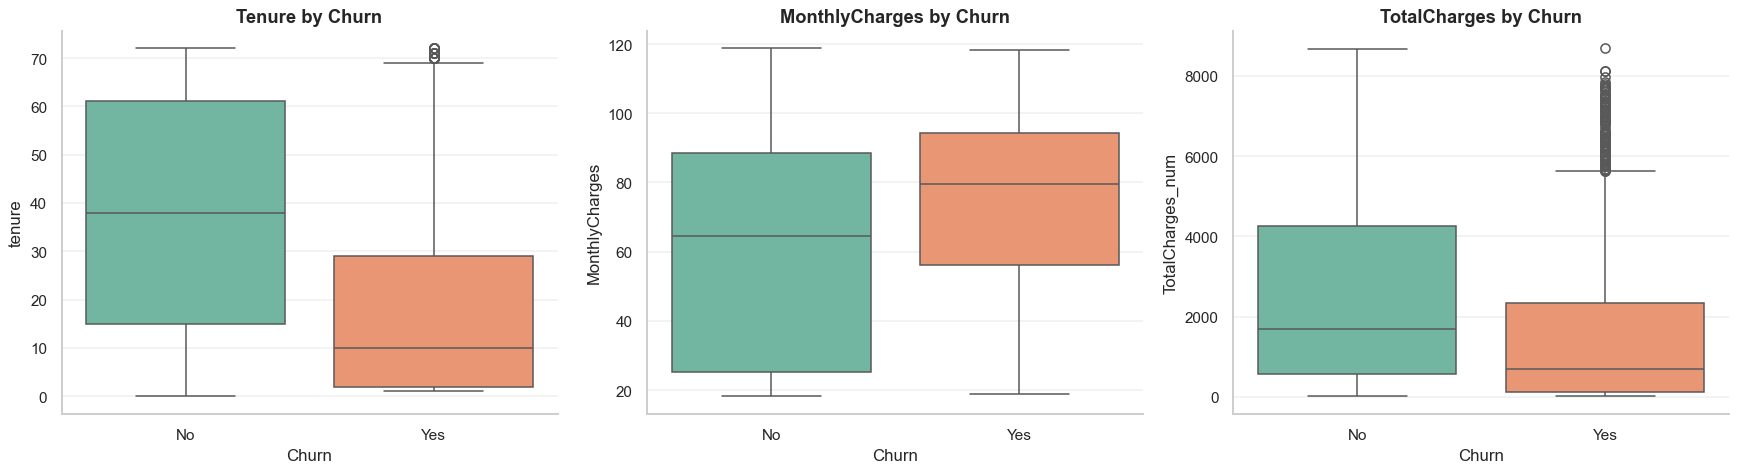

,tenure,MonthlyCharges,TotalCharges_num
Churn,,,
No,37.57,61.27,2555.34
Yes,17.98,74.44,1531.80


In [9]:
# Numeric features vs churn
numeric_vs_churn = eda_numeric_df.copy()
numeric_vs_churn["Churn"] = df["Churn"].values

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.boxplot(data=numeric_vs_churn, x="Churn", y="tenure", hue="Churn", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Tenure by Churn")

sns.boxplot(data=numeric_vs_churn, x="Churn", y="MonthlyCharges", hue="Churn", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("MonthlyCharges by Churn")

sns.boxplot(
    data=numeric_vs_churn.dropna(subset=["TotalCharges_num"]),
    x="Churn",
    y="TotalCharges_num",
    hue="Churn",
    palette="Set2",
    legend=False,
    ax=axes[2],
)
axes[2].set_title("TotalCharges by Churn")

plt.tight_layout()
save_figure(fig, "eda_numeric_vs_churn")
plt.show()

numeric_churn_summary = numeric_vs_churn.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges_num"]].mean().round(2)
display(numeric_churn_summary)

### Numeric fields by recorded outcome

Churners have mean tenure 17.98 months, compared with 37.57 for retained records. Their mean monthly charges are 74.44 versus 61.27, and total charges 1,531.80 versus 2,555.34. Tenure and accumulated charges are related, so these differences should not be interpreted as independent mechanisms.

**Figure 3. Numerical fields by churn label.** The groups differ in recorded tenure and billing. SHAP later describes how a fitted model uses these fields; it does not directly test habit, dissatisfaction or price sensitivity.

### Data-understanding summary

Contract category, service configuration, tenure and charges show associations with the recorded churn label. The EDA describes the full supplied file; model preprocessing is fitted within training data in the next phase.

<a id="data-preparation"></a>
## CRISP-DM: Data Preparation

### Preparation objective
Build leakage-safe model inputs while preserving transparency and reproducibility.

### Anti-leakage rules
- Use stratified train-test split with fixed random state.
- Fit encoders/scaler on training data only.
- Transform test data only with fitted train artifacts.

In [10]:
# Reproducible preparation working copy
prep_df = df.copy()
print(f"Preparation dataframe shape: {prep_df.shape}")
print(f"RANDOM_STATE configured as: {RANDOM_STATE}")

# TotalCharges conversion audit
prep_df["TotalCharges"] = pd.to_numeric(prep_df["TotalCharges"], errors="coerce")
totalcharges_missing_after_conversion = prep_df["TotalCharges"].isna().sum()

print(f"TotalCharges dtype after conversion: {prep_df['TotalCharges'].dtype}")
print(f"Missing values introduced by coercion: {totalcharges_missing_after_conversion}")

if totalcharges_missing_after_conversion > 0:
    display(
        prep_df.loc[
            prep_df["TotalCharges"].isna(),
            ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"],
        ].head(10)
    )

# Missing-value handling and validation
missing_before = prep_df.isna().sum().sort_values(ascending=False)

# Domain-consistent treatment: customers with tenure 0 have no accumulated charges yet.
# Only they may have a blank total; any other blank stops the run instead of becoming 0.
blank_total = prep_df["TotalCharges"].isna()
assert prep_df.loc[blank_total, "tenure"].eq(0).all(), "blank TotalCharges with tenure > 0"
prep_df.loc[blank_total, "TotalCharges"] = 0.0

missing_after = prep_df.isna().sum().sort_values(ascending=False)

missing_comparison = pd.DataFrame(
    {
        "missing_before": missing_before,
        "missing_after": missing_after,
    }
)

display(missing_comparison)
print(f"Total remaining missing values: {int(prep_df.isna().sum().sum())}")

# Export the before/after table the thesis cites. `index_label="column"`
# names the index column explicitly; the previously hand-written copy of
# this file carried a malformed `Unnamed: 0` header.
missing_comparison.to_csv(
    TABLES_DIR / "data_quality_missing_comparison.csv", index_label="column"
)
print(f"Saved {TABLES_DIR / 'data_quality_missing_comparison.csv'}")

Preparation dataframe shape: (7043, 21)
RANDOM_STATE configured as: 42
TotalCharges dtype after conversion: float64
Missing values introduced by coercion: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


,missing_before,missing_after
Churn,0,0
Contract,0,0
Dependents,0,0
DeviceProtection,0,0
InternetService,0,0
MonthlyCharges,0,0
MultipleLines,0,0
OnlineBackup,0,0
OnlineSecurity,0,0
PaperlessBilling,0,0


Total remaining missing values: 0
Saved thesis_exports/tables/data_quality_missing_comparison.csv


### Handling the 11 blank total-charge values

The 11 blanks occur at tenure zero. This workflow replaces them with 0.0, consistent with treating a newly opened account as having no accumulated bill. The file has no billing history to verify that assumption. The rule preserves every row and uses no estimated population statistic or outcome-dependent value.

### Missing-value check

After that rule, no missing entries remain in the 7,043-row frame. No row was dropped. This verifies the implemented correction, not the validity of every underlying record.

In [11]:
# Data type standardization for modeling
prep_df["SeniorCitizen"] = prep_df["SeniorCitizen"].map({0: "No", 1: "Yes"}).astype("category")

string_like_cols = prep_df.select_dtypes(include=["object", "str"]).columns.tolist()
for col in string_like_cols:
    prep_df[col] = prep_df[col].astype(str).str.strip().astype("category")

dtype_overview = prep_df.dtypes.astype(str).rename("dtype").reset_index().rename(columns={"index": "column"})
display(dtype_overview)
print(prep_df.info())

# Drop non-predictive identifier
if "customerID" in prep_df.columns:
    prep_df = prep_df.drop(columns=["customerID"])

print(f"Shape after dropping customerID: {prep_df.shape}")
print("Remaining columns:")
print(prep_df.columns.tolist())

,column,dtype
0,customerID,category
1,gender,category
2,SeniorCitizen,category
3,Partner,category
4,Dependents,category
5,tenure,int64
6,PhoneService,category
7,MultipleLines,category
8,InternetService,category
9,OnlineSecurity,category


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   category
 1   gender            7043 non-null   category
 2   SeniorCitizen     7043 non-null   category
 3   Partner           7043 non-null   category
 4   Dependents        7043 non-null   category
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   category
 7   MultipleLines     7043 non-null   category
 8   InternetService   7043 non-null   category
 9   OnlineSecurity    7043 non-null   category
 10  OnlineBackup      7043 non-null   category
 11  DeviceProtection  7043 non-null   category
 12  TechSupport       7043 non-null   category
 13  StreamingTV       7043 non-null   category
 14  StreamingMovies   7043 non-null   category
 15  Contract          7043 non-null   category
 16  PaperlessBilling  7043 non-null   c

### Data types

`SeniorCitizen` is recoded from 0/1 to No/Yes so it is encoded as a categorical field. Text values are stripped of surrounding whitespace. The two charge columns are numeric and tenure is an integer. The resulting types support consistent encoding and scaling.

### Model inputs

`customerID` is excluded because it identifies a record without a justified predictive role in this task. The remaining 19 predictors include demographic fields. Their inclusion belongs to the benchmark comparison and does not imply they are appropriate for a real targeting system.

No outlier removal or additional feature engineering is applied. All five models use the same input fields and preprocessing design, though their search spaces and budgets differ.

In [12]:
# Stratified 80/20 train-test split
X = prep_df.drop(columns=["Churn"])
y = prep_df["Churn"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

split_summary = pd.DataFrame(
    {
        "rows": [len(X_train), len(X_test)],
        "share_pct": [round(len(X_train) / len(X) * 100, 2), round(len(X_test) / len(X) * 100, 2)],
    },
    index=["train", "test"],
)
split_summary.index.name = "split"

class_balance = pd.DataFrame(
    {
        "overall_pct": (y.value_counts(normalize=True) * 100).round(2),
        "train_pct": (y_train.value_counts(normalize=True) * 100).round(2),
        "test_pct": (y_test.value_counts(normalize=True) * 100).round(2),
    }
)
class_balance.index.name = "Churn"

# Export both as appendix-quality artifacts (referenced in export_manifest + traceability matrices).
split_summary.to_csv(TABLES_DIR / "train_test_split_summary.csv")
class_balance.to_csv(TABLES_DIR / "class_balance_summary.csv")

display(split_summary)
display(class_balance)

# Target encoding (No/Yes -> 0/1) after split
target_encoder = LabelEncoder()
y_train_enc = target_encoder.fit_transform(y_train)
y_test_enc = target_encoder.transform(y_test)

target_mapping = {
    label: int(target_encoder.transform([label])[0]) for label in target_encoder.classes_
}

print("Target mapping:", target_mapping)
print(f"Encoded target shape (train): {y_train_enc.shape}")
print(f"Encoded target shape (test): {y_test_enc.shape}")

,rows,share_pct
split,,
train,5634,79.99
test,1409,20.01


,overall_pct,train_pct,test_pct
Churn,,,
No,73.46,73.46,73.46
Yes,26.54,26.54,26.54


Target mapping: {'No': 0, 'Yes': 1}
Encoded target shape (train): (5634,)
Encoded target shape (test): (1409,)


### Stratified split

The split yields 5,634 training records and 1,409 holdout records. There are 1,495 training churners and 374 holdout churners, so prevalence is approximately 26.5% in both parts. Stratification keeps this proportion similar; it does not make the holdout representative of another population or establish a prospective test.

### Target encoding finding
The label encoder is fitted on the training labels and applied to the test labels, producing the explicit mapping **`{'No': 0, 'Yes': 1}`** over **5,634** training and **1,409** test targets. Fixing the direction matters beyond bookkeeping: every precision, recall, threshold and SHAP sign in the rest of the notebook reads "churn" as the positive class.

In [13]:
# Train-only feature type lists (leakage-safe)
categorical_features = X_train.select_dtypes(include=["object", "str", "category", "bool"]).columns.tolist()
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()

print(f"Categorical features ({len(categorical_features)}):")
print(categorical_features)
print(f"\nNumerical features ({len(numerical_features)}):")
print(numerical_features)

# Preprocessing objects: OneHotEncoder + StandardScaler
# `sparse_output=` is the scikit-learn >= 1.2 spelling; the pinned
# environment is well past that, so the old `sparse=` introspection
# fallback has been removed as dead code.
categorical_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
numeric_scaler = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_encoder, categorical_features),
        ("numeric", numeric_scaler, numerical_features),
    ],
    remainder="drop",
)

print(preprocessor)

Categorical features (16):
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features (3):
['tenure', 'MonthlyCharges', 'TotalCharges']
ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['gender', 'SeniorCitizen', 'Partner',
                                  'Dependents', 'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  

### Training-only feature preparation

The pipeline uses 16 categorical and three numerical predictors. Category vocabularies and numeric scaling parameters are fitted on training rows only. In cross-validation, the full pipeline is cloned and refitted inside each fold. Reading column types and learning category levels are distinct steps; the learned transformations are the part that must exclude validation rows.

### Preprocessing, step by step

1. **Convert total charges.** Parse text as numbers; apply the documented zero-tenure blank-value rule.
2. **Encode categories.** One-hot encoding creates indicators for the categories learned from training data. Unknown categories are ignored during transformation, which permits scoring but still warrants monitoring in a real application.
3. **Scale numbers.** Standardize tenure and charge fields for scale-sensitive models. The scaler learns its means and scales from the current training data.
4. **Fit within the split.** The pipeline learns encoding and scaling inside each training fold during search and CV; the holdout is only transformed.
5. **Keep the original class distribution.** Class-weight options are included where specified in the search spaces. No synthetic resampling is performed.

In [14]:
# Fit preprocessing on train only, then transform train and test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

processed_feature_names = []
if categorical_features:
    cat_feature_names = preprocessor.named_transformers_["categorical"].get_feature_names_out(categorical_features)
    processed_feature_names.extend(cat_feature_names.tolist())
if numerical_features:
    processed_feature_names.extend(numerical_features)

X_train_prepared = pd.DataFrame(X_train_processed, columns=processed_feature_names, index=X_train.index)
X_test_prepared = pd.DataFrame(X_test_processed, columns=processed_feature_names, index=X_test.index)

print(f"Prepared train shape: {X_train_prepared.shape}")
print(f"Prepared test shape: {X_test_prepared.shape}")
display(X_train_prepared.head(3))

# Final preparation QA checks
qa_checks = {
    "train_null_cells": int(X_train_prepared.isna().sum().sum()),
    "test_null_cells": int(X_test_prepared.isna().sum().sum()),
    "same_train_test_columns": X_train_prepared.columns.equals(X_test_prepared.columns),
    "prepared_feature_count": X_train_prepared.shape[1],
    "y_train_encoded_length": len(y_train_enc),
    "y_test_encoded_length": len(y_test_enc),
}

qa_table = pd.DataFrame.from_dict(qa_checks, orient="index", columns=["value"])
display(qa_table)

class_balance_check = pd.DataFrame(
    {
        "overall_pct": (y.value_counts(normalize=True) * 100).round(2),
        "train_pct": (y_train.value_counts(normalize=True) * 100).round(2),
        "test_pct": (y_test.value_counts(normalize=True) * 100).round(2),
    }
)
display(class_balance_check)

print("Preparation QA complete.")

Prepared train shape: (5634, 46)
Prepared test shape: (1409, 46)


,gender_Female,gender_Male,SeniorCitizen_No,SeniorCitizen_Yes,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,...,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure,MonthlyCharges,TotalCharges
3738,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.102371,-0.521976,-0.262257
3151,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,-0.711743,0.337478,-0.503635
4860,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,-0.793155,-0.809013,-0.749883


,value
train_null_cells,0
test_null_cells,0
same_train_test_columns,True
prepared_feature_count,46
y_train_encoded_length,5634
y_test_encoded_length,1409


,overall_pct,train_pct,test_pct
Churn,,,
No,73.46,73.46,73.46
Yes,26.54,26.54,26.54


Preparation QA complete.


### Prepared-data check

The full training split produces 46 transformed columns from 19 predictors. Train and holdout matrices have 5,634 and 1,409 rows and no missing cells. The matrix shown here is a diagnostic view. Model search receives the raw fields through a pipeline that refits preprocessing within each fold.

<a id="modeling"></a>
## CRISP-DM: Modeling Strategy

Five model families classify the recorded churn label: Logistic Regression, Random Forest and XGBoost as the primary models, plus SVM and MLP as extended baselines. All use the same stratified split and train-only preprocessing, with ROC-AUC as the tuning metric. Search spaces and candidate budgets differ and are stated below.

No model is evaluated here as a validated forecast of the following month. SHAP explains the fitted XGBoost pipeline after comparison.

### Why these five model families?

Logistic Regression provides a relatively interpretable linear baseline. Random Forest averages trees fitted on bootstrap samples; XGBoost builds trees sequentially using an optimized loss (Breiman, 2001; Chen and Guestrin, 2016). SVM adds a margin-based method and MLP a small neural network, addressing the committee's request to consider those families.

The comparison asks what these specific searches achieve on this benchmark. It does not determine which family is universally best. The linear baseline remains relevant even if another model has a slightly higher AUC, particularly when a simpler model meets the task's requirements.

### Extended model families

The committee requested a rationale for including or excluding SVM and neural networks. This study includes both:

- **SVC:** a margin-based classifier with linear or RBF kernel options. `probability=True` supplies probabilities for the downstream evaluation.
- **MLPClassifier:** a small feed-forward network, with architecture, regularization and learning rate searched under early stopping.

Both use the same folds and primary search metric, with smaller candidate budgets. They remain in every downstream comparison. The fixed XGBoost example alone is used for TreeSHAP and the demo.

In [15]:
# Validate modeling inputs from the preparation phase
required_objects = [
    "X_train",
    "X_test",
    "y_train_enc",
    "y_test_enc",
    "preprocessor",
    "RANDOM_STATE",
]

missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise ValueError(f"Missing required preparation objects: {missing_objects}")

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train_enc length: {len(y_train_enc)}")
print(f"y_test_enc length: {len(y_test_enc)}")

if len(X_train) != len(y_train_enc) or len(X_test) != len(y_test_enc):
    raise ValueError("Feature and target lengths are inconsistent.")

positive_rate_train = y_train_enc.mean()
positive_rate_test = y_test_enc.mean()
imbalance_ratio = (y_train_enc == 0).sum() / max((y_train_enc == 1).sum(), 1)

print(f"Train churn rate: {positive_rate_train:.4f}")
print(f"Test churn rate: {positive_rate_test:.4f}")
print(f"Class imbalance ratio (neg/pos) in train: {imbalance_ratio:.3f}")

# Cross-validation and search configuration
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search_scoring = "roc_auc"

print(cv_strategy)
print(f"Primary tuning metric: {search_scoring}")

X_train shape: (5634, 19)
X_test shape: (1409, 19)
y_train_enc length: 5634
y_test_enc length: 1409
Train churn rate: 0.2654
Test churn rate: 0.2654
Class imbalance ratio (neg/pos) in train: 2.769
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Primary tuning metric: roc_auc


### Metric rationale

**ROC-AUC is the primary tuning metric.** It measures ranking across cutoffs and does not require a particular contact policy. It is insensitive to a pure prevalence change when class-conditional score distributions stay fixed, but this does not make it invariant to changes in the population or task.

The original search uses scikit-learn's standard ROC-AUC scorer: SVC is ranked by its decision margins during tuning. Reported downstream AUC uses predicted probabilities, whose ranking can differ after SVC's internal calibration. The selected hyperparameters are unchanged; the revision aligns reporting and documents the distinction, without retuning under a probability-specific objective.

Precision, recall and F1 use the common probability cutoff of 0.50 for reported CV and holdout comparisons. Brier score and reliability diagrams describe probability quality. The threshold sweep then illustrates how errors change under three assumed penalty ratios.

For well-calibrated posterior probabilities, a cutoff of 0.50 minimizes classification error under equal false-positive and false-negative penalties. This does not require balanced classes. Real outreach decisions also need capacity, user preferences and evidence of intervention effects, which this benchmark does not provide.

### Tuning and reporting rules

`RandomizedSearchCV` samples configurations and selects the largest five-fold ROC-AUC on the training split, then refits that configuration on the whole training split. The built-in `roc_auc` search scorer uses SVC's decision function and the other models' probabilities. SVC's probability mapping normally preserves its ranking, but finite precision and ties can affect it.

For the reported CV and holdout tables, all five models are evaluated using `predict_proba`; precision, recall and F1 all use probability ≥ 0.50. These reporting rules make the operating-point comparisons consistent. The tuning search and its budgets remain unchanged from the original analysis.

In [16]:
# Define model pipelines and search spaces
log_reg_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "model",
            LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        ),
    ]
)

log_reg_param_distributions = [
    {
        "model__solver": ["lbfgs"],
        "model__penalty": ["l2"],
        "model__C": loguniform(1e-3, 50),
        "model__class_weight": [None, "balanced"],
    },
    {
        "model__solver": ["liblinear"],
        "model__penalty": ["l1", "l2"],
        "model__C": loguniform(1e-3, 50),
        "model__class_weight": [None, "balanced"],
    },
    {
        "model__solver": ["saga"],
        "model__penalty": ["l1", "l2"],
        "model__C": loguniform(1e-3, 50),
        "model__class_weight": [None, "balanced"],
    },
]

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "model",
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        ),
    ]
)

rf_param_distributions = {
    "model__n_estimators": randint(200, 901),
    "model__max_depth": [None, 4, 6, 8, 10, 12, 16, 20],
    "model__min_samples_split": randint(2, 21),
    "model__min_samples_leaf": randint(1, 11),
    "model__max_features": ["sqrt", "log2", None],
    "model__bootstrap": [True, False],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
}

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "model",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=RANDOM_STATE,
                n_jobs=-1,
                tree_method="hist",
            ),
        ),
    ]
)

xgb_param_distributions = {
    "model__n_estimators": randint(200, 901),
    "model__max_depth": randint(2, 9),
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__min_child_weight": randint(1, 11),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.6, 0.4),
    "model__gamma": uniform(0.0, 5.0),
    "model__reg_alpha": loguniform(1e-4, 10),
    "model__reg_lambda": loguniform(1e-3, 10),
    "model__scale_pos_weight": [1.0, imbalance_ratio],
}

print("Model pipelines and search spaces are configured.")

# Extended baselines: SVM (max-margin) and MLP (neural net) pipelines + search spaces.
# Same Pipeline(preprocessor -> model) pattern and clone(preprocessor) as the other models.
svm_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", SVC(probability=True, random_state=RANDOM_STATE)),
    ]
)
svm_param_distributions = {
    "model__C": loguniform(1e-2, 50),
    "model__kernel": ["rbf", "linear"],
    "model__gamma": ["scale", "auto"],
    "model__class_weight": [None, "balanced"],
}

mlp_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", MLPClassifier(max_iter=300, early_stopping=True, random_state=RANDOM_STATE)),
    ]
)
mlp_param_distributions = {
    "model__hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
    "model__alpha": loguniform(1e-5, 1e-1),
    "model__learning_rate_init": loguniform(1e-4, 1e-2),
    "model__activation": ["relu", "tanh"],
}
print("SVM and MLP pipelines and search spaces are configured.")

Model pipelines and search spaces are configured.
SVM and MLP pipelines and search spaces are configured.


### Search budgets

Candidate budgets are 20 for Logistic Regression, 25 for Random Forest, 35 for XGBoost and 10 each for SVM and MLP. Each candidate is evaluated on five folds. These deliberately unequal budgets reflect search-space size and computational constraints; they limit claims about the model families as a whole.

Random search explores a bounded sample of configurations instead of every combination in a grid (Bergstra and Bengio, 2012). A different budget or search space could change the comparison. This study does not estimate the performance of an exhaustive search.

### Baseline compute budgets

SVM and MLP receive 10 search candidates each, or 50 CV fits before refitting. SVC's probability estimation adds internal work to each fit; its search took about five minutes on the reference machine and contributed substantially to overall runtime.

The smaller budgets remain a limitation. Repeated CV with the selected configurations does not establish that a larger search would give the same result.

In [17]:
# Helper to run RandomizedSearchCV consistently across models
def run_random_search(model_name, pipeline, param_distributions, n_iter):
    """Tune one model with RandomizedSearchCV and return a standardized result payload."""
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring=search_scoring,
        n_jobs=-1,
        cv=cv_strategy,
        refit=True,
        verbose=0,
        random_state=RANDOM_STATE,
        return_train_score=False,
    )

    # Silence the per-task `sklearn.utils.parallel.delayed` UserWarning. It fires
    # once per delayed task whenever `warnings.filters` is empty at the moment
    # joblib captures it (verified against sklearn 1.8 `utils/parallel.py`), which
    # previously wrote ~5.6k identical stderr lines into the Random Forest cell --
    # 1.9 MB, 37% of this notebook's file size. Registering any filter here keeps
    # the list non-empty inside the workers. It changes no fit and no score.
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message=r".*sklearn\.utils\.parallel\.delayed.*",
            category=UserWarning,
        )
        start_time = time.time()
        search.fit(X_train, y_train_enc)
        elapsed = time.time() - start_time

    result = {
        "model": model_name,
        "best_cv_roc_auc": search.best_score_,
        "best_params": search.best_params_,
        "fit_time_sec": elapsed,
        "best_estimator": search.best_estimator_,
    }
    return result

In [18]:
# Tune the five models with the same protocol. Budgets differ on purpose (see Search budgets above).
# The result containers start empty here, so re-running this cell cannot stack results.
search_results = []
best_estimators = {}
searches = {
    "Logistic Regression": (log_reg_pipeline, log_reg_param_distributions, 20),
    "Random Forest": (rf_pipeline, rf_param_distributions, 25),
    "XGBoost": (xgb_pipeline, xgb_param_distributions, 35),
    "SVM": (svm_pipeline, svm_param_distributions, 10),
    "MLP": (mlp_pipeline, mlp_param_distributions, 10),
}
for name, (pipeline, param_distributions, n_iter) in searches.items():
    result = run_random_search(
        model_name=name,
        pipeline=pipeline,
        param_distributions=param_distributions,
        n_iter=n_iter,
    )
    search_results.append(result)
    best_estimators[name] = result["best_estimator"]
    print(f"{name}: best CV ROC-AUC {result['best_cv_roc_auc']:.4f}, fit time {result['fit_time_sec']:.2f} s")
    print(f"  best params: {result['best_params']}")

log_reg_result, rf_result, xgb_result, svm_result, mlp_result = search_results

Logistic Regression: best CV ROC-AUC 0.8463, fit time 2.46 s
  best params: {'model__C': np.float64(5.532629682791229), 'model__class_weight': None, 'model__penalty': 'l1', 'model__solver': 'saga'}


Random Forest: best CV ROC-AUC 0.8480, fit time 16.41 s
  best params: {'model__bootstrap': True, 'model__class_weight': None, 'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 7, 'model__min_samples_split': 20, 'model__n_estimators': 285}


XGBoost: best CV ROC-AUC 0.8510, fit time 2.43 s
  best params: {'model__colsample_bytree': np.float64(0.6905983100791752), 'model__gamma': np.float64(3.2258639520472494), 'model__learning_rate': np.float64(0.01809507378721579), 'model__max_depth': 2, 'model__min_child_weight': 8, 'model__n_estimators': 839, 'model__reg_alpha': np.float64(0.03879330247154566), 'model__reg_lambda': np.float64(2.2430575873653527), 'model__scale_pos_weight': 1.0, 'model__subsample': np.float64(0.7364265404201034)}


SVM: best CV ROC-AUC 0.8419, fit time 273.64 s
  best params: {'model__C': np.float64(29.626361524321638), 'model__class_weight': 'balanced', 'model__gamma': 'auto', 'model__kernel': 'linear'}


MLP: best CV ROC-AUC 0.8452, fit time 0.92 s
  best params: {'model__activation': 'tanh', 'model__alpha': np.float64(1.536960311060883e-05), 'model__hidden_layer_sizes': (128, 64), 'model__learning_rate_init': np.float64(0.0005404103854647331)}


### Tuning results

The original search selects L1-regularized Logistic Regression with `solver='saga'`, C about 5.53 and no class weighting, at training-CV AUC about 0.8463. This supplies a simpler comparison point for the tree and nonlinear models. Search times printed above are machine-dependent.

The pinned scikit-learn version still accepts `penalty='l1'` while deprecating that interface in favor of `l1_ratio`. The existing parameterization is retained so this revision does not change the fitted model.

The original search selects 285 trees, maximum depth 8, `min_samples_leaf=7`, `max_features='sqrt'`, bootstrap sampling and no class weighting. Its training-CV AUC is about 0.8480. This is a result for the selected configuration on the tuning folds, not an independent estimate of the entire search procedure.

The original search selects 839 depth-2 trees, learning rate about 0.018, `min_child_weight=8`, `reg_lambda` about 2.2 and `scale_pos_weight=1`. Its training-CV AUC is about 0.8510. Shallow trees, learning rate and regularization constrain fitting, but their presence does not prove that overfitting is absent. The later diagnostics describe training and holdout differences.

In [19]:
# Holdout evaluation for all tuned models.
#
# `best_estimators` is populated unconditionally by the tuning cell
# above, so this cell asserts its presence instead of carrying a
# never-taken recovery branch that rebuilt metrics_df from stale output.
if "best_estimators" not in globals():
    raise RuntimeError(
        "best_estimators is not in the kernel. Run the model-tuning cell "
        "in the Modeling phase before this holdout evaluation."
    )

evaluation_rows = []
roc_curves = {}

for model_name, estimator in best_estimators.items():
    y_proba = estimator.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    row = {
        "model": model_name,
        "precision": precision_score(y_test_enc, y_pred, zero_division=0),
        "recall": recall_score(y_test_enc, y_pred),
        "f1_score": f1_score(y_test_enc, y_pred),
        "roc_auc": roc_auc_score(y_test_enc, y_proba),
    }
    evaluation_rows.append(row)

    fpr, tpr, _ = roc_curve(y_test_enc, y_proba)
    roc_curves[model_name] = {
        "fpr": fpr,
        "tpr": tpr,
        "auc": auc(fpr, tpr),
    }

# `base_metrics_df` is the immutable point-estimate table. The bootstrap-CI
# and calibration cells below rebuild `metrics_df` *from* it rather than
# mutating it in place, so re-running either of those cells twice produces
# the same frame instead of raising on overlapping columns or silently
# creating `brier_score_x` / `brier_score_y` duplicates.
base_metrics_df = (
    pd.DataFrame(evaluation_rows)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)
metrics_df = base_metrics_df.copy()

display(metrics_df)
# The SVM flags nobody at probability 0.50 (see the note below). For context,
# record what its own decision rule (decision_function > 0) does on the same
# holdout, and how tightly its decision values cluster. Reported comparisons
# still use the shared probability >= 0.50 rule.
svm_estimator = best_estimators["SVM"]
svm_margin = svm_estimator.decision_function(X_test)
svm_native = (svm_margin > 0).astype(int)
svm_rule_df = pd.DataFrame([{
    "rule": "decision_function > 0",
    "flagged": int(svm_native.sum()),
    "precision": precision_score(y_test_enc, svm_native, zero_division=0),
    "recall": recall_score(y_test_enc, svm_native),
    "f1_score": f1_score(y_test_enc, svm_native),
    "max_probability": float(svm_estimator.predict_proba(X_test)[:, 1].max()),
    "share_margin_within_0_02_of_plus_minus_1": float(np.mean(np.abs(np.abs(svm_margin) - 1) <= 0.02)),
}])
display(svm_rule_df.round(4))
svm_rule_df.round(6).to_csv(TABLES_DIR / "svm_decision_rule_metrics.csv", index=False)
print(f"Saved {TABLES_DIR / 'svm_decision_rule_metrics.csv'}")


,model,precision,recall,f1_score,roc_auc
0,XGBoost,0.673469,0.529412,0.592814,0.848010
1,Random Forest,0.675090,0.500000,0.574501,0.843383
2,Logistic Regression,0.657233,0.558824,0.604046,0.841559
3,MLP,0.639752,0.550802,0.591954,0.839125
4,SVM,0.000000,0.000000,0.000000,0.835635


,rule,flagged,precision,recall,f1_score,max_probability,share_margin_within_0_02_of_plus_minus_1
0,decision_function > 0,671,0.4575,0.8209,0.5876,0.467,0.851


Saved thesis_exports/tables/svm_decision_rule_metrics.csv


### Reading the SVM's zero values at probability 0.50

On the holdout, the SVM's highest predicted probability is about 0.467, so a 0.50 cutoff flags nobody. Recall and F1 are zero, and precision is recorded as zero because there are no positive predictions.

The reason is visible in the fitted model. Most of its decision values sit very close to −1 or +1 (the share is printed in `svm_decision_rule_metrics.csv`), so the model behaves almost like a step function. The sigmoid that converts decision values into probabilities (Platt scaling) maps the upper group to about 0.47, just under the cutoff. The SVM's own rule, decision value above zero, does flag customers; the table above shows its precision and recall for comparison.

This does not make the SVM useless: its ROC-AUC near 0.836 shows that it still ranks customers. It is a clear example of the difference between ranking customers and deciding whom to flag. The thesis keeps one rule (probability ≥ 0.50) for every model so the comparison is fair, and reports the SVM's own rule as context.


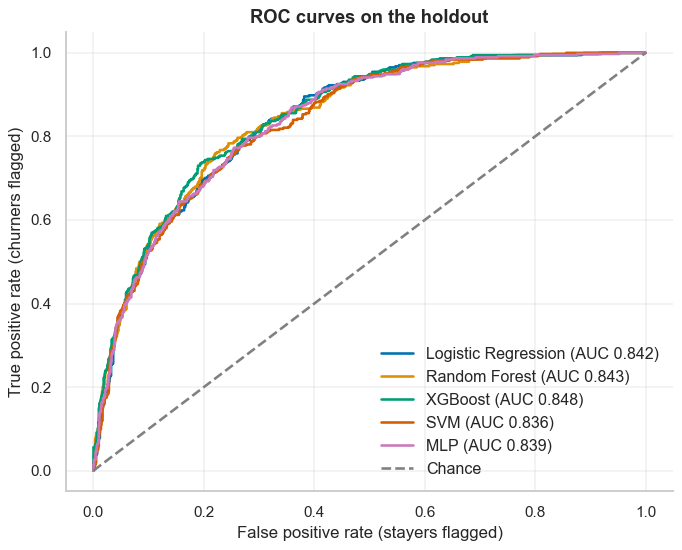

In [20]:
# Comparative ROC visualization (sized to stay legible at report width).
fig_roc, ax_roc = plt.subplots(figsize=(6.4, 5.2))
for model_name, roc_data in roc_curves.items():
    ax_roc.plot(
        roc_data["fpr"],
        roc_data["tpr"],
        label=f"{model_name} (AUC {roc_data['auc']:.3f})",
        color=model_color(model_name),
    )

ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax_roc.set_xlabel("False positive rate (stayers flagged)")
ax_roc.set_ylabel("True positive rate (churners flagged)")
ax_roc.set_title("ROC curves on the holdout")
ax_roc.legend(loc="lower right", fontsize=10.5)
fig_roc.tight_layout()
save_figure(fig_roc, "model_roc_comparison")
plt.show()


**Figure 4. ROC curves on the holdout.** The horizontal axis is the false-positive rate and the vertical axis the true-positive rate. The five AUCs span about 0.836–0.848. Close aggregate ranking scores do not mean the models assign the same probability to an individual or produce equivalent operational outcomes.

<a id="evaluation"></a>
## CRISP-DM: Evaluation

The following analyses make the scope of the comparison explicit:

1. **CV diagnostics:** scores for tuned configurations on the same folds used in selection. Preprocessing is refitted, but these are not independent estimates of the selection procedure.
2. **Bootstrap intervals:** 1,000 stratified holdout resamples, conditional on the fitted models and observed class counts.
3. **Pairwise AUC comparisons:** ten exploratory DeLong and paired-bootstrap comparisons. P-values are unadjusted for multiplicity; non-significance is not equivalence.
4. **Probability quality:** Brier loss, reliability diagrams and a supplementary isotonic comparison.
5. **Threshold sensitivity:** observed errors under 91 cutoffs and three illustrative penalty ratios. The same holdout supplies both the minima and their reported performance.
6. **Internal sensitivity:** training gaps, learning curve, repeated CV, alternate split sizes and tenure cohorts. These reuse the benchmark and do not establish external or prospective validity.
7. **Explanation and cost:** permutation importance for the fixed XGBoost explanation model and machine-specific scoring time.

The surviving exports are indexed by the manifest. The temporal-limit note below explains why survival estimates are outside the supported analysis.

In [21]:
# Internal CV diagnostics for already-tuned configurations.
# Every fold refits preprocessing, but these data/folds were used for selection.
from sklearn.model_selection import cross_validate


def ranking_scores(estimator, X_fold):
    # AUC only needs a ranking. Use the decision function where the model has
    # one (SVM, logistic regression), as the tuning search did, and the
    # probability otherwise. For the SVM this avoids ties: in some folds its
    # Platt step maps a whole group of records to the same probability.
    if hasattr(estimator, "decision_function"):
        return estimator.decision_function(X_fold)
    return estimator.predict_proba(X_fold)[:, 1]


def probability_metrics(estimator, X_fold, y_fold):
    probabilities = estimator.predict_proba(X_fold)[:, 1]
    decisions = (probabilities >= 0.50).astype(int)
    return {
        "precision": precision_score(y_fold, decisions, zero_division=0),
        "recall": recall_score(y_fold, decisions, zero_division=0),
        "f1": f1_score(y_fold, decisions, zero_division=0),
        "roc_auc": roc_auc_score(y_fold, ranking_scores(estimator, X_fold)),
    }


def ranking_auc(estimator, X_fold, y_fold):
    return roc_auc_score(y_fold, ranking_scores(estimator, X_fold))


CV_METRICS = ("precision", "recall", "f1", "roc_auc")
cv_rows = []
for model_name, estimator in best_estimators.items():
    cv_results = cross_validate(
        clone(estimator), X_train, y_train_enc,
        cv=cv_strategy, scoring=probability_metrics, n_jobs=-1,
        return_train_score=False,
    )
    row = {"model": model_name}
    for metric_name in CV_METRICS:
        scores = cv_results[f"test_{metric_name}"]
        row[f"{metric_name}_cv_mean"] = float(np.mean(scores))
        row[f"{metric_name}_cv_std"] = float(np.std(scores, ddof=1))
    cv_rows.append(row)

cv_scores_df = (
    pd.DataFrame(cv_rows).set_index("model")
    .sort_values("roc_auc_cv_mean", ascending=False)
)
display(cv_scores_df.round(4))
cv_scores_df.round(6).to_csv(TABLES_DIR / "model_cv_scores.csv")
print(f"Saved {TABLES_DIR / 'model_cv_scores.csv'}")
print("Precision, recall and F1 use probability >= 0.50 for every model; AUC uses each model's ranking score.")
print("Internal diagnostics only: these folds/data were also used for hyperparameter selection.")

,precision_cv_mean,precision_cv_std,recall_cv_mean,recall_cv_std,f1_cv_mean,f1_cv_std,roc_auc_cv_mean,roc_auc_cv_std
model,,,,,,,,
XGBoost,0.6694,0.0318,0.5298,0.0289,0.5911,0.0260,0.8510,0.0132
Random Forest,0.6778,0.0347,0.4977,0.0143,0.5735,0.0148,0.8480,0.0106
Logistic Regression,0.6540,0.0299,0.5472,0.0457,0.5952,0.0341,0.8463,0.0142
MLP,0.6699,0.0162,0.5298,0.0470,0.5909,0.0317,0.8452,0.0134
SVM,0.0934,0.2088,0.1652,0.3694,0.1193,0.2668,0.8419,0.0101


Saved thesis_exports/tables/model_cv_scores.csv
Precision, recall and F1 use probability >= 0.50 for every model; AUC uses each model's ranking score.
Internal diagnostics only: these folds/data were also used for hyperparameter selection.


### Uncertainty in the holdout estimates

The fitted models' predictions are resampled 1,000 times with replacement, holding the class counts at 374 churners and 1,035 non-churners. These intervals describe sampling variability conditional on those fitted models and class counts. They exclude uncertainty from retuning, alternative data construction and external populations.

For example, XGBoost's holdout AUC is about 0.848 with a 95% percentile interval of 0.825–0.870. Interval overlap by itself is neither a test of differences nor evidence of equivalence.

In [22]:
# Phase 2 - Task 2.1: bootstrap 95% CIs on every holdout metric.
#
# 1,000 stratified resamples (with replacement) of the held-out test
# set. For each resample we recompute precision / recall / F1 (at the
# default 0.5 threshold) and ROC-AUC. The 2.5 and 97.5 percentiles
# across resamples give a 95% CI on each metric.
#
# `np.random.default_rng(RANDOM_STATE)` keeps the bootstrap reproducible
# without disturbing the global numpy random state set earlier.

# `precision_score` / `recall_score` / `f1_score` / `roc_auc_score` are
# already imported in the modeling-dependencies cell above.

BOOT_N = 1000
BOOT_CI = (2.5, 97.5)
BOOT_THRESHOLD = 0.5

# Precompute per-model probability vectors once (test set never changes).
proba_by_model = {
    name: est.predict_proba(X_test)[:, 1]
    for name, est in best_estimators.items()
}

# Index pool for stratified resampling
y_test_arr = np.asarray(y_test_enc)
pos_idx = np.where(y_test_arr == 1)[0]
neg_idx = np.where(y_test_arr == 0)[0]
n_pos = pos_idx.size
n_neg = neg_idx.size

rng = np.random.default_rng(RANDOM_STATE)
boot_rows = []
ci_records = []

for model_name, y_proba in proba_by_model.items():
    metric_samples = {"precision": [], "recall": [], "f1": [], "roc_auc": []}

    for _ in range(BOOT_N):
        sampled_pos = rng.choice(pos_idx, size=n_pos, replace=True)
        sampled_neg = rng.choice(neg_idx, size=n_neg, replace=True)
        idx = np.concatenate([sampled_pos, sampled_neg])
        y_boot = y_test_arr[idx]
        p_boot = y_proba[idx]
        yhat_boot = (p_boot >= BOOT_THRESHOLD).astype(int)

        # `precision`/`recall`/`f1` with zero_division=0 to keep degenerate
        # resamples (rare) from raising; AUC is well-defined as long as
        # both classes are present, which stratification guarantees.
        metric_samples["precision"].append(
            precision_score(y_boot, yhat_boot, zero_division=0)
        )
        metric_samples["recall"].append(
            recall_score(y_boot, yhat_boot, zero_division=0)
        )
        metric_samples["f1"].append(
            f1_score(y_boot, yhat_boot, zero_division=0)
        )
        metric_samples["roc_auc"].append(roc_auc_score(y_boot, p_boot))

    record = {"model": model_name}
    for metric_name, samples in metric_samples.items():
        arr = np.asarray(samples, dtype=float)
        low, high = np.percentile(arr, BOOT_CI)
        record[f"{metric_name}_boot_mean"] = float(arr.mean())
        record[f"{metric_name}_ci_low"] = float(low)
        record[f"{metric_name}_ci_high"] = float(high)
    ci_records.append(record)

bootstrap_ci_df = pd.DataFrame(ci_records).set_index("model")

# Rebuild metrics_df from the immutable point-estimate frame rather than
# mutating it. A left merge on `model` preserves the ROC-AUC ordering set
# in the holdout-evaluation cell and is safe to run any number of times;
# the previous `set_index(...).join(...)` raised on a second run.
METRIC_CI_PAIRS = [
    ("precision", "precision"),
    ("recall", "recall"),
    ("f1_score", "f1"),
    ("roc_auc", "roc_auc"),
]
METRICS_CI_COLUMNS = ["model"]
for _m, _ci_key in METRIC_CI_PAIRS:
    METRICS_CI_COLUMNS += [_m, f"{_ci_key}_ci_low", f"{_ci_key}_ci_high", f"{_ci_key}_boot_mean"]

metrics_df = base_metrics_df.merge(
    bootstrap_ci_df.reset_index(), on="model", how="left"
)[METRICS_CI_COLUMNS]

# Format a display copy with [low, high] strings; export raw numbers.
display_df = metrics_df.copy()
for m, ci_key in METRIC_CI_PAIRS:
    display_df[m] = display_df.apply(
        lambda r: f"{r[m]:.3f} [{r[f'{ci_key}_ci_low']:.3f}, {r[f'{ci_key}_ci_high']:.3f}]",
        axis=1,
    )
display_df = display_df[["model", "precision", "recall", "f1_score", "roc_auc"]]
display(display_df)

# `model_comparison_metrics.csv` is written exactly once, in the
# calibration cell below, after the Brier columns are attached. Writing an
# intermediate copy here left a complete-looking but Brier-less export on
# disk whenever a reader stopped part-way through the Evaluation phase.
print("Bootstrap CIs attached to metrics_df (CSV is written once, after calibration).")


,model,precision,recall,f1_score,roc_auc
0,XGBoost,"0.673 [0.623, 0.722]","0.529 [0.481, 0.586]","0.593 [0.549, 0.636]","0.848 [0.825, 0.870]"
1,Random Forest,"0.675 [0.631, 0.722]","0.500 [0.449, 0.551]","0.575 [0.531, 0.616]","0.843 [0.822, 0.864]"
2,Logistic Regression,"0.657 [0.613, 0.703]","0.559 [0.505, 0.607]","0.604 [0.561, 0.646]","0.842 [0.820, 0.862]"
3,MLP,"0.640 [0.598, 0.685]","0.551 [0.497, 0.602]","0.592 [0.546, 0.633]","0.839 [0.817, 0.861]"
4,SVM,"0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.836 [0.814, 0.858]"


Bootstrap CIs attached to metrics_df (CSV is written once, after calibration).


### Comparing AUC differences

DeLong and paired bootstrap use the same holdout records, so they are complementary calculations on one sample, not independent replications. For XGBoost versus Logistic Regression and Random Forest, the original DeLong p-values are about 0.033 and 0.039, with differences of about 0.0065 and 0.0046 AUC.

The table reports all ten pairwise comparisons without a multiple-comparison adjustment. Read these as exploratory results with their effect sizes. No equivalence margin or operational outcome was specified, so neither a large p-value nor a small AUC difference establishes equal business performance.

In [23]:
# Phase 2 - Task 2.2: pairwise AUC tests across all five tuned models.
#
# We apply two procedures to the same sample and report both:
#
#   1. DeLong's nonparametric test on the ROC-AUC difference (Sun & Xu,
#      2014 midrank implementation). Gives a closed-form z-statistic and
#      two-sided p-value under the asymptotic normal approximation.
#
#   2. A paired bootstrap (1,000 stratified resamples using the same
#      indices for both models). Reports the empirical 95% CI on the
#      AUC difference and a two-sided p-value (the share of resamples
#      whose difference falls on the opposite side of zero from the
#      observed difference, doubled).
#
# A non-rejection in BOTH procedures is strong evidence that the AUCs
# are statistically indistinguishable on this holdout.

from itertools import combinations
from scipy import stats as _scipy_stats


def _midrank(x):
    """Midrank (average rank in ties) using a stable O(n log n) routine.

    Mirrors the helper described in Sun & Xu (2014) section II.A.
    """
    J = np.argsort(x, kind="mergesort")
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1  # 1-indexed midrank
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def delong_roc_variance(labels, scores_matrix):
    """Compute AUCs and the DeLong covariance matrix.

    Parameters
    ----------
    labels : (n,) array, 0/1
    scores_matrix : (n_models, n) array of predicted scores

    Returns
    -------
    aucs : (n_models,) array
    cov  : (n_models, n_models) covariance matrix of the AUC estimators
    """
    labels = np.asarray(labels)
    scores_matrix = np.asarray(scores_matrix)
    pos = labels == 1
    neg = labels == 0
    n_pos = pos.sum()
    n_neg = neg.sum()
    k = scores_matrix.shape[0]

    tx = np.empty((k, n_pos))
    ty = np.empty((k, n_neg))
    tz = np.empty((k, n_pos + n_neg))
    for r in range(k):
        tx[r] = _midrank(scores_matrix[r, pos])
        ty[r] = _midrank(scores_matrix[r, neg])
        tz[r] = _midrank(scores_matrix[r])

    aucs = (tz[:, pos].sum(axis=1) / (n_pos * n_neg)) - (n_pos + 1.0) / (2.0 * n_neg)

    v01 = (tz[:, pos] - tx[:, :]) / n_neg
    v10 = 1.0 - (tz[:, neg] - ty[:, :]) / n_pos

    sx = np.cov(v01, ddof=1)
    sy = np.cov(v10, ddof=1)
    # numpy.cov returns scalar for k=1; force 2D
    sx = np.atleast_2d(sx)
    sy = np.atleast_2d(sy)

    cov = sx / n_pos + sy / n_neg
    return aucs, cov


def delong_pvalue(labels, scores_a, scores_b):
    """Two-sided DeLong p-value for AUC(scores_a) vs AUC(scores_b)."""
    scores = np.vstack([scores_a, scores_b])
    aucs, cov = delong_roc_variance(labels, scores)
    diff = aucs[0] - aucs[1]
    var = cov[0, 0] + cov[1, 1] - 2.0 * cov[0, 1]
    if var <= 0:
        # Degenerate (identical scores): difference is exactly zero.
        z = 0.0
        p = 1.0
    else:
        z = diff / np.sqrt(var)
        p = 2.0 * (1.0 - _scipy_stats.norm.cdf(abs(z)))
    return float(diff), float(z), float(p)


PAIR_BOOT_N = 1000

pair_rows = []
rng_pair = np.random.default_rng(RANDOM_STATE + 1)  # distinct stream from 2.1

y_arr = np.asarray(y_test_enc)
pos_idx_pair = np.where(y_arr == 1)[0]
neg_idx_pair = np.where(y_arr == 0)[0]

for name_a, name_b in combinations(best_estimators.keys(), 2):
    pa = proba_by_model[name_a]
    pb = proba_by_model[name_b]

    diff, z, p_delong = delong_pvalue(y_arr, pa, pb)

    # Paired bootstrap: same resampled index for both models, stratified.
    diffs = np.empty(PAIR_BOOT_N, dtype=float)
    for k in range(PAIR_BOOT_N):
        sampled_pos = rng_pair.choice(pos_idx_pair, size=pos_idx_pair.size, replace=True)
        sampled_neg = rng_pair.choice(neg_idx_pair, size=neg_idx_pair.size, replace=True)
        idx = np.concatenate([sampled_pos, sampled_neg])
        yb = y_arr[idx]
        diffs[k] = roc_auc_score(yb, pa[idx]) - roc_auc_score(yb, pb[idx])

    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    # Two-sided empirical p-value
    if diff >= 0:
        tail = (diffs <= 0).mean()
    else:
        tail = (diffs >= 0).mean()
    p_boot = float(min(1.0, 2.0 * tail))

    pair_rows.append(
        {
            "model_a": name_a,
            "model_b": name_b,
            "auc_a": roc_auc_score(y_arr, pa),
            "auc_b": roc_auc_score(y_arr, pb),
            "auc_diff": diff,
            "delong_z": z,
            "delong_p_value": p_delong,
            "boot_diff_ci_low": float(ci_low),
            "boot_diff_ci_high": float(ci_high),
            "boot_p_value": p_boot,
        }
    )

auc_pairwise_df = pd.DataFrame(pair_rows)
display(auc_pairwise_df.round(4))

auc_pairwise_df.round(6).to_csv(
    TABLES_DIR / "model_auc_pairwise_tests.csv", index=False
)
print(f"Saved {TABLES_DIR / 'model_auc_pairwise_tests.csv'}")

# Quick on-screen verdict so the cell output reads naturally.
print()
for r in pair_rows:
    verdict = "NOT significant" if r["delong_p_value"] >= 0.05 else "significant"
    print(
        f"{r['model_a']} vs {r['model_b']}: "
        f"ΔAUC={r['auc_diff']:+.4f}  "
        f"DeLong p={r['delong_p_value']:.3f}  "
        f"boot p={r['boot_p_value']:.3f}  ({verdict} at α=0.05)"
    )

,model_a,model_b,auc_a,auc_b,auc_diff,delong_z,delong_p_value,boot_diff_ci_low,boot_diff_ci_high,boot_p_value
0,Logistic Regression,Random Forest,0.8416,0.8434,-0.0018,-0.5415,0.5882,-0.0084,0.0049,0.620
1,Logistic Regression,XGBoost,0.8416,0.8480,-0.0065,-2.1261,0.0335,-0.0120,-0.0011,0.024
2,Logistic Regression,SVM,0.8416,0.8356,0.0059,2.0148,0.0439,0.0001,0.0117,0.048
3,Logistic Regression,MLP,0.8416,0.8391,0.0024,1.5972,0.1102,-0.0006,0.0053,0.116
4,Random Forest,XGBoost,0.8434,0.8480,-0.0046,-2.0669,0.0387,-0.0090,-0.0002,0.042
5,Random Forest,SVM,0.8434,0.8356,0.0077,2.0320,0.0422,0.0002,0.0153,0.040
6,Random Forest,MLP,0.8434,0.8391,0.0043,1.2451,0.2131,-0.0024,0.0107,0.214
7,XGBoost,SVM,0.8480,0.8356,0.0124,3.2013,0.0014,0.0052,0.0203,0.000
8,XGBoost,MLP,0.8480,0.8391,0.0089,2.6160,0.0089,0.0022,0.0158,0.014
9,SVM,MLP,0.8356,0.8391,-0.0035,-1.1771,0.2391,-0.0093,0.0018,0.208


Saved thesis_exports/tables/model_auc_pairwise_tests.csv

Logistic Regression vs Random Forest: ΔAUC=-0.0018  DeLong p=0.588  boot p=0.620  (NOT significant at α=0.05)
Logistic Regression vs XGBoost: ΔAUC=-0.0065  DeLong p=0.033  boot p=0.024  (significant at α=0.05)
Logistic Regression vs SVM: ΔAUC=+0.0059  DeLong p=0.044  boot p=0.048  (significant at α=0.05)
Logistic Regression vs MLP: ΔAUC=+0.0024  DeLong p=0.110  boot p=0.116  (NOT significant at α=0.05)
Random Forest vs XGBoost: ΔAUC=-0.0046  DeLong p=0.039  boot p=0.042  (significant at α=0.05)
Random Forest vs SVM: ΔAUC=+0.0077  DeLong p=0.042  boot p=0.040  (significant at α=0.05)
Random Forest vs MLP: ΔAUC=+0.0043  DeLong p=0.213  boot p=0.214  (NOT significant at α=0.05)
XGBoost vs SVM: ΔAUC=+0.0124  DeLong p=0.001  boot p=0.000  (significant at α=0.05)
XGBoost vs MLP: ΔAUC=+0.0089  DeLong p=0.009  boot p=0.014  (significant at α=0.05)
SVM vs MLP: ΔAUC=-0.0035  DeLong p=0.239  boot p=0.208  (NOT significant at α=0.05)


### Probability quality

Brier score is the mean squared error of probabilities against binary outcomes. Its decomposition includes calibration, discrimination and uncertainty; a lower score alone does not establish better calibration. The binned reliability diagrams supply a complementary view, with limited precision in sparse bins.

The original holdout Brier scores range from about 0.135 for XGBoost to 0.160 for SVM. No confidence interval for their differences is computed. These are descriptive comparisons and do not select the explanation model. Isotonic calibration is fitted within training data and evaluated on the holdout as a supplementary result.

Method reference: [scikit-learn probability calibration guide](https://scikit-learn.org/1.8/modules/calibration.html).

,brier_score,brier_score_isotonic,brier_improvement
model,,,
Logistic Regression,0.1383,0.1388,-0.0004
Random Forest,0.1363,0.1366,-0.0003
XGBoost,0.1348,0.1345,0.0003
SVM,0.1603,0.1404,0.0199
MLP,0.1390,0.1380,0.0011


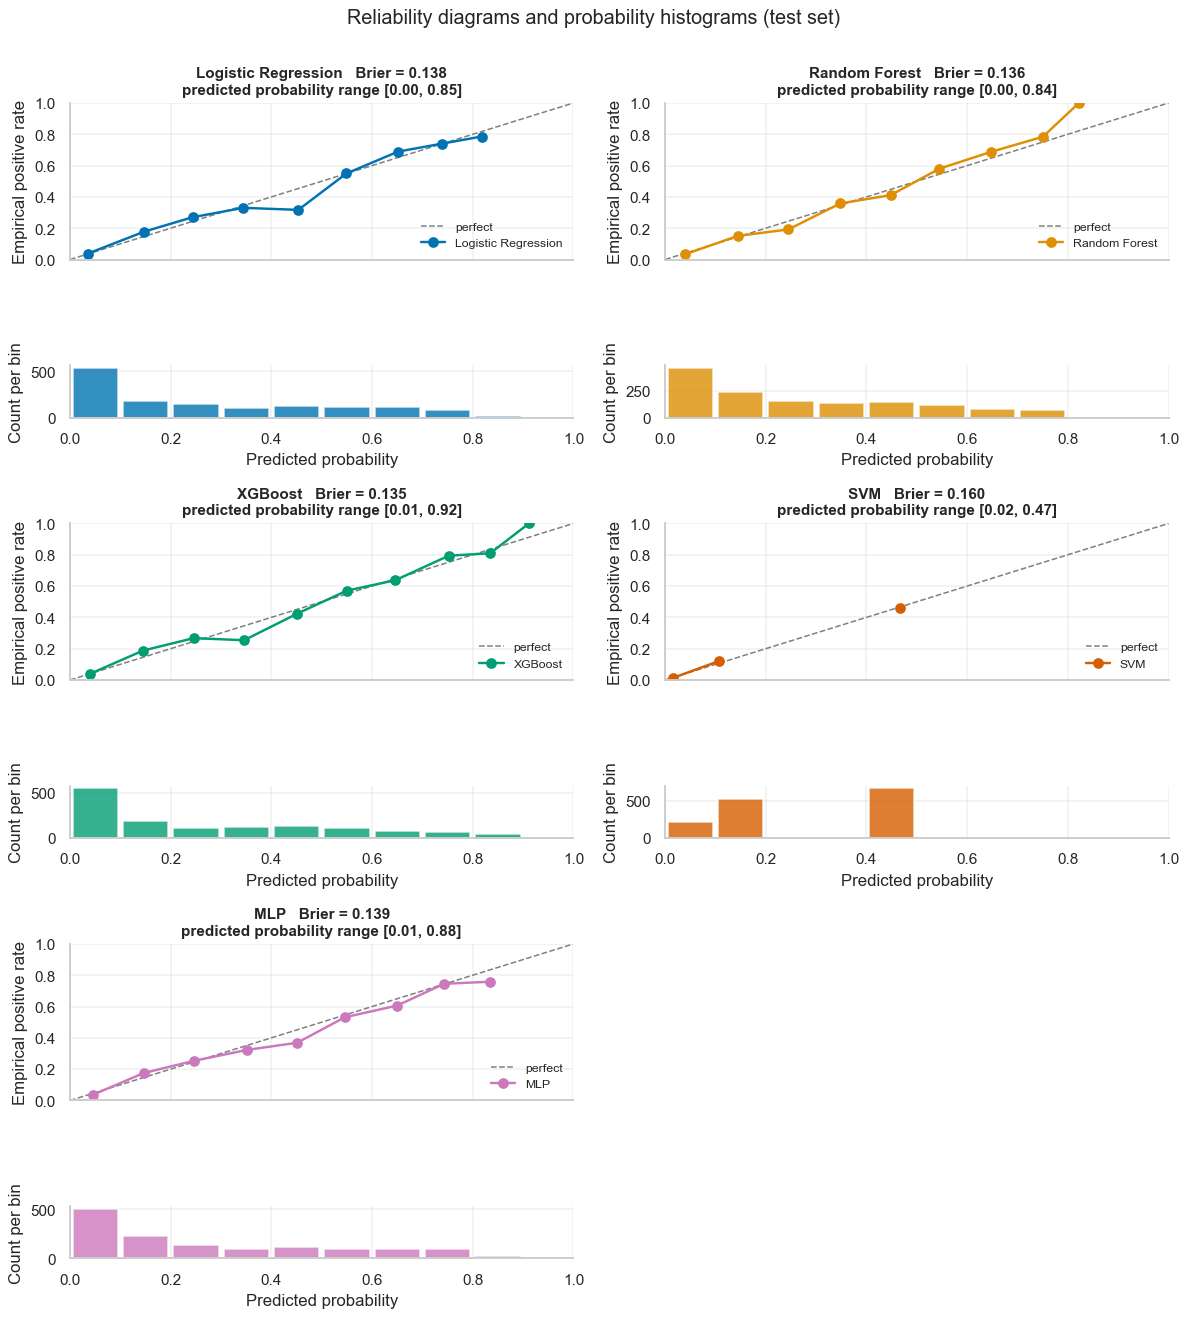

Wrote thesis_exports/tables/model_comparison_metrics.csv (point estimates + CIs + Brier).
Saved thesis_exports/figures/model_calibration.png and .pdf
model_comparison_metrics.csv schema OK -- 5 rows, 19 columns.


In [24]:
# Phase 2 - Task 2.5: calibration analysis.
#
# For each tuned model:
#   - Compute Brier score on the holdout test set.
#   - Draw a 10-bin reliability diagram (uniform-width bins) showing
#     mean predicted probability vs empirical positive rate per bin,
#     plus the y=x perfect-calibration reference.
#
# We also fit an isotonic re-calibrator on the training fold for each
# model using CalibratedClassifierCV, which refits the pipeline inside
# training folds. Pre/post Brier is evaluated on the same holdout.
# This is informational only — the headline metrics stick with the
# raw tuned models so the comparison upstream stays consistent.

from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibratedClassifierCV

N_CAL_BINS = 10
bin_edges = np.linspace(0.0, 1.0, N_CAL_BINS + 1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

calibration_rows = []
reliability_curves = {}  # name -> (mean_pred_per_bin, frac_pos_per_bin, count_per_bin)

for model_name, y_proba in proba_by_model.items():
    brier = brier_score_loss(y_test_enc, y_proba)

    mean_pred = np.full(N_CAL_BINS, np.nan)
    frac_pos = np.full(N_CAL_BINS, np.nan)
    counts = np.zeros(N_CAL_BINS, dtype=int)
    # `digitize` with `right=False` puts probas in [edges[i], edges[i+1]);
    # clamp the final bin to include 1.0.
    bin_idx = np.clip(np.digitize(y_proba, bin_edges) - 1, 0, N_CAL_BINS - 1)
    for b in range(N_CAL_BINS):
        mask = bin_idx == b
        counts[b] = int(mask.sum())
        if counts[b] > 0:
            mean_pred[b] = y_proba[mask].mean()
            frac_pos[b] = (np.asarray(y_test_enc)[mask] == 1).mean()

    reliability_curves[model_name] = (mean_pred, frac_pos, counts)

    # Isotonic re-calibration (5-fold CV internal to CalibratedClassifierCV).
    cal_est = CalibratedClassifierCV(
        estimator=clone(best_estimators[model_name]),
        method="isotonic",
        cv=5,
    )
    cal_est.fit(X_train, y_train_enc)
    proba_cal = cal_est.predict_proba(X_test)[:, 1]
    brier_post = brier_score_loss(y_test_enc, proba_cal)

    calibration_rows.append(
        {
            "model": model_name,
            "brier_score": float(brier),
            "brier_score_isotonic": float(brier_post),
            "brier_improvement": float(brier - brier_post),
        }
    )

calibration_df = pd.DataFrame(calibration_rows).set_index("model")
display(calibration_df.round(4))

# Layout: model panels flow down a 2-column grid instead of across a single
# row. Five models in one row produced a 22.5 x 7.2 inch strip that renders
# ~1.9 inches tall in a thesis column, with unreadable titles. Each block is
# a reliability diagram over its own probability histogram.
#
# Each panel title also reports the model's predicted-probability range, so
# the SVM's compressed range (its probabilities stay below 0.5 on this holdout;
# see the note after the holdout table) is visible on the figure itself rather than only in the
# accompanying text.
n_models = len(reliability_curves)
CAL_COLS = 2
cal_block_rows = int(np.ceil(n_models / CAL_COLS))

fig_cal, axes_cal = plt.subplots(
    2 * cal_block_rows, CAL_COLS,
    figsize=(11, 4.0 * cal_block_rows),
    gridspec_kw={"height_ratios": [3, 1] * cal_block_rows},
    squeeze=False,
)

for pos, (name, (mean_pred, frac_pos, counts)) in enumerate(reliability_curves.items()):
    block_row, block_col = divmod(pos, CAL_COLS)
    ax_top = axes_cal[2 * block_row, block_col]
    ax_bot = axes_cal[2 * block_row + 1, block_col]
    panel_color = model_color(name)
    p_vec = proba_by_model[name]

    ax_top.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="perfect")
    ax_top.plot(mean_pred, frac_pos, marker="o", linewidth=1.6, color=panel_color, label=name)
    ax_top.set_xlim(0, 1)
    ax_top.set_ylim(0, 1)
    ax_top.set_ylabel("Empirical positive rate")
    ax_top.set_title(
        f"{name}   Brier = {calibration_df.loc[name, 'brier_score']:.3f}\n"
        f"predicted probability range [{p_vec.min():.2f}, {p_vec.max():.2f}]",
        fontsize=10,
    )
    ax_top.grid(alpha=0.3)
    ax_top.legend(loc="lower right", fontsize=8)
    ax_top.tick_params(labelbottom=False)

    ax_bot.bar(bin_centers, counts, width=(bin_edges[1] - bin_edges[0]) * 0.9,
               color=panel_color, alpha=0.8)
    ax_bot.set_xlim(0, 1)
    ax_bot.set_xlabel("Predicted probability")
    ax_bot.set_ylabel("Count per bin")
    ax_bot.grid(alpha=0.3)

# Blank any unused block in the final grid row (5 models in a 2-wide grid).
for pos in range(n_models, cal_block_rows * CAL_COLS):
    block_row, block_col = divmod(pos, CAL_COLS)
    axes_cal[2 * block_row, block_col].axis("off")
    axes_cal[2 * block_row + 1, block_col].axis("off")

fig_cal.suptitle("Reliability diagrams and probability histograms (test set)", y=1.0, fontsize=13)
fig_cal.tight_layout()

save_figure(fig_cal, "model_calibration")
plt.show()

# Rebuild the full holdout metrics table in one pass -- point estimates,
# bootstrap CIs, then Brier scores -- and write the CSV exactly once, here.
# Rebuilding (rather than merging into whatever `metrics_df` currently holds)
# means re-running this cell cannot produce `brier_score_x`/`brier_score_y`
# duplicates and silently corrupt the export.
METRICS_EXPORT_COLUMNS = METRICS_CI_COLUMNS + ["brier_score", "brier_score_isotonic"]

metrics_df = (
    base_metrics_df
    .merge(bootstrap_ci_df.reset_index(), on="model", how="left")
    .merge(
        calibration_df.reset_index()[["model", "brier_score", "brier_score_isotonic"]],
        on="model",
        how="left",
    )
)[METRICS_EXPORT_COLUMNS]

metrics_df.round(6).to_csv(TABLES_DIR / "model_comparison_metrics.csv", index=False)
print(f"Wrote {TABLES_DIR / 'model_comparison_metrics.csv'} (point estimates + CIs + Brier).")
print(f"Saved {FIGURES_DIR / 'model_calibration.png'} and .pdf")

# Schema check for model_comparison_metrics.csv, mirroring the two SHAP
# schema checks later in the notebook. A stale or half-written export
# cannot survive a re-run silently.
_loaded_metrics = pd.read_csv(TABLES_DIR / "model_comparison_metrics.csv")

assert list(_loaded_metrics.columns) == METRICS_EXPORT_COLUMNS, (
    f"model_comparison_metrics columns drifted: {list(_loaded_metrics.columns)}"
)
assert len(_loaded_metrics) == len(metrics_df) == len(best_estimators), (
    f"row count mismatch: csv has {len(_loaded_metrics)}, in-memory has "
    f"{len(metrics_df)}, tuned models {len(best_estimators)}"
)
assert _loaded_metrics["model"].is_unique, "duplicate model rows in the export"
assert pd.api.types.is_string_dtype(_loaded_metrics["model"]), "model must be string-like"

_numeric_metric_cols = [c for c in METRICS_EXPORT_COLUMNS if c != "model"]
for _col in _numeric_metric_cols:
    assert pd.api.types.is_numeric_dtype(_loaded_metrics[_col]), f"{_col} must be numeric"
    assert _loaded_metrics[_col].notna().all(), f"NaN found in {_col}"
    assert _loaded_metrics[_col].between(0.0, 1.0).all(), (
        f"{_col} outside [0, 1] -- every column here is a probability-scale score"
    )

print(
    f"model_comparison_metrics.csv schema OK -- {len(_loaded_metrics)} rows, "
    f"{len(METRICS_EXPORT_COLUMNS)} columns."
)


**Figure 5. Reliability diagrams and probability histograms.** Each upper panel compares mean probability with observed churn frequency in ten equal-width bins. The lower panel shows how many predictions fall in those ranges. Sparse bins should receive less interpretive weight. XGBoost has the lowest observed Brier loss, but calibration superiority is not established by that score. The SVM's narrow probability range explains why its 0.50 cutoff flags no records in this holdout.

### Thresholds make the outreach burden visible

Each fitted model is evaluated at 91 thresholds from 0.05 to 0.95. False negatives and false positives receive illustrative penalties of 1:1, 3:1 and 10:1. These weights are assumptions, not measured financial costs.

For XGBoost, the observed 10:1 grid minimum is 0.07: 364 true positives, 584 false positives and 10 missed churners, compared with 198 true positives, 96 false positives and 176 misses at 0.50. Recall rises from about 53% to 97%, while precision falls from about 67% to 38%. This shows the added contact burden; it says nothing about how many contacted customers would stay because of a message.

The minima are selected and evaluated on the same holdout. They are descriptive sample/grid minima, not unbiased estimates of future policy performance. A boundary minimum, such as SVM at 0.05 for 10:1, is not a demonstrated global optimum. The legacy filename `threshold_cost_optima.csv` is retained for artifact compatibility and has this restricted meaning throughout.

Method reference: [scikit-learn threshold-selection guide](https://scikit-learn.org/1.8/modules/classification_threshold.html).

,model,c_fn,c_fp,best_threshold,min_cost,precision_at_best,recall_at_best,f1_at_best
0,Logistic Regression,1,1,0.50,0.1945,0.6572,0.5588,0.6040
1,Logistic Regression,3,1,0.22,0.3634,0.4861,0.8396,0.6157
2,Logistic Regression,10,1,0.08,0.4876,0.3897,0.9679,0.5556
3,Random Forest,1,1,0.48,0.1945,0.6656,0.5374,0.5947
4,Random Forest,3,1,0.32,0.3542,0.5513,0.7620,0.6397
5,Random Forest,10,1,0.13,0.5138,0.4112,0.9412,0.5724
6,XGBoost,1,1,0.50,0.1930,0.6735,0.5294,0.5928
7,XGBoost,3,1,0.35,0.3549,0.5726,0.7380,0.6449
8,XGBoost,10,1,0.07,0.4855,0.3840,0.9733,0.5507
9,SVM,1,1,0.47,0.2654,0.0000,0.0000,0.0000


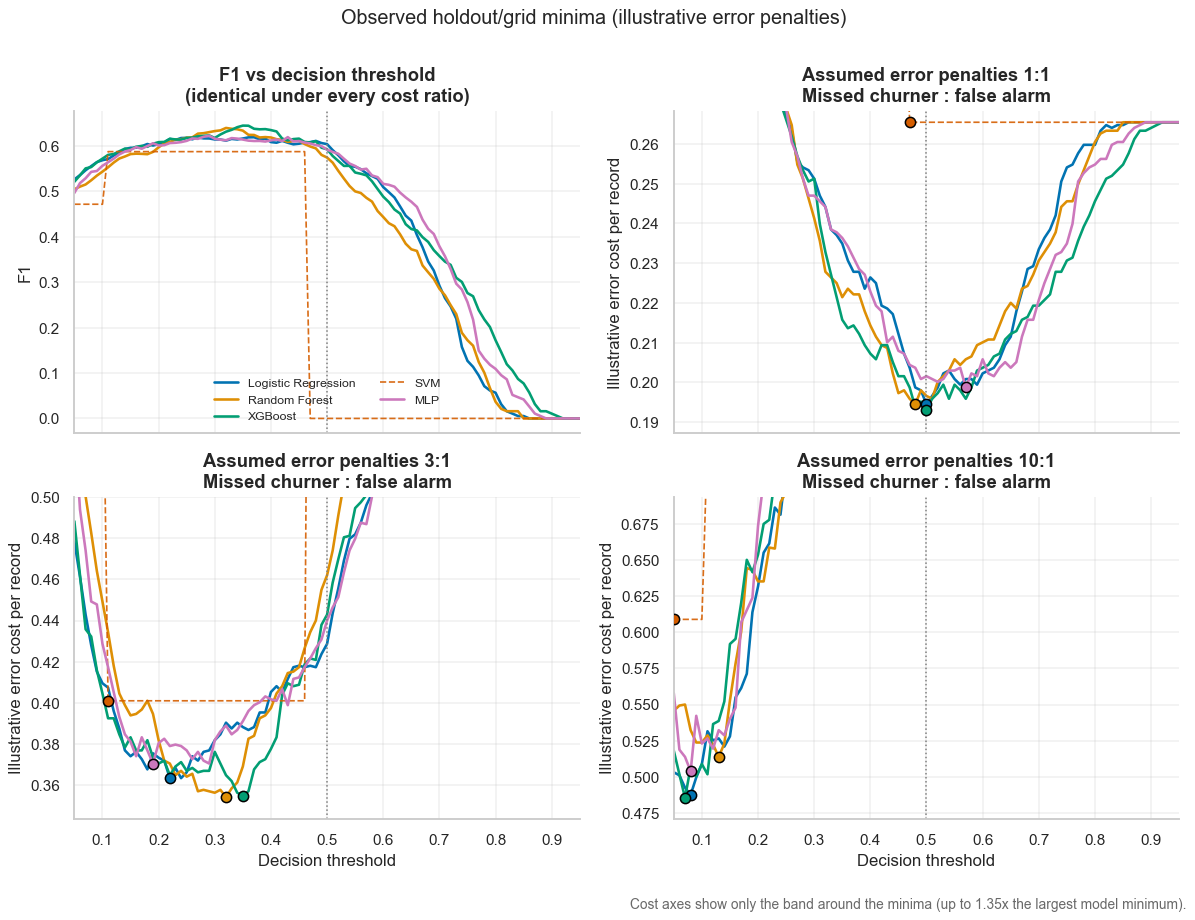

Saved threshold sweeps for 5 models in thesis_exports/tables.
Saved thesis_exports/figures/threshold_cost_curves.png and .pdf


In [25]:
# Descriptive threshold sensitivity on the same holdout used for reporting.
#
# For each tuned model we sweep the decision threshold from 0.05 to 0.95
# in steps of 0.01 and record:
#
#   * precision, recall, F1 at each threshold;
#   * observed normalized error cost
#         cost = (c_fn * FN + c_fp * FP) / n_test
#     under three illustrative false-negative : false-positive ratios:
#         1:1  -- symmetric (default loss),
#         3:1  -- an assumed threefold penalty for a false negative,
#         10:1 -- an assumed tenfold penalty for a false negative.
# These are error penalties, not measured campaign costs or treatment effects.
# Minima below are observed sample/grid minima, not validated policies.
#
# We export one CSV per model (threshold_sweep_<model>.csv) and a single
# four-panel figure (threshold_cost_curves.png/.pdf): one F1-vs-threshold
# panel (F1 does not depend on the cost ratio, so one panel replaces the
# three identical copies the earlier layout drew) plus one illustrative-cost
# panel per cost ratio. The conventional 0.5 cut and the cost-minimizing
# threshold per cost ratio are annotated.

# precision_score / recall_score / f1_score are already imported in the
# modeling-dependencies cell above.

COST_RATIOS = [(1, 1), (3, 1), (10, 1)]   # (c_fn, c_fp)
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 3)

y_arr = np.asarray(y_test_enc)
n_test = y_arr.size
pos_mask = y_arr == 1
neg_mask = ~pos_mask

threshold_records = {}        # model_name -> DataFrame
cost_optima = []              # legacy schema: observed minima on this sample/grid

for model_name, y_proba in proba_by_model.items():
    rows = []
    for t in THRESHOLDS:
        yhat = (y_proba >= t).astype(int)
        tp = int(((yhat == 1) & pos_mask).sum())
        fp = int(((yhat == 1) & neg_mask).sum())
        tn = int(((yhat == 0) & neg_mask).sum())
        fn = int(((yhat == 0) & pos_mask).sum())

        row = {
            "threshold": float(t),
            "tp": tp, "fp": fp, "tn": tn, "fn": fn,
            "precision": precision_score(y_arr, yhat, zero_division=0),
            "recall":    recall_score(y_arr, yhat, zero_division=0),
            "f1":        f1_score(y_arr, yhat, zero_division=0),
        }
        for c_fn, c_fp in COST_RATIOS:
            row[f"cost_{c_fn}_{c_fp}"] = (c_fn * fn + c_fp * fp) / n_test
        rows.append(row)

    df_t = pd.DataFrame(rows)
    threshold_records[model_name] = df_t

    safe_name = model_name.lower().replace(" ", "_")
    df_t.round(6).to_csv(
        TABLES_DIR / f"threshold_sweep_{safe_name}.csv", index=False
    )

    for c_fn, c_fp in COST_RATIOS:
        col = f"cost_{c_fn}_{c_fp}"
        idx_best = df_t[col].idxmin()
        cost_optima.append({
            "model": model_name,
            "c_fn": c_fn,
            "c_fp": c_fp,
            "best_threshold": float(df_t.loc[idx_best, "threshold"]),
            "min_cost": float(df_t.loc[idx_best, col]),
            "precision_at_best": float(df_t.loc[idx_best, "precision"]),
            "recall_at_best":    float(df_t.loc[idx_best, "recall"]),
            "f1_at_best":        float(df_t.loc[idx_best, "f1"]),
        })

threshold_optima_df = pd.DataFrame(cost_optima)
threshold_optima_df.round(6).to_csv(
    TABLES_DIR / "threshold_cost_optima.csv", index=False
)
display(threshold_optima_df.round(4))

# Plot: one F1 panel + one illustrative-cost panel per cost ratio, on a 2x2
# grid. The SVM is drawn thin and dashed because its probabilities fall in
# a few tight groups, so its curves are step functions that would otherwise
# dominate every panel.
SVM_LABEL = "SVM"


def _threshold_line_style(name):
    if name == SVM_LABEL:
        return {"linestyle": "--", "linewidth": 1.1, "alpha": 0.9}
    return {"linestyle": "-", "linewidth": 1.7}


fig_t, axes_t = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
ax_f1 = axes_t[0, 0]
cost_axes = [axes_t[0, 1], axes_t[1, 0], axes_t[1, 1]]

for name, df_t in threshold_records.items():
    ax_f1.plot(
        df_t["threshold"], df_t["f1"], label=name,
        color=model_color(name), **_threshold_line_style(name),
    )
ax_f1.axvline(0.5, color="gray", linestyle=":", linewidth=1)
ax_f1.grid(alpha=0.3)
ax_f1.set_xlim(0.05, 0.95)
ax_f1.set_ylabel("F1")
ax_f1.set_title("F1 vs decision threshold\n(identical under every cost ratio)")
ax_f1.legend(loc="lower center", fontsize=8, ncol=2)

for ax_co, (c_fn, c_fp) in zip(cost_axes, COST_RATIOS):
    cost_col = f"cost_{c_fn}_{c_fp}"
    model_minima = {n: float(d[cost_col].min()) for n, d in threshold_records.items()}

    for name, df_t in threshold_records.items():
        ax_co.plot(
            df_t["threshold"], df_t[cost_col], label=name,
            color=model_color(name), **_threshold_line_style(name),
        )
        idx_best = df_t[cost_col].idxmin()
        ax_co.scatter(
            [df_t.loc[idx_best, "threshold"]], [df_t.loc[idx_best, cost_col]],
            color=model_color(name), edgecolor="black", zorder=5, s=45,
        )

    ax_co.axvline(0.5, color="gray", linestyle=":", linewidth=1)
    ax_co.grid(alpha=0.3)
    ax_co.set_xlim(0.05, 0.95)

    # Clip the cost axis to the decision-relevant band. Left to autoscale,
    # the far tails (predict-nobody / predict-everybody) set the range and
    # squash the five minima -- the only part of the curve anyone acts on --
    # into the bottom fifth of the panel.
    reference_minima = [v for n, v in model_minima.items() if n != SVM_LABEL]
    if not reference_minima:
        reference_minima = list(model_minima.values())
    y_lo = min(model_minima.values())
    y_hi = max(reference_minima) * 1.35
    if not np.isfinite(y_hi) or y_hi <= y_lo:
        y_hi = y_lo + max(abs(y_lo), 1.0) * 0.35
    ax_co.set_ylim(max(0.0, y_lo * 0.97), y_hi)

    ax_co.set_ylabel("Illustrative error cost per record")
    ax_co.set_title(
        f"Assumed error penalties {c_fn}:{c_fp}\n"
        "Missed churner : false alarm"
    )

for ax in cost_axes[1:]:
    ax.set_xlabel("Decision threshold")

fig_t.suptitle(
    "Observed holdout/grid minima (illustrative error penalties)",
    y=1.0, fontsize=13,
)
fig_t.tight_layout()
fig_t.text(
    0.99, -0.01,
    "Cost axes show only the band around the minima (up to 1.35x the largest model minimum).",
    ha="right", va="top", fontsize=9, color="dimgray",
)

save_figure(fig_t, "threshold_cost_curves")
plt.show()

print(f"Saved threshold sweeps for {len(threshold_records)} models in {TABLES_DIR}.")
print(f"Saved {FIGURES_DIR / 'threshold_cost_curves.png'} and .pdf")

,cutoff,churners_flagged,stayers_flagged,churners_missed
0,0.50,198,96,176
1,0.35,276,206,98
2,0.07,364,584,10


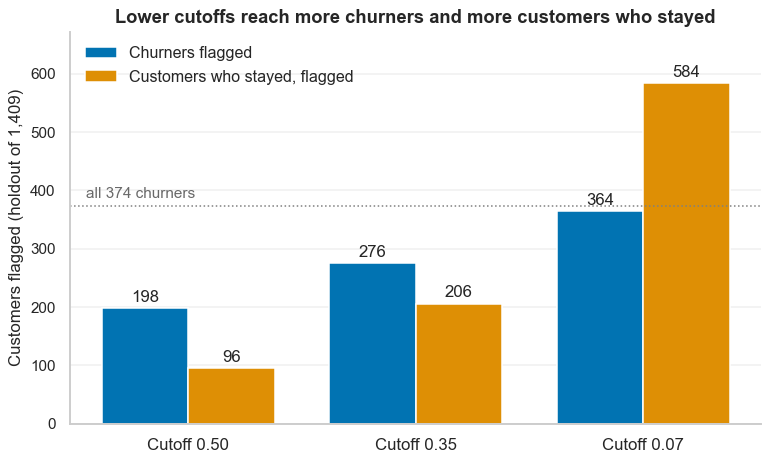

In [26]:
# Who is flagged at three XGBoost cutoffs (the figure used in the report's results).
# The three cutoffs are XGBoost's lowest-cost cutoffs at the assumed 1:1, 3:1 and 10:1 penalties.
_xgb_optima = threshold_optima_df[threshold_optima_df["model"] == "XGBoost"].sort_values("c_fn")
FLAG_CUTOFFS = tuple(round(float(t), 2) for t in _xgb_optima["best_threshold"])
xgb_sweep = threshold_records["XGBoost"]
flag_rows = []
for cutoff in FLAG_CUTOFFS:
    row = xgb_sweep.loc[np.isclose(xgb_sweep["threshold"], cutoff)].iloc[0]
    flag_rows.append({"cutoff": cutoff, "churners_flagged": int(row["tp"]),
                      "stayers_flagged": int(row["fp"]), "churners_missed": int(row["fn"])})
flag_counts_df = pd.DataFrame(flag_rows)
display(flag_counts_df)

fig_flag, ax_flag = plt.subplots(figsize=(7.2, 4.4))
x_pos = np.arange(len(FLAG_CUTOFFS))
bar_width = 0.38
bars_churn = ax_flag.bar(x_pos - bar_width / 2, flag_counts_df["churners_flagged"], bar_width,
                         label="Churners flagged", color=PLOT_PALETTE[0])
bars_stay = ax_flag.bar(x_pos + bar_width / 2, flag_counts_df["stayers_flagged"], bar_width,
                        label="Customers who stayed, flagged", color=PLOT_PALETTE[1])
for bars in (bars_churn, bars_stay):
    ax_flag.bar_label(bars, fontsize=11, padding=2)
ax_flag.axhline(int(pos_mask.sum()), color="gray", linestyle=":", linewidth=1)
ax_flag.text(-0.45, int(pos_mask.sum()) + 8, f"all {int(pos_mask.sum())} churners",
             ha="left", va="bottom", fontsize=10, color="dimgray")
ax_flag.set_xticks(x_pos, [f"Cutoff {c:.2f}" for c in FLAG_CUTOFFS], fontsize=11)
ax_flag.set_ylabel(f"Customers flagged (holdout of {len(y_test_enc):,})", fontsize=11)
ax_flag.set_title("Lower cutoffs reach more churners and more customers who stayed")
ax_flag.legend(loc="upper left", fontsize=10.5)
# Leave room for the tallest bar and for the "all churners" line above the churner bars.
ax_flag.set_ylim(0, max(flag_counts_df[["churners_flagged", "stayers_flagged"]].to_numpy().max(),
                        int(pos_mask.sum())) * 1.15)
ax_flag.grid(axis="x", visible=False)
fig_flag.tight_layout()
save_figure(fig_flag, "threshold_flag_counts")
plt.show()


**Figure 6. Threshold sensitivity on the holdout.** The 2×2 figure contains one F1 panel and three illustrative error-cost panels. Each marker is the minimum observed for that model on the displayed threshold grid, and the dotted line marks 0.50. Cost axes are zoomed and state where curves are clipped. The XGBoost minima are 0.50, 0.35 and 0.07 under the respective 1:1, 3:1 and 10:1 penalties. These reuse the evaluation sample and do not specify a deployment policy.

### Internal sensitivity and reuse of data

The training pipeline is refitted within each fold, preventing preprocessing from being fitted on the corresponding validation fold. Hyperparameter selection still used these training records. Repeated CV and the learning curve therefore describe the selected configurations on reused data rather than provide nested estimates of the full selection procedure.

Alternate train/test fractions also overlap the original tuning data. They are split-sensitivity checks, not new untouched tests. Tenure cohorts describe groups in the same snapshot, not chronological validation. Prospective validation and another dataset remain outstanding.

### Training versus holdout scores

XGBoost's original train-minus-holdout AUC gap is about 0.013, compared with about 0.044 for Random Forest. A larger gap can indicate more optimism in training performance. These values do not prove that either model is free of overfitting, and overlapping model intervals do not answer that question. The holdout has also been repeatedly inspected while developing this project.

In [27]:
# Validation robustness 1/5 -- train vs. test gap (overfitting diagnostic).
# A large positive train-minus-test
# AUC gap can indicate overfitting; neither a small gap nor a large one settles it.
overfit_rows = []
for model_name, estimator in best_estimators.items():
    proba_tr = estimator.predict_proba(X_train)[:, 1]
    proba_te = estimator.predict_proba(X_test)[:, 1]
    train_auc = roc_auc_score(y_train_enc, proba_tr)
    test_auc = roc_auc_score(y_test_enc, proba_te)
    overfit_rows.append({
        "model": model_name,
        "train_auc": train_auc,
        "test_auc": test_auc,
        "auc_gap": train_auc - test_auc,
        "train_f1": f1_score(y_train_enc, (proba_tr >= 0.5).astype(int)),
        "test_f1": f1_score(y_test_enc, (proba_te >= 0.5).astype(int)),
    })
overfitting_gap_df = (
    pd.DataFrame(overfit_rows).sort_values("auc_gap", ascending=False).reset_index(drop=True)
)
display(overfitting_gap_df.round(4))
overfitting_gap_df.round(6).to_csv(TABLES_DIR / "model_overfitting_gap.csv", index=False)
print(f"Saved {TABLES_DIR / 'model_overfitting_gap.csv'}")

,model,train_auc,test_auc,auc_gap,train_f1,test_f1
0,Random Forest,0.8876,0.8434,0.0442,0.6227,0.5745
1,XGBoost,0.8613,0.8480,0.0133,0.6121,0.5928
2,SVM,0.8461,0.8356,0.0104,0.0000,0.0000
3,Logistic Regression,0.8495,0.8416,0.0080,0.6015,0.6040
4,MLP,0.8470,0.8391,0.0079,0.5988,0.5920


Saved thesis_exports/tables/model_overfitting_gap.csv


### Learning curve

XGBoost is refitted at six training sizes with the selected hyperparameters. The original final train-minus-CV gap is about 0.0116 AUC. The curve describes this range of sample sizes under reused CV data. It cannot show that additional data or features would have no value, or identify an information-theoretic ceiling.

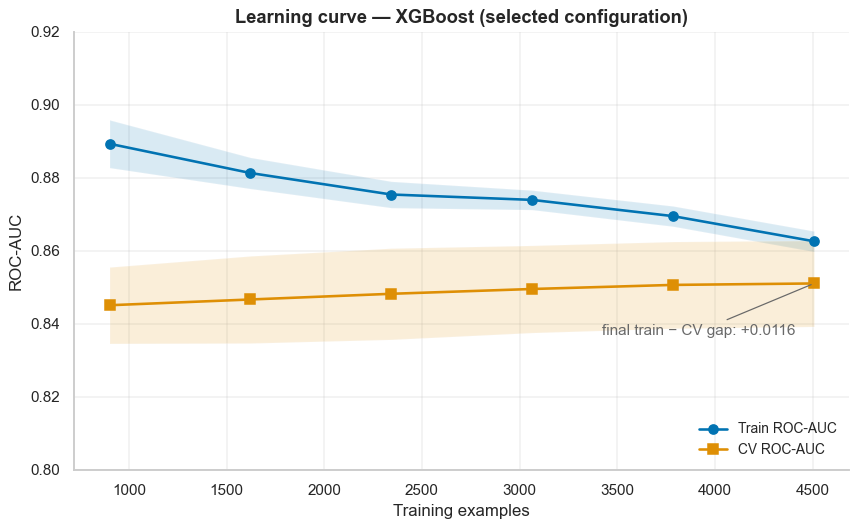

,train_size,train_mean,train_std,cv_mean,cv_std,train_minus_cv
0,901,0.8893,0.0066,0.8451,0.0105,0.0443
1,1622,0.8813,0.0043,0.8466,0.0119,0.0347
2,2343,0.8754,0.0036,0.8482,0.0125,0.0272
3,3064,0.8740,0.0027,0.8495,0.0120,0.0244
4,3785,0.8695,0.0028,0.8506,0.0119,0.0189
5,4507,0.8626,0.0028,0.8510,0.0118,0.0116


Saved thesis_exports/tables/model_learning_curve.csv
Learning-curve final train-CV gap for XGBoost: +0.0116


In [28]:
# Validation robustness 2/5 -- learning curve for the headline tree model.
# Train vs. cross-validated ROC-AUC as training data grows; converging curves with a small
# final gap are descriptive diagnostics, not proof of a performance ceiling.
from sklearn.model_selection import learning_curve

lc_model_name = "XGBoost" if "XGBoost" in best_estimators else next(iter(best_estimators))
lc_sizes, lc_train, lc_val = learning_curve(
    clone(best_estimators[lc_model_name]),
    X_train, y_train_enc,
    cv=cv_strategy, scoring=ranking_auc,
    train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1,
)
lc_train_mean, lc_train_std = lc_train.mean(axis=1), lc_train.std(axis=1)
lc_val_mean, lc_val_std = lc_val.mean(axis=1), lc_val.std(axis=1)
lc_final_gap = float(lc_train_mean[-1] - lc_val_mean[-1])

fig_lc, ax_lc = plt.subplots(figsize=(8, 5))
ax_lc.plot(lc_sizes, lc_train_mean, marker="o", label="Train ROC-AUC")
ax_lc.fill_between(lc_sizes, lc_train_mean - lc_train_std, lc_train_mean + lc_train_std, alpha=0.15)
ax_lc.plot(lc_sizes, lc_val_mean, marker="s", label="CV ROC-AUC")
ax_lc.fill_between(lc_sizes, lc_val_mean - lc_val_std, lc_val_mean + lc_val_std, alpha=0.15)
ax_lc.set_xlabel("Training examples")
ax_lc.set_ylabel("ROC-AUC")

# Fix the y-window so the train-CV gap is read at its true size. Left to
# autoscale, a ~1 point gap filled the panel and read as a large one. The
# window is widened, never narrowed, if a re-run lands outside it.
_lc_lo = float(min((lc_train_mean - lc_train_std).min(), (lc_val_mean - lc_val_std).min()))
_lc_hi = float(max((lc_train_mean + lc_train_std).max(), (lc_val_mean + lc_val_std).max()))
ax_lc.set_ylim(min(0.80, _lc_lo - 0.01), max(0.92, _lc_hi + 0.01))

ax_lc.annotate(
    f"final train − CV gap: {lc_final_gap:+.4f}",
    xy=(lc_sizes[-1], lc_val_mean[-1]),
    xytext=(-12, -34), textcoords="offset points",
    ha="right", fontsize=10, color="dimgray",
    arrowprops=dict(arrowstyle="-", color="dimgray", linewidth=0.8),
)
ax_lc.set_title(f"Learning curve — {lc_model_name} (selected configuration)")
ax_lc.legend(loc="lower right")
fig_lc.tight_layout()
save_figure(fig_lc, "model_learning_curve")
plt.show()

# Export the curve so the thesis can cite the numbers instead of a picture.
learning_curve_df = pd.DataFrame({
    "train_size": lc_sizes.astype(int),
    "train_mean": lc_train_mean,
    "train_std": lc_train_std,
    "cv_mean": lc_val_mean,
    "cv_std": lc_val_std,
})
learning_curve_df["train_minus_cv"] = learning_curve_df["train_mean"] - learning_curve_df["cv_mean"]
display(learning_curve_df.round(4))
learning_curve_df.round(6).to_csv(TABLES_DIR / "model_learning_curve.csv", index=False)
print(f"Saved {TABLES_DIR / 'model_learning_curve.csv'}")
print(f"Learning-curve final train-CV gap for {lc_model_name}: {lc_final_gap:+.4f}")

**Figure 7. XGBoost learning curve.** Training and CV AUC are shown with one-standard-deviation bands across folds. Read the axes and the gap together. The bands describe fold variation rather than confidence intervals for a future population; the hyperparameters were selected on the training data used here.

### Repeated cross-validation

Five-fold CV is repeated three times, giving 15 scores per tuned model. These scores are correlated because their training and validation samples overlap. Mean and standard deviation summarize internal variation, not 15 independent replications. Reported AUC uses probabilities consistently with the holdout table.

,model,roc_auc_mean,roc_auc_std,roc_auc_min,roc_auc_max,n_folds
0,XGBoost,0.8507,0.0125,0.8327,0.8698,15
1,Random Forest,0.8488,0.0117,0.8336,0.8668,15
2,Logistic Regression,0.8464,0.0120,0.8253,0.8633,15
3,MLP,0.8438,0.0123,0.8254,0.8633,15
4,SVM,0.8424,0.0104,0.8277,0.8575,15


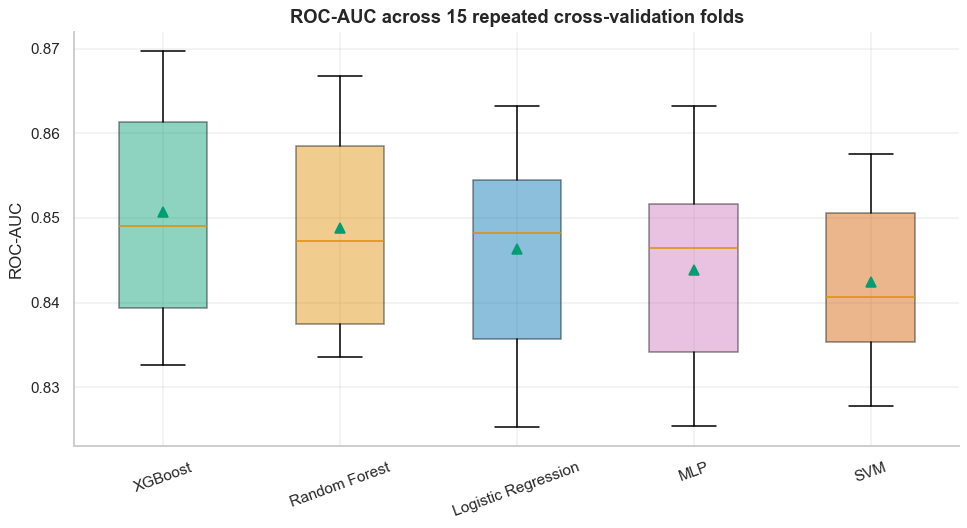

Saved repeated-CV summary + per-fold scores and boxplot.


In [29]:
# Validation robustness 3/5 -- RepeatedStratifiedKFold stability.
# Reuses tuning data with fixed selected configurations; folds overlap.
# Reports descriptive mean +/- std ROC-AUC per model (ranking score, as in the CV cell).
from sklearn.model_selection import RepeatedStratifiedKFold

REPEATED_CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rep_summary_rows = []
rep_fold_rows = []
for model_name, estimator in best_estimators.items():
    scores = cross_validate(
        clone(estimator), X_train, y_train_enc,
        cv=REPEATED_CV, scoring=ranking_auc, n_jobs=-1,
    )["test_score"]
    for k, s in enumerate(scores):
        rep_fold_rows.append({"model": model_name, "fold": int(k), "roc_auc": float(s)})
    rep_summary_rows.append({
        "model": model_name,
        "roc_auc_mean": float(np.mean(scores)),
        "roc_auc_std": float(np.std(scores, ddof=1)),
        "roc_auc_min": float(np.min(scores)),
        "roc_auc_max": float(np.max(scores)),
        "n_folds": int(len(scores)),
    })
repeated_cv_summary_df = (
    pd.DataFrame(rep_summary_rows).sort_values("roc_auc_mean", ascending=False).reset_index(drop=True)
)
repeated_cv_scores_df = pd.DataFrame(rep_fold_rows)
display(repeated_cv_summary_df.round(4))
repeated_cv_summary_df.round(6).to_csv(TABLES_DIR / "model_repeated_cv_summary.csv", index=False)
repeated_cv_scores_df.round(6).to_csv(TABLES_DIR / "model_repeated_cv_scores.csv", index=False)

order = repeated_cv_summary_df["model"].tolist()
data_by_model = [repeated_cv_scores_df.loc[repeated_cv_scores_df.model == m, "roc_auc"].values for m in order]
fig_rcv, ax_rcv = plt.subplots(figsize=(9, 5))
box_rcv = ax_rcv.boxplot(data_by_model, tick_labels=order, showmeans=True, patch_artist=True)
for _patch, _name in zip(box_rcv["boxes"], order):
    _patch.set_facecolor(model_color(_name))
    _patch.set_alpha(0.45)
    _patch.set_edgecolor("black")
ax_rcv.set_ylabel("ROC-AUC")
ax_rcv.set_title(f"ROC-AUC across {int(repeated_cv_summary_df.n_folds.iloc[0])} repeated cross-validation folds")
ax_rcv.tick_params(axis="x", rotation=20)
fig_rcv.tight_layout()
save_figure(fig_rcv, "model_repeated_cv_auc")
plt.show()
print("Saved repeated-CV summary + per-fold scores and boxplot.")

**Figure 8. AUC across 15 repeated-CV folds.** Each box summarizes a model's scores and the triangle marks the mean. Overlap describes sensitivity to resampling the existing training data. It does not establish model equivalence, and the folds were not used for nested retuning.

### Sensitivity to split size

Each selected configuration is refitted on 80/20, 70/30 and 50/50 stratified splits. This checks how reported scores change under those partitions. The original XGBoost results are about 0.848, 0.847 and 0.844 AUC. Because the alternative partitions overlap records used in original tuning, they are internal sensitivity analyses rather than fresh unbiased evaluations.

test_frac,0.2,0.3,0.5
model,,,
Logistic Regression,0.8416,0.8449,0.8411
MLP,0.8391,0.8358,0.8395
Random Forest,0.8434,0.8432,0.8407
SVM,0.8356,0.8344,0.8355
XGBoost,0.8480,0.8471,0.8437


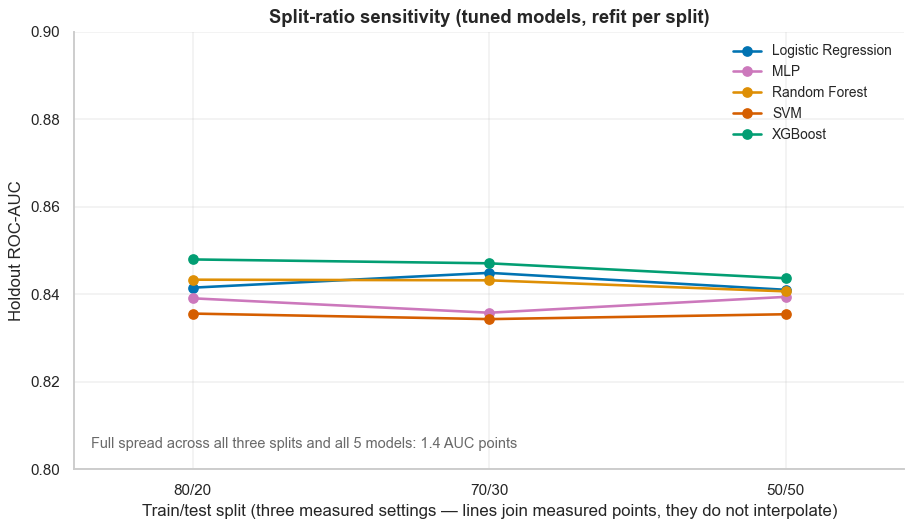

Saved thesis_exports/tables/split_ratio_sensitivity.csv


In [30]:
# Validation robustness 4/5 -- split-ratio sensitivity.
# Re-evaluate the SAME tuned hyperparameters under 80/20, 70/30, 50/50 stratified splits
# (refit, not re-tuned). These partitions overlap original tuning data.
split_rows = []
for ts in (0.20, 0.30, 0.50):
    X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
        X, y, test_size=ts, random_state=RANDOM_STATE, stratify=y
    )
    y_tr_e = target_encoder.transform(y_tr_s)
    y_te_e = target_encoder.transform(y_te_s)
    for model_name, estimator in best_estimators.items():
        est = clone(estimator)
        est.fit(X_tr_s, y_tr_e)
        proba = est.predict_proba(X_te_s)[:, 1]
        split_rows.append({
            "model": model_name,
            "train_frac": round(1 - ts, 2),
            "test_frac": round(ts, 2),
            "roc_auc": roc_auc_score(y_te_e, proba),
        })
split_ratio_df = pd.DataFrame(split_rows)
split_pivot = split_ratio_df.pivot(index="model", columns="test_frac", values="roc_auc")
display(split_pivot.round(4))
split_ratio_df.round(6).to_csv(TABLES_DIR / "split_ratio_sensitivity.csv", index=False)

# Two fixes to what was the notebook's most misleading figure:
#   1. A categorical x-axis with one tick per measured split. Plotted on a
#      continuous axis, the three measured points implied a smooth curve
#      through split ratios that were never evaluated.
#   2. A fixed y-window. Autoscaling stretched a ~1 point AUC band across
#      the whole panel, so a figure whose point is "the split ratio does
#      not matter" read as wild instability. The window is widened, never
#      narrowed, if a re-run lands outside it.
fig_sr, ax_sr = plt.subplots(figsize=(8.5, 5))
sr_xpos = np.arange(len(split_pivot.columns))
sr_labels = [
    f"{int(round((1 - float(tf)) * 100))}/{int(round(float(tf) * 100))}"
    for tf in split_pivot.columns
]

for model_name in split_pivot.index:
    ax_sr.plot(
        sr_xpos, split_pivot.loc[model_name].values, marker="o",
        label=model_name, color=model_color(model_name),
    )

ax_sr.set_xticks(sr_xpos)
ax_sr.set_xticklabels(sr_labels)
ax_sr.set_xlim(-0.4, len(sr_xpos) - 0.6)
ax_sr.set_xlabel("Train/test split (three measured settings — lines join measured points, they do not interpolate)")
ax_sr.set_ylabel("Holdout ROC-AUC")

sr_lo = float(split_ratio_df["roc_auc"].min())
sr_hi = float(split_ratio_df["roc_auc"].max())
ax_sr.set_ylim(min(0.80, sr_lo - 0.01), max(0.90, sr_hi + 0.01))
ax_sr.annotate(
    f"Full spread across all three splits and all {split_pivot.shape[0]} models: "
    f"{(sr_hi - sr_lo) * 100:.1f} AUC points",
    xy=(0.02, 0.05), xycoords="axes fraction", fontsize=9.5, color="dimgray",
)

ax_sr.set_title("Split-ratio sensitivity (tuned models, refit per split)")
ax_sr.legend(loc="best", fontsize=9)
fig_sr.tight_layout()
save_figure(fig_sr, "split_ratio_sensitivity")
plt.show()
print(f"Saved {TABLES_DIR / 'split_ratio_sensitivity.csv'}")

**Figure 9. AUC at three train/test ratios.** Lines join the three measured settings; they do not imply values at intermediate splits. The plotted changes are small for these selected configurations. This does not establish independence from every split or replace an external test.

### Performance across tenure groups

The XGBoost holdout is divided into 0–12, 13–36 and 37+ months of recorded tenure. In the original run, AUC is about 0.769, 0.827 and 0.809, and recall at probability 0.50 is about 0.712, 0.370 and 0.136. These differences warrant attention rather than an automatic claim of stability.

Cohort churn rates also differ, but recall is conditional on actual churners. A change in prevalence alone does not mechanically explain its decline. The distribution of scores among churners, sample sizes and model fit within each group matter. Cohort-specific cutoffs have not been independently evaluated.

,tenure_band,n,churn_rate,roc_auc,recall_at_0_5,precision_at_0_5
0,0-12m (new),449,0.4788,0.7692,0.7116,0.6861
1,13-36m (mid),369,0.2710,0.8273,0.3700,0.6491
2,37+m (tenured),591,0.0998,0.8091,0.1356,0.5714


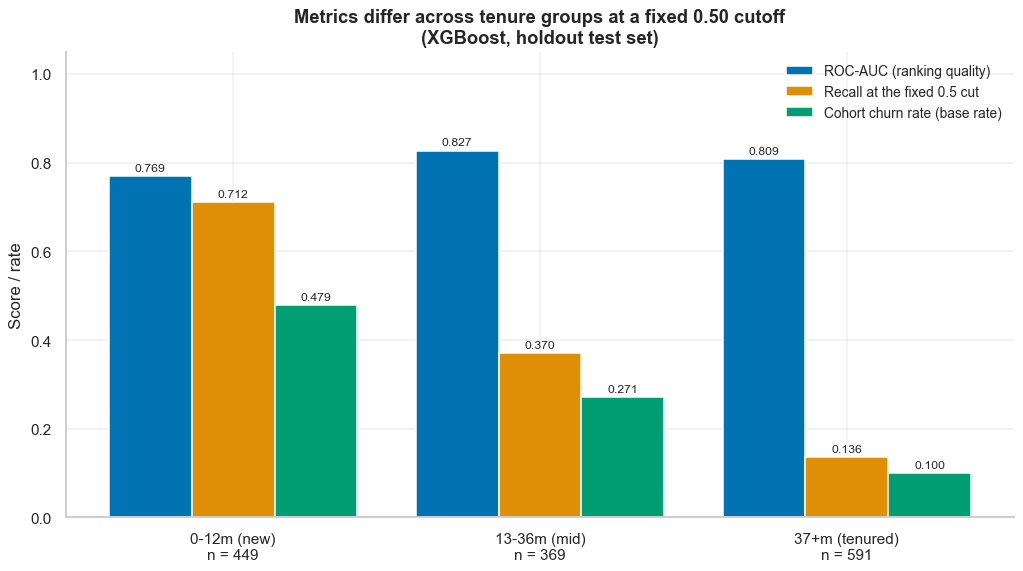

Saved thesis_exports/tables/tenure_cohort_performance.csv


In [31]:
# Descriptive XGBoost performance in tenure groups from the same holdout.
# These groups are not chronological validation or a prospective follow-up.
tenure_col = next((c for c in X_test.columns if c.lower() == "tenure"), None)
if tenure_col is None:
    print("No 'tenure' column found; skipping tenure-cohort analysis.")
else:
    cohort_model_name = "XGBoost" if "XGBoost" in best_estimators else next(iter(best_estimators))
    cohort_proba = best_estimators[cohort_model_name].predict_proba(X_test)[:, 1]
    tvals = X_test[tenure_col].values
    bands = [(0, 12, "0-12m (new)"), (13, 36, "13-36m (mid)"), (37, 200, "37+m (tenured)")]
    cohort_rows = []
    for lo, hi, label in bands:
        mask = (tvals >= lo) & (tvals <= hi)
        if mask.sum() < 20:
            continue
        yb = y_test_enc[mask]
        pb = cohort_proba[mask]
        cohort_rows.append({
            "tenure_band": label,
            "n": int(mask.sum()),
            "churn_rate": float(np.mean(yb)),
            "roc_auc": roc_auc_score(yb, pb) if len(np.unique(yb)) > 1 else float("nan"),
            "recall_at_0_5": recall_score(yb, (pb >= 0.5).astype(int)),
            "precision_at_0_5": precision_score(yb, (pb >= 0.5).astype(int), zero_division=0),
        })
    tenure_cohort_df = pd.DataFrame(cohort_rows)
    display(tenure_cohort_df.round(4))
    tenure_cohort_df.round(6).to_csv(TABLES_DIR / "tenure_cohort_performance.csv", index=False)

    # Churn proportion is context, not a mathematical explanation of recall.
    # Recall conditions on positives; cohort score distributions also matter.
    xpos = np.arange(len(tenure_cohort_df))
    bar_w = 0.27
    fig_tc, ax_tc = plt.subplots(figsize=(9.5, 5.4))
    bars_auc = ax_tc.bar(
        xpos - bar_w, tenure_cohort_df["roc_auc"], width=bar_w,
        label="ROC-AUC (ranking quality)",
    )
    bars_rec = ax_tc.bar(
        xpos, tenure_cohort_df["recall_at_0_5"], width=bar_w,
        label="Recall at the fixed 0.5 cut",
    )
    bars_base = ax_tc.bar(
        xpos + bar_w, tenure_cohort_df["churn_rate"], width=bar_w,
        label="Cohort churn rate (base rate)",
    )
    for bar_group in (bars_auc, bars_rec, bars_base):
        ax_tc.bar_label(bar_group, fmt="%.3f", fontsize=8, padding=2)

    ax_tc.set_xticks(xpos)
    ax_tc.set_xticklabels([
        f"{band}\nn = {int(n):,}"
        for band, n in zip(tenure_cohort_df["tenure_band"], tenure_cohort_df["n"])
    ])
    ax_tc.set_ylim(0, 1.05)
    ax_tc.set_ylabel("Score / rate")
    ax_tc.set_title(
        "Metrics differ across tenure groups at a fixed 0.50 cutoff\n"
        f"({cohort_model_name}, holdout test set)"
    )
    ax_tc.legend(loc="upper right", fontsize=9)
    fig_tc.tight_layout()
    save_figure(fig_tc, "tenure_cohort_performance")
    plt.show()
    print(f"Saved {TABLES_DIR / 'tenure_cohort_performance.csv'}")

**Figure 10. XGBoost metrics by tenure group.** AUC, recall at 0.50 and observed churn proportion describe different quantities. The longest-tenure group has few churners and low recall at this cutoff. Grouped performance is a diagnostic of the present snapshot, not evidence about future months or a measured habit-formation process.

### What the time fields support

IBM's last-month label is retrospective. Recorded tenure is elapsed time with the service, but the file does not document entry cohorts, inclusion of earlier departures, censoring rules or covariate timing. Those omissions prevent a defensible population survival or lifetime-hazard analysis from these fields alone.

The October revision withdraws the earlier Kaplan–Meier and Cox block and its exports. Its history remains in version control. Neither tenure comparisons nor the removed survival calculations establish a prospective 30-day forecast or a time at which habit forms. That would require appropriately dated observations and a documented sampling/follow-up design.

### Evidence summary

| Artifact | What it supports | Main limit |
|---|---|---|
| `model_cv_scores.csv` | Probability-based CV metrics for selected configurations | Same folds/data used in tuning |
| `model_comparison_metrics.csv` | Holdout classification metrics, bootstrap intervals and Brier loss | One benchmark; intervals condition on fitted models |
| `model_auc_pairwise_tests.csv` | Exploratory differences in AUC on paired predictions | Ten unadjusted comparisons; no equivalence test |
| `model_calibration.*` | Binned probability reliability and score distributions | Sparse bins; Brier is not calibration-only |
| `threshold_sweep_*.csv`, `threshold_cost_optima.csv` | Observed error counts and grid minima under assumed penalties | Selected and evaluated on the same sample; no treatment effect |
| `model_repeated_cv_*.csv`, `split_ratio_sensitivity.csv` | Internal resampling sensitivity | Overlapping data; no external validation |
| `tenure_cohort_performance.csv` | Grouped diagnostic at a fixed cutoff | Cross-sectional groups, not follow-up |
| `permutation_importance_xgboost.csv` | Which inputs this fitted model relies on for ranking | Correlated features can share information; no causal interpretation |

The substantive contribution is the transparent sequence from data audit to model comparison, error trade-offs and communication hypotheses. Operational effectiveness remains to be evaluated.

### Comparative interpretation

Observed holdout AUC differences are small: approximately 0.012 across all five models and 0.0065 among the three primary models. The searches use different candidate budgets. The evidence describes these fitted configurations on this benchmark, without proving that algorithm choice is irrelevant.

Different models can rank customers similarly while assigning different individual scores or producing different error counts at a given cutoff. Practical equivalence would require a defined operating policy, an equivalence margin and relevant outcome data. None is supplied by the current AUC comparison.

In [32]:
# Fixed model for illustrative explanation; not selected from holdout metrics.
EXPLANATION_MODEL = "XGBoost"
if EXPLANATION_MODEL not in best_estimators:
    raise RuntimeError("Run XGBoost tuning before the explanation phase.")

# These legacy variable names are consumed by SHAP and the demo export.
best_model_name = EXPLANATION_MODEL
best_model_for_shap = best_estimators[EXPLANATION_MODEL]

# A descriptive ranking is exported, but it does not choose the model above.
model_ranking = metrics_df.sort_values("roc_auc", ascending=False).reset_index(drop=True)
display(model_ranking)
model_ranking.round(6).to_csv(TABLES_DIR / "model_ranking.csv", index=False)
print(f"Saved {TABLES_DIR / 'model_ranking.csv'} ({len(model_ranking)} models)")
print(f"Fixed illustrative explanation model: {EXPLANATION_MODEL}")
print("Retrospective October revision; not a preregistered or holdout-selected deployment winner.")

,model,precision,precision_ci_low,precision_ci_high,precision_boot_mean,recall,recall_ci_low,recall_ci_high,recall_boot_mean,f1_score,f1_ci_low,f1_ci_high,f1_boot_mean,roc_auc,roc_auc_ci_low,roc_auc_ci_high,roc_auc_boot_mean,brier_score,brier_score_isotonic
0,XGBoost,0.673469,0.623094,0.721617,0.673291,0.529412,0.481217,0.585561,0.529324,0.592814,0.548654,0.635699,0.592370,0.848010,0.824946,0.870489,0.848021,0.134774,0.134475
1,Random Forest,0.675090,0.630816,0.722232,0.674464,0.500000,0.449198,0.550802,0.498845,0.574501,0.530908,0.616089,0.573200,0.843383,0.822005,0.863651,0.842853,0.136347,0.136622
2,Logistic Regression,0.657233,0.612701,0.702536,0.658046,0.558824,0.505348,0.606952,0.558262,0.604046,0.561349,0.645714,0.603773,0.841559,0.820293,0.861854,0.841543,0.138345,0.138782
3,MLP,0.639752,0.598043,0.685433,0.640478,0.550802,0.497326,0.601604,0.549647,0.591954,0.546262,0.632517,0.591321,0.839125,0.817106,0.860978,0.839394,0.139019,0.137951
4,SVM,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.835635,0.813586,0.858481,0.836287,0.160282,0.140368


Saved thesis_exports/tables/model_ranking.csv (5 models)
Fixed illustrative explanation model: XGBoost
Retrospective October revision; not a preregistered or holdout-selected deployment winner.


### Measured scoring time

Each fitted pipeline scores the full holdout 20 times after warm-up. The table reports median batch time and that time divided by the number of records. Batch time per record is not a measurement of single-request latency, and excludes network, application, monitoring and human-review costs.

Timings and even their ordering can change with hardware, batch size and implementation. They are excluded from numerical drift checks. The current output, rather than a fixed prose value, is the source for this machine-specific result.

In [33]:
# Inference cost per tuned model -- measured, not asserted.
# Median of 20 timed predict_proba() calls on the full holdout (preprocessing
# included, since a deployed pipeline pays for it too). Excluded from the
# byte-level reproducibility check: it measures the machine, not the model.
LATENCY_REPEATS = 20
latency_rows = []
for model_name, estimator in best_estimators.items():
    estimator.predict_proba(X_test)                       # warm-up (JIT, caches)
    timings = []
    for _ in range(LATENCY_REPEATS):
        t0 = time.perf_counter()
        estimator.predict_proba(X_test)
        timings.append(time.perf_counter() - t0)
    med = float(np.median(timings))
    latency_rows.append({
        "model": model_name,
        "n_rows": int(len(X_test)),
        "median_batch_ms": med * 1000.0,
        "microseconds_per_row": med / len(X_test) * 1e6,
        "p90_batch_ms": float(np.percentile(timings, 90)) * 1000.0,
    })
inference_latency_df = pd.DataFrame(latency_rows).set_index("model")
_lr_us = inference_latency_df.loc["Logistic Regression", "microseconds_per_row"]
inference_latency_df["ratio_to_logistic"] = inference_latency_df["microseconds_per_row"] / _lr_us
inference_latency_df = inference_latency_df.sort_values("microseconds_per_row")
display(inference_latency_df.round(3))
inference_latency_df.round(6).to_csv(TABLES_DIR / "inference_latency.csv")
print(f"Saved {TABLES_DIR / 'inference_latency.csv'} (machine-dependent; excluded from drift check)")


,n_rows,median_batch_ms,microseconds_per_row,p90_batch_ms,ratio_to_logistic
model,,,,,
Logistic Regression,1409,2.577,1.829,2.999,1.000
XGBoost,1409,3.111,2.208,3.282,1.207
MLP,1409,3.308,2.348,3.407,1.284
Random Forest,1409,28.187,20.005,29.386,10.937
SVM,1409,34.444,24.446,34.869,13.365


Saved thesis_exports/tables/inference_latency.csv (machine-dependent; excluded from drift check)


### A complementary importance measure

Permutation importance shuffles one input at a time and measures the change in holdout AUC over 20 repeats. Contract and tenure have the largest observed decreases for this XGBoost model. Near-zero or slightly negative values can reflect sampling variability or information shared with other inputs; they do not prove that a feature is universally useless.

Permutation importance and SHAP answer different questions using the same model and data. Agreement strengthens a description of model reliance, not an independently validated causal story.

In [34]:
# Permutation importance for the fixed illustrative XGBoost model.
#
# Permutation importance is the drop in a held-out score when one feature
# is randomly permuted (k repeats, score recorded each time). It is
# model-agnostic and operates on raw input features, complementing SHAP
# (which decomposes a single prediction into per-feature contributions
# in transformed feature space). High concordance with the SHAP top-K
# describes model reliance; correlated inputs and sampling variation can
# also explain differences between these two measures.

from sklearn.inspection import permutation_importance

PERM_N_REPEATS = 20

perm_result = permutation_importance(
    best_model_for_shap,
    X_test,
    y_test_enc,
    n_repeats=PERM_N_REPEATS,
    random_state=RANDOM_STATE,
    scoring="roc_auc",
    n_jobs=-1,
)

perm_importance_df = (
    pd.DataFrame(
        {
            "feature": X_test.columns,
            "importance_mean": perm_result.importances_mean,
            "importance_std": perm_result.importances_std,
        }
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

display(perm_importance_df.head(15).round(5))

safe_best = best_model_name.lower().replace(" ", "_")
perm_csv = TABLES_DIR / f"permutation_importance_{safe_best}.csv"
perm_importance_df.round(6).to_csv(perm_csv, index=False)
print(f"Saved {perm_csv}")
print(f"(scoring = ROC-AUC, n_repeats = {PERM_N_REPEATS}, model = {best_model_name})")

,feature,importance_mean,importance_std
0,Contract,0.05929,0.00587
1,tenure,0.05451,0.00410
2,InternetService,0.01283,0.00406
3,TotalCharges,0.00618,0.00133
4,MonthlyCharges,0.00548,0.00254
5,OnlineSecurity,0.00528,0.00159
6,PaymentMethod,0.00274,0.00125
7,TechSupport,0.00268,0.00150
8,PaperlessBilling,0.00254,0.00105
9,MultipleLines,0.00218,0.00092


Saved thesis_exports/tables/permutation_importance_xgboost.csv
(scoring = ROC-AUC, n_repeats = 20, model = XGBoost)


### Explanation-model handoff

XGBoost is the fixed illustration for TreeSHAP and the offline tree-scoring demo. The implementation now uses the explicit name `EXPLANATION_MODEL = "XGBoost"`; no holdout sorting or Brier tie-break chooses it.

This choice was clarified retrospectively in October after the benchmark results were examined. It is not a preregistered rule and does not certify XGBoost as the deployment choice. Logistic Regression remains an informative simpler baseline, with higher observed recall and F1 at 0.50 in the original holdout run.

<a id="explainability"></a>
## CRISP-DM: SHAP Explainability

SHAP describes how the fitted XGBoost model assigns scores globally and to selected holdout records. The explanation does not retrain the model, measure a communication construct or estimate the effect of changing a feature. The later translation tables turn these observations into hypotheses for separate evaluation.

### Interpretability and explainability

Terminology varies across the literature (Lipton, 2018; Doshi-Velez and Kim, 2017; Rudin, 2019; Molnar, 2022). This study adopts a working distinction:

- **Interpretability:** inspecting how the model itself maps inputs to outputs. Logistic Regression offers coefficients whose meaning still depends on encoding, scale and correlated inputs.
- **Explainability:** using an additional method to describe an already-fitted model. SHAP supplies post-hoc attributions for XGBoost.

An explanation can help inspect a score without making the score correct or its associations causal. The simpler baseline stays in the comparison so that explanatory complexity can be considered alongside predictive performance.

In [35]:
import shap

np.random.seed(RANDOM_STATE)

print(f"SHAP version: {shap.__version__}")

SHAP version: 0.51.0


### SHAP usage

`TreeExplainer` computes TreeSHAP attributions under its feature-dependence assumptions (Lundberg et al., 2020). Global mean absolute values summarize contribution magnitudes across the holdout. Local values add to an individual prediction on the log-odds scale.

Correlated inputs can share attribution, and the reference distribution matters. A useful explanation can suggest questions for a communication team, but selecting an effective message requires additional evidence.

In [36]:
# Guard: the SHAP phase runs on the model chosen by the fixed explanation-model cell.
#
# Earlier revisions carried a recovery branch here that rebuilt the pipeline
# from a hard-coded copy of the XGBoost best-parameter dict. That branch was
# never taken on a top-to-bottom run, and its ten literals had to be kept in
# sync with the RandomizedSearchCV result by hand -- silent drift the moment
# the seed or the search space changed. It has been removed in favour of an
# explicit failure.
if "best_model_for_shap" not in globals():
    raise RuntimeError(
        "best_model_for_shap is not in the kernel. Run the fixed explanation-model cell "
        "in the Modeling phase before the SHAP phase."
    )

print("best_model_for_shap already available in kernel.")

# Validate required artifacts for SHAP phase
required_shap_objects = [
    "best_model_for_shap",
    "X_train",
    "X_test",
    "y_test",
    "y_test_enc",
    "RANDOM_STATE",
]

missing_shap_objects = [name for name in required_shap_objects if name not in globals()]
if missing_shap_objects:
    raise ValueError(f"Missing required SHAP artifacts: {missing_shap_objects}")

print(f"Fixed illustration model for SHAP: {best_model_name}")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test length: {len(y_test)}")
print(f"y_test_enc length: {len(y_test_enc)}")

# Extract fitted components from best_model_for_shap
shap_preprocessor = best_model_for_shap.named_steps["preprocessor"]
shap_model = best_model_for_shap.named_steps["model"]

print("Extracted model class:", type(shap_model).__name__)
print("Extracted preprocessor class:", type(shap_preprocessor).__name__)

# Transform features and recover transformed feature names
X_train_shap_arr = shap_preprocessor.transform(X_train)
X_test_shap_arr = shap_preprocessor.transform(X_test)

# Recover transformed feature names in fitted order
cat_cols = shap_preprocessor.transformers_[0][2]
num_cols = shap_preprocessor.transformers_[1][2]
cat_feature_names = shap_preprocessor.named_transformers_["categorical"].get_feature_names_out(cat_cols)
transformed_feature_names = cat_feature_names.tolist() + list(num_cols)

X_train_shap = pd.DataFrame(X_train_shap_arr, columns=transformed_feature_names, index=X_train.index)
X_test_shap = pd.DataFrame(X_test_shap_arr, columns=transformed_feature_names, index=X_test.index)

print(f"X_train_shap shape: {X_train_shap.shape}")
print(f"X_test_shap shape: {X_test_shap.shape}")
print("Sample transformed features:")
print(transformed_feature_names[:12])

# SHAP input integrity checks
if X_train_shap.shape[1] != len(transformed_feature_names):
    raise ValueError("Mismatch between transformed matrix columns and feature-name list.")

if not X_train_shap.columns.equals(X_test_shap.columns):
    raise ValueError("Train and test transformed feature columns are not aligned.")

print("Feature alignment checks passed.")
print(f"Total transformed features: {X_train_shap.shape[1]}")

best_model_for_shap already available in kernel.
Fixed illustration model for SHAP: XGBoost
X_train shape: (5634, 19)
X_test shape: (1409, 19)
y_test length: 1409
y_test_enc length: 1409
Extracted model class: XGBClassifier
Extracted preprocessor class: ColumnTransformer
X_train_shap shape: (5634, 46)
X_test_shap shape: (1409, 46)
Sample transformed features:
['gender_Female', 'gender_Male', 'SeniorCitizen_No', 'SeniorCitizen_Yes', 'Partner_No', 'Partner_Yes', 'Dependents_No', 'Dependents_Yes', 'PhoneService_No', 'PhoneService_Yes', 'MultipleLines_No', 'MultipleLines_No phone service']
Feature alignment checks passed.
Total transformed features: 46


### One-hot features

There are 46 transformed columns from 19 original features. All transformed-column SHAP contributions add to the local prediction, including dummies with value zero. For the global summary, the notebook sums the mean absolute contributions of the dummies belonging to each original feature. This is an attribution-magnitude summary; it is not the mean absolute value of the signed local sum.

In [37]:
# Build SHAP explainer and compute SHAP values
shap_explainer = shap.TreeExplainer(shap_model)

# Use full train/test transformed sets so global and local explanations
# cover every customer, not a sample
shap_values_train = shap_explainer.shap_values(X_train_shap)
shap_values_test = shap_explainer.shap_values(X_test_shap)

print("SHAP values computed successfully.")

# SHAP diagnostics and consistency checks
expected_value = shap_explainer.expected_value

print("Expected value:", expected_value)
print("SHAP train shape:", np.array(shap_values_train).shape)
print("SHAP test shape:", np.array(shap_values_test).shape)
print("X_train_shap shape:", X_train_shap.shape)
print("X_test_shap shape:", X_test_shap.shape)

if np.array(shap_values_test).shape[1] != X_test_shap.shape[1]:
    raise ValueError("SHAP feature dimension mismatch on test set.")

if np.array(shap_values_train).shape[1] != X_train_shap.shape[1]:
    raise ValueError("SHAP feature dimension mismatch on train set.")

print("SHAP dimensional checks passed.")

SHAP values computed successfully.
Expected value: -1.023957
SHAP train shape: (5634, 46)
SHAP test shape: (1409, 46)
X_train_shap shape: (5634, 46)
X_test_shap shape: (1409, 46)
SHAP dimensional checks passed.


### SHAP reference value

The original explainer reference value is about −1.024 log-odds. Applying the logistic function gives approximately 0.264, but this need not equal the empirical churn proportion or the mean predicted probability: the logistic transform is nonlinear and the reference depends on the explainer.

For each record, the reference plus all 46 signed feature contributions reconstructs the model's log-odds. The demo-export cell checks that equality numerically.

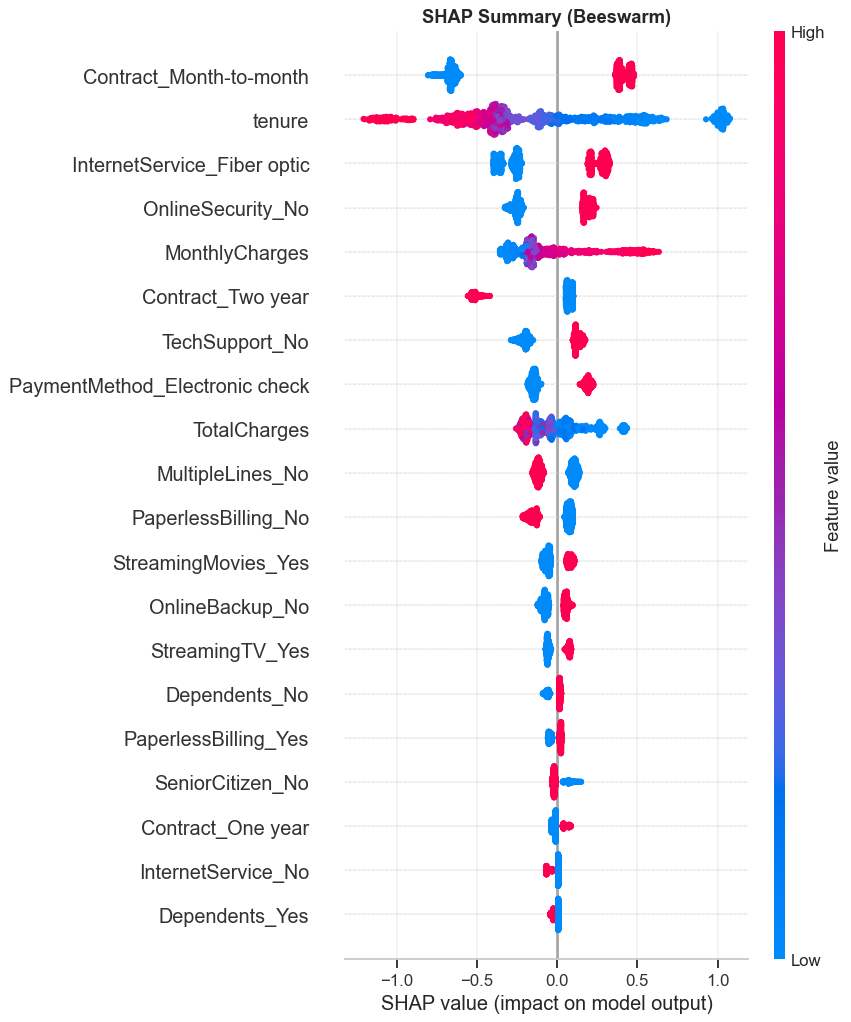

Note: features above are one-hot encoded where applicable; grouped base-feature importance is shown below.
Units: SHAP values are in log-odds, not probability — a value of +0.5 shifts the log-odds of churn by 0.5.


In [38]:
# SHAP summary plot (beeswarm).
# shap.summary_plot() creates and sizes its own figure from the number of
# displayed features, so a preceding plt.figure(figsize=...) is discarded.
# The pre-created figure has been removed rather than left as a misleading
# no-op; save_figure() picks up SHAP's canvas via plt.gcf().
shap.summary_plot(
    shap_values_test,
    X_test_shap,
    max_display=20,
    show=False,
)
plt.title("SHAP Summary (Beeswarm)")
plt.tight_layout()
save_figure(plt.gcf(), "shap_summary_beeswarm")
plt.show()

print("Note: features above are one-hot encoded where applicable; grouped base-feature importance is shown below.")
print("Units: SHAP values are in log-odds, not probability — a value of +0.5 shifts the log-odds of churn by 0.5.")

**Figure 11. SHAP beeswarm on the holdout.** Each dot is a record; horizontal position is that input's contribution to the model score. Red denotes higher feature values and blue lower values. For tenure, shorter durations tend to raise the score and longer durations lower it. These are model associations on this dataset, not effects of an intervention that changes tenure.

### Global SHAP finding

The largest transformed-feature contributions are month-to-month contract, tenure, fiber-optic service, absence of online security and monthly charges. The grouped table combines encoded categories for an original-feature summary.

This pattern motivates questions about subscription terms, early service experiences, service bundles and price. Habit, trust, satisfaction and perceived value require their own measurements. Low demographic attribution also does not establish that the model is fair.

In [39]:
# Feature-level SHAP importance ranking table
mean_abs_shap = np.abs(shap_values_test).mean(axis=0)
shap_importance_table = pd.DataFrame(
    {
        "feature": X_test_shap.columns,
        "mean_abs_shap": mean_abs_shap,
    }
).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

display(shap_importance_table.head(25))

# Export every transformed feature, not the top 25 the stale hand-made copy
# on disk carried. The display above stays at 25 rows for readability.
shap_importance_table.round(6).to_csv(
    TABLES_DIR / "shap_feature_importance_transformed.csv", index=False
)
print(
    f"Saved {TABLES_DIR / 'shap_feature_importance_transformed.csv'} "
    f"({len(shap_importance_table)} transformed features)"
)

,feature,mean_abs_shap
0,Contract_Month-to-month,0.527570
1,tenure,0.480508
2,InternetService_Fiber optic,0.288607
3,OnlineSecurity_No,0.222731
4,MonthlyCharges,0.217774
5,Contract_Two year,0.178673
6,TechSupport_No,0.165522
7,PaymentMethod_Electronic check,0.161479
8,TotalCharges,0.128984
9,MultipleLines_No,0.112225


Saved thesis_exports/tables/shap_feature_importance_transformed.csv (46 transformed features)


In [40]:
# Aggregate one-hot SHAP importance into base feature families
categorical_base_features = list(cat_cols)
numerical_base_features = list(num_cols)


def map_to_base_feature(feature_name):
    for base in categorical_base_features:
        prefix = f"{base}_"
        if feature_name.startswith(prefix):
            return base
    if feature_name in numerical_base_features:
        return feature_name
    return feature_name


shap_importance_table["base_feature"] = shap_importance_table["feature"].apply(map_to_base_feature)
shap_grouped_importance = (
    shap_importance_table.groupby("base_feature", as_index=False)["mean_abs_shap"]
    .sum()
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_grouped_importance.head(20))

# Cited by name in the Deployment playbook, so the notebook must write it.
shap_grouped_importance.round(6).to_csv(
    TABLES_DIR / "shap_feature_importance_grouped.csv", index=False
)
print(
    f"Saved {TABLES_DIR / 'shap_feature_importance_grouped.csv'} "
    f"({len(shap_grouped_importance)} base features)"
)

,base_feature,mean_abs_shap
0,Contract,0.731544
1,tenure,0.480508
2,InternetService,0.309314
3,OnlineSecurity,0.231306
4,MonthlyCharges,0.217774
5,TechSupport,0.168271
6,PaymentMethod,0.166636
7,PaperlessBilling,0.139657
8,TotalCharges,0.128984
9,MultipleLines,0.117347


Saved thesis_exports/tables/shap_feature_importance_grouped.csv (19 base features)


### Grouped importance

For each original categorical feature, this table sums the mean absolute SHAP values of its one-hot columns. For example, the original `Contract` total of about 0.732 is 0.528 + 0.179 + 0.025. It is not the mean absolute value obtained after summing signed local contributions, because absolute values remove cancellation.

The legacy column name `mean_abs_shap` is retained. Read it as a grouped attribution-magnitude summary. Contract and tenure together account for about 40% of the total 3.013 across all 19 original features. This proportion is specific to the fitted model, encoding, explainer and evaluation records; it is not a share of the causes of churn.

### From explanations to questions

The encoded-feature table supports model inspection; the grouped table supports a shorter account of which original inputs matter to the fitted model. Both retain their identifiers for traceability. The later signal-to-test tables add plain display labels and keep observed model behavior separate from interpretation and proposed evaluation.

In [41]:
# Select representative local cases for SHAP force plots
y_test_num = pd.Series(y_test_enc, index=X_test.index, name="y_true")
proba_test = pd.Series(best_model_for_shap.predict_proba(X_test)[:, 1], index=X_test.index, name="pred_proba")
pred_test = (proba_test >= 0.5).astype(int)

case_frame = pd.DataFrame(
    {
        "y_true": y_test_num,
        "y_pred": pred_test,
        "pred_proba": proba_test,
        "abs_margin": (proba_test - 0.5).abs(),
    }
)


def pick_index(df, condition, sort_col, ascending):
    subset = df.loc[condition].sort_values(sort_col, ascending=ascending)
    if len(subset) == 0:
        return None
    return subset.index[0]


case_indices = {
    "TP_high_risk": pick_index(case_frame, (case_frame["y_true"] == 1) & (case_frame["y_pred"] == 1), "pred_proba", False),
    "FP_high_risk": pick_index(case_frame, (case_frame["y_true"] == 0) & (case_frame["y_pred"] == 1), "pred_proba", False),
    "TN_low_risk": pick_index(case_frame, (case_frame["y_true"] == 0) & (case_frame["y_pred"] == 0), "pred_proba", True),
    "FN_missed_churn": pick_index(case_frame, (case_frame["y_true"] == 1) & (case_frame["y_pred"] == 0), "pred_proba", True),
    "Borderline_near_threshold": case_frame.sort_values("abs_margin", ascending=True).index[0],
}

# Remove unavailable cases safely while preserving order
selected_cases = {k: v for k, v in case_indices.items() if v is not None}

case_overview = []
for case_name, idx in selected_cases.items():
    case_overview.append(
        {
            "case": case_name,
            "index": int(idx),
            "y_true": int(case_frame.loc[idx, "y_true"]),
            "y_pred": int(case_frame.loc[idx, "y_pred"]),
            "pred_proba": float(case_frame.loc[idx, "pred_proba"]),
        }
    )

case_overview_df = pd.DataFrame(case_overview)
display(case_overview_df)

case_overview_df.to_csv(TABLES_DIR / "shap_case_overview.csv", index=False)
print(f"Saved {TABLES_DIR / 'shap_case_overview.csv'}")

,case,index,y_true,y_pred,pred_proba
0,TP_high_risk,3380,1,1,0.917883
1,FP_high_risk,3346,0,1,0.832639
2,TN_low_risk,4201,0,0,0.005799
3,FN_missed_churn,4513,1,0,0.012009
4,Borderline_near_threshold,1114,0,1,0.500422


Saved thesis_exports/tables/shap_case_overview.csv


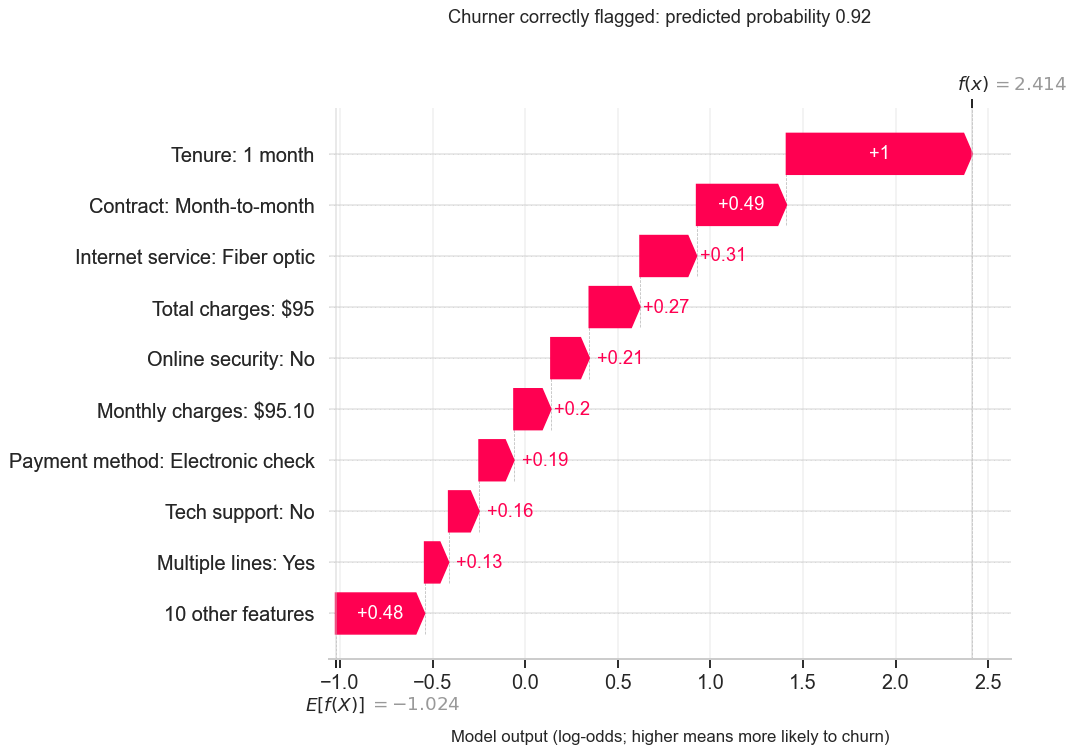

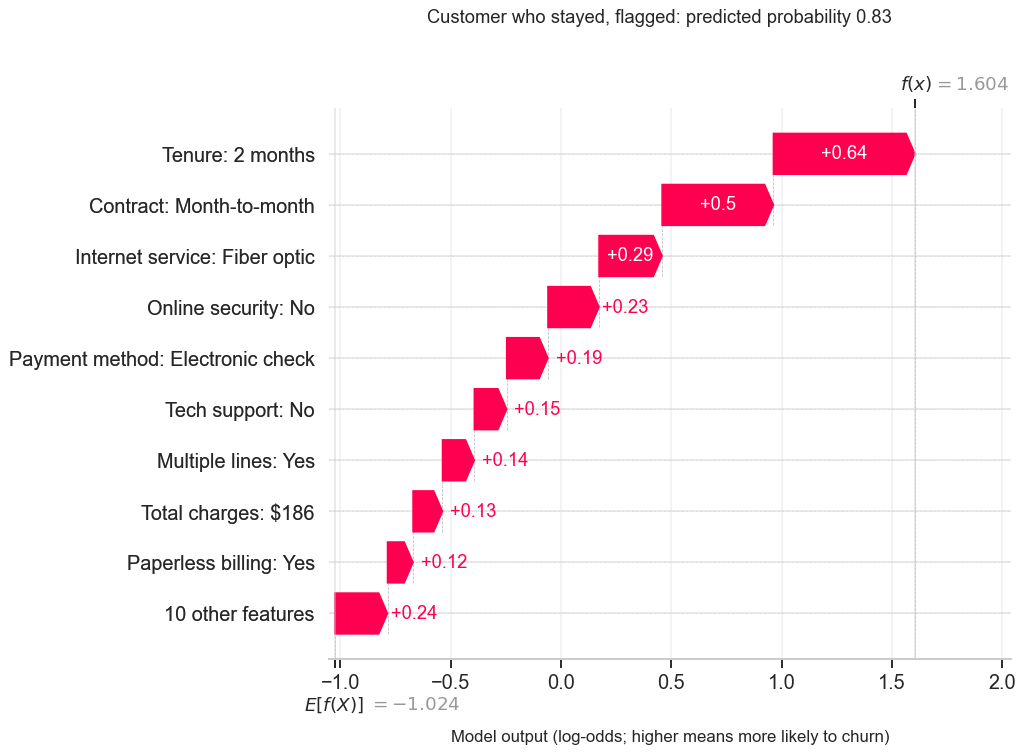

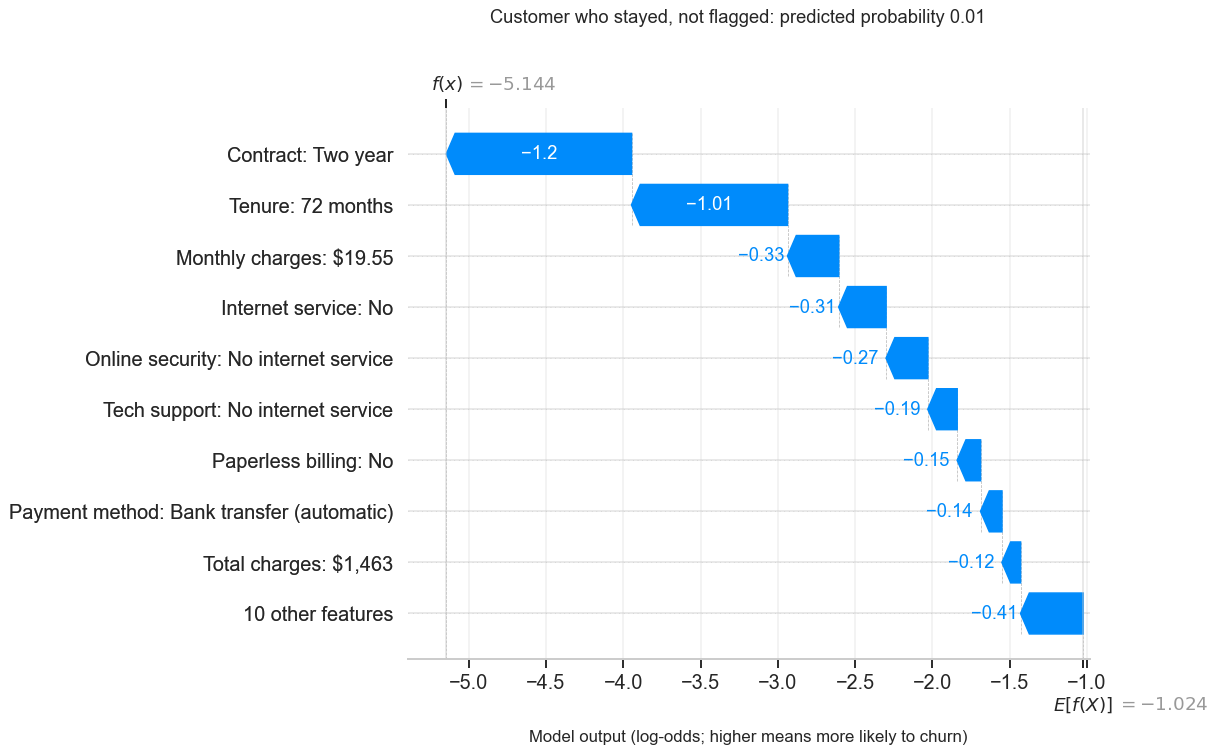

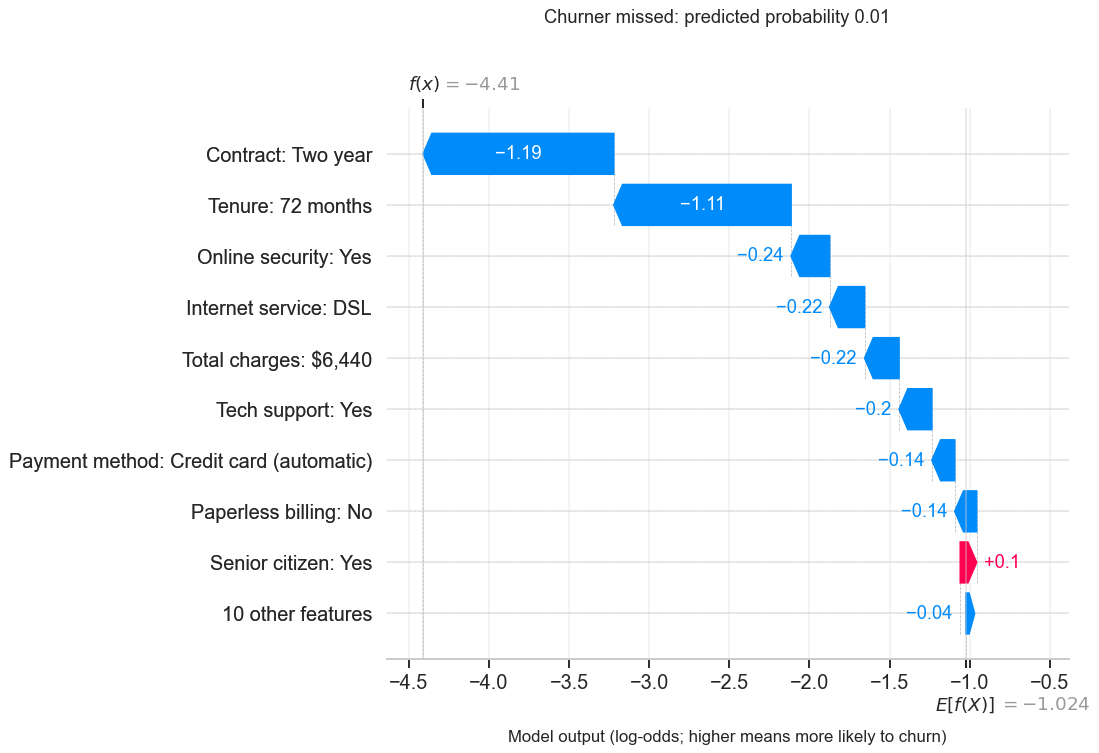

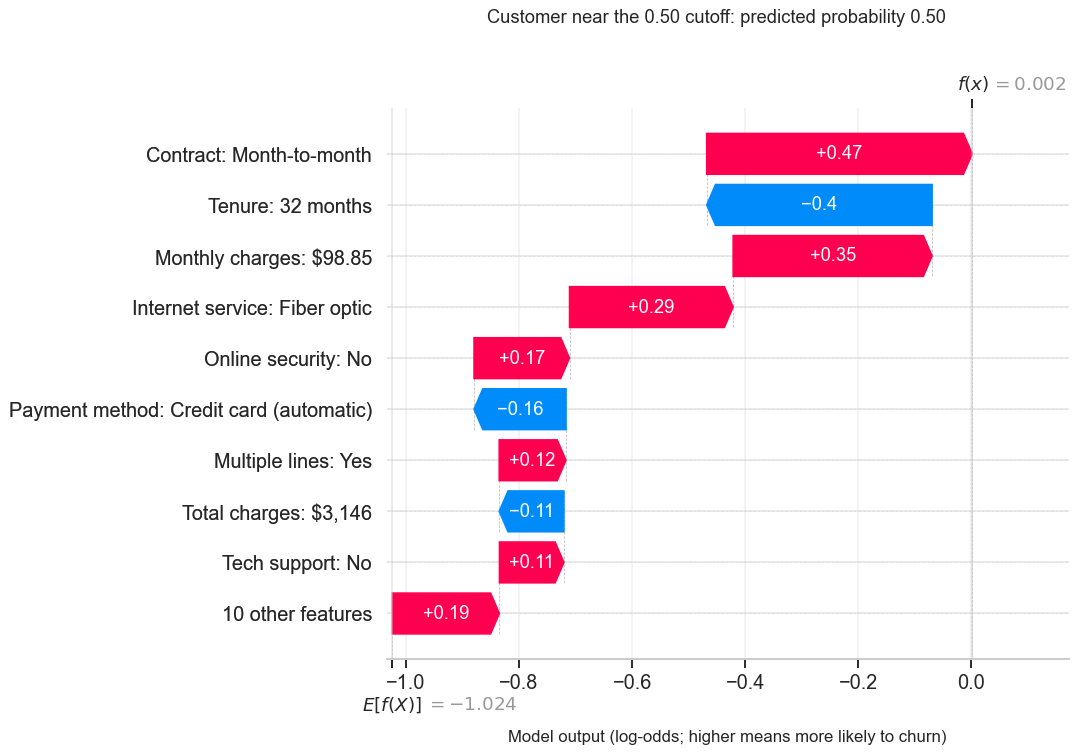

,case,index,pred_proba,y_true,top_positive_drivers,top_negative_drivers
0,TP_high_risk,3380,0.917883,1,"tenure (1.004), Contract_Month-to-month (0.435...","Contract_One year (-0.011), PhoneService_No (-..."
1,FP_high_risk,3346,0.832639,0,"tenure (0.641), Contract_Month-to-month (0.457...","StreamingTV_Yes (-0.052), Contract_One year (-..."
2,TN_low_risk,4201,0.005799,0,"StreamingTV_No (0.002), Partner_Yes (0.002), T...","tenure (-1.009), Contract_Month-to-month (-0.6..."
3,FN_missed_churn,4513,0.012009,1,"StreamingMovies_Yes (0.086), SeniorCitizen_No ...","tenure (-1.106), Contract_Month-to-month (-0.6..."
4,Borderline_near_threshold,1114,0.500422,0,"Contract_Month-to-month (0.413), MonthlyCharge...","tenure (-0.399), PaymentMethod_Electronic chec..."


Saved thesis_exports/tables/shap_case_driver_table.csv


In [42]:
# Generate selected waterfall plots and case-level SHAP driver table.
#
# shap.plots.waterfall() is the matplotlib-native local explanation
# for a single prediction. Each plot decomposes the model's predicted
# log-odds for one case into the base value plus the sum of per-feature
# SHAP contributions. The static figure renders identically in PDF
# (vector) and PNG (300 dpi raster); the deprecated force_plot screenshots
# the prior versions of this notebook produced were neither vector nor
# guaranteed to render cleanly in a thesis PDF.

from matplotlib.colors import to_rgba
from matplotlib.patches import FancyArrow

# Readable waterfall labels: one-hot attributions are summed back into the
# original field (SHAP values are additive, so the total is unchanged) and
# each field is shown with its raw value, e.g. "Tenure: 1 month".
READABLE_FIELD = {
    "gender": "Gender", "SeniorCitizen": "Senior citizen", "Partner": "Partner",
    "Dependents": "Dependents", "PhoneService": "Phone service",
    "MultipleLines": "Multiple lines", "InternetService": "Internet service",
    "OnlineSecurity": "Online security", "OnlineBackup": "Online backup",
    "DeviceProtection": "Device protection", "TechSupport": "Tech support",
    "StreamingTV": "Streaming TV", "StreamingMovies": "Streaming movies",
    "Contract": "Contract", "PaperlessBilling": "Paperless billing",
    "PaymentMethod": "Payment method", "tenure": "Tenure",
    "MonthlyCharges": "Monthly charges", "TotalCharges": "Total charges",
}
CASE_TITLES = {
    "TP_high_risk": "Churner correctly flagged",
    "FP_high_risk": "Customer who stayed, flagged",
    "TN_low_risk": "Customer who stayed, not flagged",
    "FN_missed_churn": "Churner missed",
    "Borderline_near_threshold": "Customer near the 0.50 cutoff",
}


def readable_value(field, value):
    if field == "tenure":
        return f"{int(value)} month" + ("" if int(value) == 1 else "s")
    if field == "MonthlyCharges":
        return f"${float(value):,.2f}"
    if field == "TotalCharges":
        return f"${float(value):,.0f}"
    return str(value)

case_driver_rows = []

for case_name, idx in selected_cases.items():
    row_position = X_test_shap.index.get_loc(idx)
    shap_row = shap_values_test[row_position]
    feature_row = X_test_shap.iloc[row_position]

    # Top positive and negative contributors for tabular interpretation.
    shap_series = pd.Series(shap_row, index=X_test_shap.columns)
    top_positive = shap_series.sort_values(ascending=False).head(3)
    top_negative = shap_series.sort_values(ascending=True).head(3)

    case_driver_rows.append(
        {
            "case": case_name,
            "index": int(idx),
            "pred_proba": float(case_frame.loc[idx, "pred_proba"]),
            "y_true": int(case_frame.loc[idx, "y_true"]),
            "top_positive_drivers": ", ".join(
                [f"{k} ({v:.3f})" for k, v in top_positive.items()]
            ),
            "top_negative_drivers": ", ".join(
                [f"{k} ({v:.3f})" for k, v in top_negative.items()]
            ),
        }
    )

    grouped_row = shap_series.groupby(map_to_base_feature).sum()
    raw_row = X_test.loc[idx]
    explanation = shap.Explanation(
        values=grouped_row.values,
        base_values=expected_value,
        data=None,
        feature_names=[
            f"{READABLE_FIELD.get(field, field)}: {readable_value(field, raw_row[field])}"
            for field in grouped_row.index
        ],
    )

    # shap.plots.waterfall creates its own figure, so no figure is opened
    # here first -- the previous plt.figure(figsize=...) was immediately
    # orphaned by the plt.gcf() below and leaked one empty figure per case.
    shap.plots.waterfall(explanation, max_display=10, show=False)
    fig_case = plt.gcf()
    fig_case.suptitle(
        f"{CASE_TITLES.get(case_name, case_name)}: predicted probability "
        f"{case_frame.loc[idx, 'pred_proba']:.2f}",
        y=1.02,
        fontsize=12,
    )
    # SHAP measures labels before returning; tight_layout would shrink its
    # axes afterwards. Keep that geometry and move only labels that cross
    # a tapered arrow edge into SHAP's existing outside-label style.
    ax_case = fig_case.axes[0]
    # labelpad keeps the axis title clear of SHAP's E[f(X)] annotation.
    ax_case.set_xlabel("Model output (log-odds; higher means more likely to churn)", labelpad=24)
    fig_case.canvas.draw()
    renderer = fig_case.canvas.get_renderer()
    arrows = [patch for patch in ax_case.patches if isinstance(patch, FancyArrow)]
    label_padding = 2 * fig_case.dpi / 72
    for label in ax_case.texts:
        if to_rgba(label.get_color()) != to_rgba("white"):
            continue
        label_y = ax_case.transData.transform(label.get_position())[1]
        arrow = min(
            arrows,
            key=lambda patch: abs(
                patch.get_window_extent(renderer).y0
                + patch.get_window_extent(renderer).height / 2 - label_y
            ),
        )
        bounds = label.get_window_extent(renderer).padded(label_padding)
        corners = [
            (bounds.x0, bounds.y0), (bounds.x0, bounds.y1),
            (bounds.x1, bounds.y0), (bounds.x1, bounds.y1),
        ]
        arrow_path = arrow.get_path().transformed(arrow.get_transform())
        if arrow_path.contains_points(corners).all():
            continue
        positive = label.get_text().startswith("+")
        arrow_bounds = arrow.get_window_extent(renderer)
        outside_x = (
            arrow_bounds.x1 + label_padding if positive
            else arrow_bounds.x0 - label_padding
        )
        label.set_position(ax_case.transData.inverted().transform((outside_x, label_y)))
        label.set_horizontalalignment("left" if positive else "right")
        label.set_color(arrow.get_facecolor())

    safe_case = case_name.lower().replace(" ", "_")
    save_figure(fig_case, f"shap_waterfall_{safe_case}")
    plt.show()
    # Release the figure after it has been rendered inline. This is the one
    # loop that builds figures in bulk; closing here keeps matplotlib from
    # accumulating open canvases across the five cases.
    plt.close(fig_case)

case_driver_df = pd.DataFrame(case_driver_rows)
display(case_driver_df)

case_driver_df.to_csv(TABLES_DIR / "shap_case_driver_table.csv", index=False)
print(f"Saved {TABLES_DIR / 'shap_case_driver_table.csv'}")


**Figure 12 (a–e). Local SHAP waterfalls.** These five deliberately selected cases include a true positive, false positive, true negative, false negative and a borderline score. They illustrate successes and errors at probability 0.50; they are not a representative sample for estimating performance. The missed churner is a failure of this model and decision rule on one record. Its explanation alone cannot identify whether better data, another model or another cutoff would fix it.

### Reading local cases with care

Numerical feature values shown to the left of a waterfall are standardized model inputs. A negative tenure value means below the training mean, not a negative number of months. The case profile table retains the original account values.

The caught churner and false alarm share important score contributions. That similarity does not establish that the same message would help either person. The false alarm shows a non-churner who would be contacted; whether that contact would be useful remains unknown. The missed churner shows a positive label that the score fails to flag.

A local explanation is a prompt for investigation. It should not be presented to a user as a diagnosis of their motives. Any follow-up should offer useful help, respect contact preferences and permit an easy refusal or exit.

<a id="signal-to-test"></a>
### Signal-to-test matrix

The next table joins grouped SHAP values with an analyst-authored interpretation for each of the top 15 features. Its sequence is **observed model signal → possible communication interpretation → competing explanations → proposed evaluation**.

The legacy fields `behavioral_driver` and `recommended_retention_action` are retained for compatibility. Their contents describe hypotheses and proposed tests, not measured psychological constructs or validated recommendations. The added fields make the evidential limits explicit. All 19 features appear in the following translation table.

In [43]:
# Shared analyst-authored hypotheses for the two communication tables.
# Model identifiers and existing CSV columns remain stable for downstream builds.
FEATURE_SEMANTICS = {
    "Contract": {
        "behavioral_driver": "Subscription terms and expectations (hypothesis)",
        "recommended_retention_action": "Test a clear, optional plan explanation",
        "telecom_meaning": "Length of service contract: month-to-month, one year or two years.",
        "communication_platform_analog": "Possible analogy: subscription terms may shape expectations and freedom to leave; they do not measure emotional commitment.",
        "retention_action": "Assess comprehension and ease of exit; test a neutral explanation of options, monitoring satisfaction and complaints.",
        "feature_label": "Contract type",
        "competing_explanations": "Contract restrictions, discounts and self-selection may explain retention without stronger attachment.",
        "proposed_evaluation": "Assess comprehension and ease of exit; test a neutral explanation of options, monitoring satisfaction and complaints.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "tenure": {
        "behavioral_driver": "Early relationship and onboarding (hypothesis)",
        "recommended_retention_action": "Test optional onboarding help",
        "telecom_meaning": "Recorded months with the service, from 0 to 72.",
        "communication_platform_analog": "Possible analogy: time since joining can locate a user in an onboarding process. Habit needs separate measurement.",
        "retention_action": "Measure onboarding steps and stated barriers; test specific help among eligible new users with a prespecified follow-up window.",
        "feature_label": "Tenure",
        "competing_explanations": "Acquisition cohort, plan mix and selective departure can change the tenure association.",
        "proposed_evaluation": "Measure onboarding steps and stated barriers; test specific help among eligible new users with a prespecified follow-up window.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "MonthlyCharges": {
        "behavioral_driver": "Price and value clarity (hypothesis)",
        "recommended_retention_action": "Test a neutral plan-fit explanation",
        "telecom_meaning": "Current monthly service charge.",
        "communication_platform_analog": "Possible analogy: recurring price can motivate questions about value and plan fit; perceived value is not observed.",
        "retention_action": "Measure actual use and perceived value separately; test clear plan information with satisfaction and unwanted-contact outcomes.",
        "feature_label": "Monthly bill",
        "competing_explanations": "Service bundle, discounts and affordability may account for the association.",
        "proposed_evaluation": "Measure actual use and perceived value separately; test clear plan information with satisfaction and unwanted-contact outcomes.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "TotalCharges": {
        "behavioral_driver": "Accumulated billing context (hypothesis)",
        "recommended_retention_action": "Investigate billing-history questions",
        "telecom_meaning": "Cumulative amount charged since signup.",
        "communication_platform_analog": "Possible analogy: a history of paid participation; it does not establish loyalty or a sunk-cost motive.",
        "retention_action": "Check whether billing-history information resolves stated questions; avoid messages designed to exploit sunk costs.",
        "feature_label": "Total billed",
        "competing_explanations": "Tenure and monthly bill explain much of the accumulated amount.",
        "proposed_evaluation": "Check whether billing-history information resolves stated questions; avoid messages designed to exploit sunk costs.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "InternetService": {
        "behavioral_driver": "Service experience by channel (hypothesis)",
        "recommended_retention_action": "Investigate service difficulties before messaging",
        "telecom_meaning": "Internet-service category: DSL, fiber optic or none.",
        "communication_platform_analog": "Possible analogy: access conditions may affect a platform experience; this field does not measure quality or outages.",
        "retention_action": "Collect relevant service-quality and reported-issue measures; evaluate whether targeted guidance resolves identified problems.",
        "feature_label": "Internet type",
        "competing_explanations": "Bundle composition, location, price and customer selection may differ by service type.",
        "proposed_evaluation": "Collect relevant service-quality and reported-issue measures; evaluate whether targeted guidance resolves identified problems.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "OnlineSecurity": {
        "behavioral_driver": "Security needs and awareness (hypothesis)",
        "recommended_retention_action": "Test optional security guidance",
        "telecom_meaning": "Whether the customer subscribes to an online-security add-on, including the no-internet category.",
        "communication_platform_analog": "Possible analogy: awareness or access to protective features; a subscription is not a direct trust measure.",
        "retention_action": "Measure needs, awareness and trust separately; test helpful guidance without fear-based framing, monitoring understanding and complaints.",
        "feature_label": "Security add-on",
        "competing_explanations": "Bundling, eligibility, affordability and different needs may explain subscription choices.",
        "proposed_evaluation": "Measure needs, awareness and trust separately; test helpful guidance without fear-based framing, monitoring understanding and complaints.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "TechSupport": {
        "behavioral_driver": "Access to help (hypothesis)",
        "recommended_retention_action": "Test guidance to available support",
        "telecom_meaning": "Whether the customer subscribes to a technical-support add-on, including the no-internet category.",
        "communication_platform_analog": "Possible analogy: access to support; the field records neither support use nor satisfaction.",
        "retention_action": "Measure unresolved issues and access barriers; test clear support routes and track resolution and satisfaction.",
        "feature_label": "Support add-on",
        "competing_explanations": "Service bundle and previous needs may affect subscription; absence is not evidence of a bad support experience.",
        "proposed_evaluation": "Measure unresolved issues and access barriers; test clear support routes and track resolution and satisfaction.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "PaymentMethod": {
        "behavioral_driver": "Billing process and choice (hypothesis)",
        "recommended_retention_action": "Test optional payment-setup help",
        "telecom_meaning": "Recorded payment method: electronic check, mailed check or automatic bank/card payment.",
        "communication_platform_analog": "Possible analogy: payment-process differences worth investigating; friction and commitment are not measured.",
        "retention_action": "Measure failed payments and stated difficulty; test neutral setup help while preserving payment choice and easy cancellation.",
        "feature_label": "Payment method",
        "competing_explanations": "Access to banking, preferences, tenure and bundle differences can explain associations.",
        "proposed_evaluation": "Measure failed payments and stated difficulty; test neutral setup help while preserving payment choice and easy cancellation.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "PaperlessBilling": {
        "behavioral_driver": "Billing information format (hypothesis)",
        "recommended_retention_action": "Test billing-summary clarity",
        "telecom_meaning": "Whether billing is paperless.",
        "communication_platform_analog": "Possible analogy: a billing-format choice; age, engagement and comprehension cannot be inferred from it.",
        "retention_action": "Ask about clarity and preferred format; test accessible billing summaries with comprehension and complaint measures.",
        "feature_label": "Paperless bill",
        "competing_explanations": "Defaults, service configuration and individual preferences may determine the format.",
        "proposed_evaluation": "Ask about clarity and preferred format; test accessible billing summaries with comprehension and complaint measures.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "MultipleLines": {
        "behavioral_driver": "Shared service configuration (hypothesis)",
        "recommended_retention_action": "Investigate shared-account needs",
        "telecom_meaning": "Whether the account has multiple telephone lines, including the no-phone-service category.",
        "communication_platform_analog": "Possible analogy: a shared account configuration; it does not measure social ties or community participation.",
        "retention_action": "Ask about actual shared-use needs before testing account-management guidance; do not infer relationships from the score.",
        "feature_label": "Multiple lines",
        "competing_explanations": "Household size, bundle price and account-management arrangements may differ.",
        "proposed_evaluation": "Ask about actual shared-use needs before testing account-management guidance; do not infer relationships from the score.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "StreamingTV": {
        "behavioral_driver": "Content access and discovery (hypothesis)",
        "recommended_retention_action": "Test optional content-discovery guidance",
        "telecom_meaning": "Whether the customer subscribes to streaming TV, including the no-internet category.",
        "communication_platform_analog": "Possible analogy: access to content features; subscription alone does not measure use or engagement.",
        "retention_action": "Measure consented usage and stated interests; test optional discovery guidance with usefulness and opt-out outcomes.",
        "feature_label": "TV add-on",
        "competing_explanations": "Bundling and pricing may drive access even if the feature is unused.",
        "proposed_evaluation": "Measure consented usage and stated interests; test optional discovery guidance with usefulness and opt-out outcomes.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "StreamingMovies": {
        "behavioral_driver": "Content access and discovery (hypothesis)",
        "recommended_retention_action": "Test optional content-discovery guidance",
        "telecom_meaning": "Whether the customer subscribes to streaming movies, including the no-internet category.",
        "communication_platform_analog": "Possible analogy: access to content features; no viewing behavior is recorded.",
        "retention_action": "Measure stated needs and relevant usage before testing discovery guidance; monitor usefulness and unwanted notifications.",
        "feature_label": "Movies add-on",
        "competing_explanations": "Bundle eligibility, price and content availability can affect subscriptions.",
        "proposed_evaluation": "Measure stated needs and relevant usage before testing discovery guidance; monitor usefulness and unwanted notifications.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "PhoneService": {
        "behavioral_driver": "Service access configuration (hypothesis)",
        "recommended_retention_action": "Investigate channel needs",
        "telecom_meaning": "Whether the customer has telephone service.",
        "communication_platform_analog": "Possible analogy: the available service channel; absence does not imply weak engagement.",
        "retention_action": "Ask users which channels meet their needs; evaluate guidance only where there is an identified access problem.",
        "feature_label": "Phone service",
        "competing_explanations": "Availability, price and deliberate service choices may explain the category.",
        "proposed_evaluation": "Ask users which channels meet their needs; evaluate guidance only where there is an identified access problem.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "DeviceProtection": {
        "behavioral_driver": "Protection needs and access (hypothesis)",
        "recommended_retention_action": "Test optional protection information",
        "telecom_meaning": "Whether the customer has a device-protection add-on, including the no-internet category.",
        "communication_platform_analog": "Possible analogy: access to protection services; risk aversion is not observed.",
        "retention_action": "Assess stated needs and comprehension; test clear information without presuming anxiety or automatically changing settings.",
        "feature_label": "Device cover",
        "competing_explanations": "Device ownership, eligibility and bundle pricing may explain uptake.",
        "proposed_evaluation": "Assess stated needs and comprehension; test clear information without presuming anxiety or automatically changing settings.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "OnlineBackup": {
        "behavioral_driver": "Backup needs and awareness (hypothesis)",
        "recommended_retention_action": "Test optional backup guidance",
        "telecom_meaning": "Whether the customer has an online-backup add-on, including the no-internet category.",
        "communication_platform_analog": "Possible analogy: access to backup; confidence, trust and actual use require separate evidence.",
        "retention_action": "Ask about needs and existing arrangements; test helpful setup information with understanding and opt-out measures.",
        "feature_label": "Backup add-on",
        "competing_explanations": "Bundling, other backup arrangements and price may account for uptake.",
        "proposed_evaluation": "Ask about needs and existing arrangements; test helpful setup information with understanding and opt-out measures.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "SeniorCitizen": {
        "behavioral_driver": "Demographic field for audit (hypothesis)",
        "recommended_retention_action": "No direct targeting; audit unequal treatment",
        "telecom_meaning": "Binary senior-citizen indicator in the benchmark.",
        "communication_platform_analog": "No presumed platform preference: age cannot determine desired communication channel or assistance.",
        "retention_action": "Evaluate subgroup errors and access to help; ask for channel preferences directly instead of inferring them from age.",
        "feature_label": "Senior flag",
        "competing_explanations": "Differences can reflect cohort composition, access or other correlated fields.",
        "proposed_evaluation": "Evaluate subgroup errors and access to help; ask for channel preferences directly instead of inferring them from age.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "Partner": {
        "behavioral_driver": "Household field for audit (hypothesis)",
        "recommended_retention_action": "No direct targeting; assess necessity",
        "telecom_meaning": "Whether the customer is recorded as having a partner.",
        "communication_platform_analog": "No presumed community attachment or shared platform use follows from this field.",
        "retention_action": "Assess whether collecting this field is justified and whether model errors differ; do not infer relationship needs.",
        "feature_label": "Partner status",
        "competing_explanations": "Household composition can correlate with plan and tenure without causing departure.",
        "proposed_evaluation": "Assess whether collecting this field is justified and whether model errors differ; do not infer relationship needs.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "Dependents": {
        "behavioral_driver": "Household field for audit (hypothesis)",
        "recommended_retention_action": "No direct targeting; assess necessity",
        "telecom_meaning": "Whether the customer is recorded as having dependents.",
        "communication_platform_analog": "No direct measure of switching costs, family needs or platform relationships.",
        "retention_action": "Assess necessity and subgroup effects before any application; gather expressed needs rather than infer them from family status.",
        "feature_label": "Dependents",
        "competing_explanations": "Plan mix and household resources may explain associations.",
        "proposed_evaluation": "Assess necessity and subgroup effects before any application; gather expressed needs rather than infer them from family status.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    },
    "gender": {
        "behavioral_driver": "Demographic field for audit (hypothesis)",
        "recommended_retention_action": "No direct targeting; audit unequal treatment",
        "telecom_meaning": "Gender category recorded in the supplied dataset.",
        "communication_platform_analog": "No communication motive or retention response is inferred from this category.",
        "retention_action": "Audit subgroup errors and representation; assess removing this field and correlated proxies before a separately validated application.",
        "feature_label": "Gender",
        "competing_explanations": "Observed differences may reflect correlated fields, sampling and unequal service experiences.",
        "proposed_evaluation": "Audit subgroup errors and representation; assess removing this field and correlated proxies before a separately validated application.",
        "evidence_status": "Model association; interpretation and intervention unvalidated"
    }
}

_missing_semantics = sorted(
    set(shap_grouped_importance["base_feature"]) - set(FEATURE_SEMANTICS)
)
if _missing_semantics:
    raise KeyError(f"Missing communication hypotheses for: {_missing_semantics}")

HYPOTHESIS_FIELDS = [
    "feature_label", "observed_signal", "competing_explanations",
    "proposed_evaluation", "evidence_status",
]


def hypothesis_fields(base_feature, rank, magnitude):
    semantics = FEATURE_SEMANTICS[base_feature]
    return {
        "feature_label": semantics["feature_label"],
        "observed_signal": (
            f"Grouped SHAP rank {rank} of {len(shap_grouped_importance)}; "
            f"absolute attribution mass {magnitude:.3f} log-odds. "
            "Magnitude describes this model and does not give a causal direction."
        ),
        "competing_explanations": semantics["competing_explanations"],
        "proposed_evaluation": semantics["proposed_evaluation"],
        "evidence_status": semantics["evidence_status"],
    }


matrix_rows = []
for rank, (_, row) in enumerate(shap_grouped_importance.head(15).iterrows(), start=1):
    base_feature = row["base_feature"]
    semantics = FEATURE_SEMANTICS[base_feature]
    matrix_rows.append({
        "feature_group": base_feature,
        "mean_abs_shap": float(row["mean_abs_shap"]),
        "behavioral_driver": semantics["behavioral_driver"],
        "recommended_retention_action": semantics["recommended_retention_action"],
        **hypothesis_fields(base_feature, rank, float(row["mean_abs_shap"])),
    })

shap_action_matrix = pd.DataFrame(matrix_rows)
display(shap_action_matrix[["feature_label", "mean_abs_shap", "behavioral_driver", "recommended_retention_action"]])
shap_action_matrix.to_csv(TABLES_DIR / "shap_driver_action_matrix.csv", index=False)
print(f"Saved {TABLES_DIR / 'shap_driver_action_matrix.csv'} (hypotheses, not validated actions)")

,feature_label,mean_abs_shap,behavioral_driver,recommended_retention_action
0,Contract type,0.731544,Subscription terms and expectations (hypothesis),"Test a clear, optional plan explanation"
1,Tenure,0.480508,Early relationship and onboarding (hypothesis),Test optional onboarding help
2,Internet type,0.309314,Service experience by channel (hypothesis),Investigate service difficulties before messaging
3,Security add-on,0.231306,Security needs and awareness (hypothesis),Test optional security guidance
4,Monthly bill,0.217774,Price and value clarity (hypothesis),Test a neutral plan-fit explanation
5,Support add-on,0.168271,Access to help (hypothesis),Test guidance to available support
6,Payment method,0.166636,Billing process and choice (hypothesis),Test optional payment-setup help
7,Paperless bill,0.139657,Billing information format (hypothesis),Test billing-summary clarity
8,Total billed,0.128984,Accumulated billing context (hypothesis),Investigate billing-history questions
9,Multiple lines,0.117347,Shared service configuration (hypothesis),Investigate shared-account needs


Saved thesis_exports/tables/shap_driver_action_matrix.csv (hypotheses, not validated actions)


In [44]:
# Check the exported signal-to-test schema and its evidence-status field.
EXPECTED_COLUMNS = [
    "feature_group", "mean_abs_shap", "behavioral_driver", "recommended_retention_action",
    *HYPOTHESIS_FIELDS,
]
_loaded_matrix = pd.read_csv(TABLES_DIR / "shap_driver_action_matrix.csv")
assert list(_loaded_matrix.columns) == EXPECTED_COLUMNS
assert pd.api.types.is_numeric_dtype(_loaded_matrix["mean_abs_shap"])
for txt_col in [c for c in EXPECTED_COLUMNS if c != "mean_abs_shap"]:
    assert pd.api.types.is_string_dtype(_loaded_matrix[txt_col]), txt_col
    assert _loaded_matrix[txt_col].notna().all(), txt_col
assert len(_loaded_matrix) == len(shap_action_matrix) == 15
assert (_loaded_matrix["mean_abs_shap"] >= 0).all()
print(f"Signal-to-test schema OK: {len(_loaded_matrix)} rows, {len(EXPECTED_COLUMNS)} columns.")

Signal-to-test schema OK: 15 rows, 9 columns.


### Full translation table

`shap_behavioral_translation.csv` covers all 19 original features. It records the literal Telco meaning, a possible platform analogy, competing explanations and a proposed evaluation. Short display labels improve readability without changing model identifiers.

An analogy must be reconsidered against the target platform's data and user research. Subscription cancellation, inactivity, account deletion and withdrawal from a community are different outcomes. The table does not establish that one Telco variable measures all of them.

In [45]:
# All 19 features share the same authored hypotheses as the shorter action table.
behavioral_mapping = {
    feature: (
        semantics["telecom_meaning"],
        semantics["communication_platform_analog"],
        semantics["retention_action"],
    )
    for feature, semantics in FEATURE_SEMANTICS.items()
}
assert len(behavioral_mapping) == 19

translation_rows = []
for rank, (_, row) in enumerate(shap_grouped_importance.iterrows(), start=1):
    base_feature = row["base_feature"]
    telecom_meaning, platform_analog, retention_action = behavioral_mapping[base_feature]
    translation_rows.append({
        "feature": base_feature,
        "mean_abs_shap": float(row["mean_abs_shap"]),
        "telecom_meaning": telecom_meaning,
        "communication_platform_analog": platform_analog,
        "retention_action": retention_action,
        **hypothesis_fields(base_feature, rank, float(row["mean_abs_shap"])),
    })

shap_behavioral_translation = pd.DataFrame(translation_rows)
display(shap_behavioral_translation[[
    "feature_label", "telecom_meaning", "communication_platform_analog", "competing_explanations",
]])
shap_behavioral_translation.to_csv(TABLES_DIR / "shap_behavioral_translation.csv", index=False)

_loaded_translation = pd.read_csv(TABLES_DIR / "shap_behavioral_translation.csv")
EXPECTED_TRANS_COLS = [
    "feature", "mean_abs_shap", "telecom_meaning", "communication_platform_analog",
    "retention_action", *HYPOTHESIS_FIELDS,
]
assert list(_loaded_translation.columns) == EXPECTED_TRANS_COLS
assert len(_loaded_translation) == len(shap_behavioral_translation) == len(behavioral_mapping)
assert _loaded_translation.notna().all().all()
print(f"Full hypothesis table schema OK: {len(_loaded_translation)} rows, {len(EXPECTED_TRANS_COLS)} columns.")

,feature_label,telecom_meaning,communication_platform_analog,competing_explanations
0,Contract type,"Length of service contract: month-to-month, on...",Possible analogy: subscription terms may shape...,"Contract restrictions, discounts and self-sele..."
1,Tenure,"Recorded months with the service, from 0 to 72.",Possible analogy: time since joining can locat...,"Acquisition cohort, plan mix and selective dep..."
2,Internet type,"Internet-service category: DSL, fiber optic or...",Possible analogy: access conditions may affect...,"Bundle composition, location, price and custom..."
3,Security add-on,Whether the customer subscribes to an online-s...,Possible analogy: awareness or access to prote...,"Bundling, eligibility, affordability and diffe..."
4,Monthly bill,Current monthly service charge.,Possible analogy: recurring price can motivate...,"Service bundle, discounts and affordability ma..."
5,Support add-on,Whether the customer subscribes to a technical...,Possible analogy: access to support; the field...,Service bundle and previous needs may affect s...
6,Payment method,"Recorded payment method: electronic check, mai...",Possible analogy: payment-process differences ...,"Access to banking, preferences, tenure and bun..."
7,Paperless bill,Whether billing is paperless.,Possible analogy: a billing-format choice; age...,"Defaults, service configuration and individual..."
8,Total billed,Cumulative amount charged since signup.,Possible analogy: a history of paid participat...,Tenure and monthly bill explain much of the ac...
9,Multiple lines,Whether the account has multiple telephone lin...,Possible analogy: a shared account configurati...,"Household size, bundle price and account-manag..."


Full hypothesis table schema OK: 19 rows, 10 columns.


### SHAP synthesis

Contract type and tenure dominate this XGBoost attribution summary. The result concerns how the fitted model uses the benchmark's inputs. The translation tables then add possible communication interpretations, plausible alternatives and tests that would be needed to evaluate them.

No proposed message has an estimated effect here. Demographic fields remain in the benchmark model, so refusing direct targeting by those fields does not remove indirect influence or establish fairness.

<a id="appendix"></a>
## Appendix: charts the TCC does not use

These exploratory and SHAP charts were part of the analysis but are not cited in the TCC. They describe the data and the fitted model; they add no result of their own. Running them last keeps the main sections short without changing any computation above.

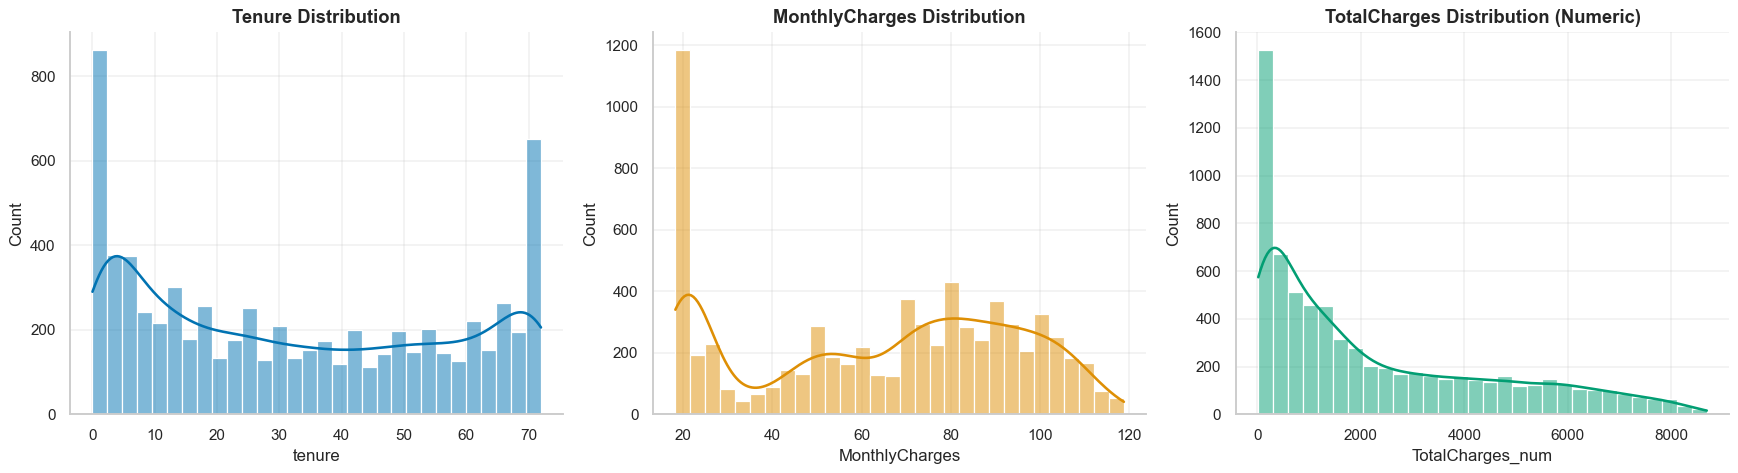

In [46]:
# Numeric univariate distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(eda_numeric_df["tenure"], kde=True, bins=30, ax=axes[0], color=PLOT_PALETTE[0])
axes[0].set_title("Tenure Distribution")

sns.histplot(eda_numeric_df["MonthlyCharges"], kde=True, bins=30, ax=axes[1], color=PLOT_PALETTE[1])
axes[1].set_title("MonthlyCharges Distribution")

sns.histplot(eda_numeric_df["TotalCharges_num"].dropna(), kde=True, bins=30, ax=axes[2], color=PLOT_PALETTE[2])
axes[2].set_title("TotalCharges Distribution (Numeric)")

plt.tight_layout()
save_figure(fig, "eda_numeric_distributions")
plt.show()

### Distributions

Tenure quartiles are 9, 29 and 55 months; monthly-charge quartiles are 35.50, 70.35 and 89.85. Total charges are right-skewed, with a mean above the median. They reflect accumulated billing, which is related to tenure and price but need not equal current monthly charges multiplied by tenure.

**Figure 13. Distributions of the three numerical fields.** The plots describe their scales and shapes before modeling.

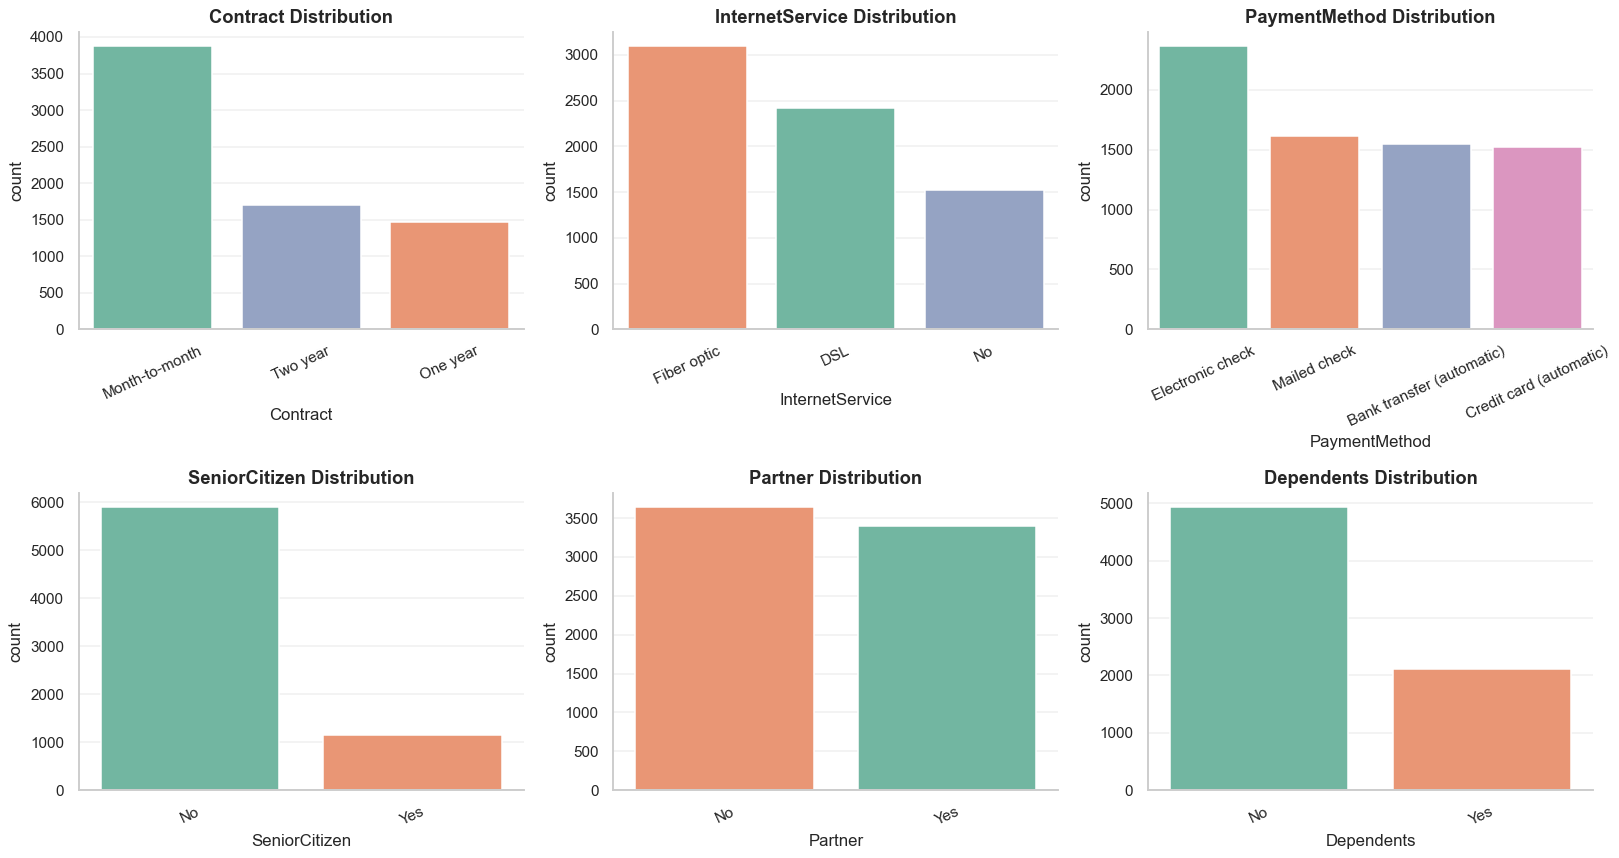

In [47]:
# Categorical univariate distributions (focused key features)
categorical_plot_df = df.copy()
if "SeniorCitizen" in categorical_plot_df.columns:
    categorical_plot_df["SeniorCitizen"] = categorical_plot_df["SeniorCitizen"].map({0: "No", 1: "Yes"}).fillna(
        categorical_plot_df["SeniorCitizen"].astype(str)
    )

key_categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "SeniorCitizen",
    "Partner",
    "Dependents",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(key_categorical_features):
    order = categorical_plot_df[col].astype(str).value_counts().index
    sns.countplot(
        data=categorical_plot_df,
        x=col,
        order=order,
        hue=col,
        palette="Set2",
        legend=False,
        ax=axes[i],
    )
    axes[i].set_title(f"{col} Distribution")
    axes[i].tick_params(axis="x", rotation=25)

plt.tight_layout()
save_figure(fig, "eda_categorical_distributions")
plt.show()

### Category counts

Month-to-month contracts cover 3,875 of 7,043 records (about 55%). Fiber-optic service appears in 3,096 records and electronic-check payment in 2,365. Counts matter when interpreting group-level rates: a category with fewer records offers less precise evidence.

**Figure 14. Counts for selected categorical fields.** These are service, account and demographic categories. Their frequencies do not themselves establish engagement or explain departure.

,tenure,MonthlyCharges,TotalCharges,ChurnBinary
tenure,1.000000,0.247900,0.825880,-0.352229
MonthlyCharges,0.247900,1.000000,0.651065,0.193356
TotalCharges,0.825880,0.651065,1.000000,-0.199484
ChurnBinary,-0.352229,0.193356,-0.199484,1.000000


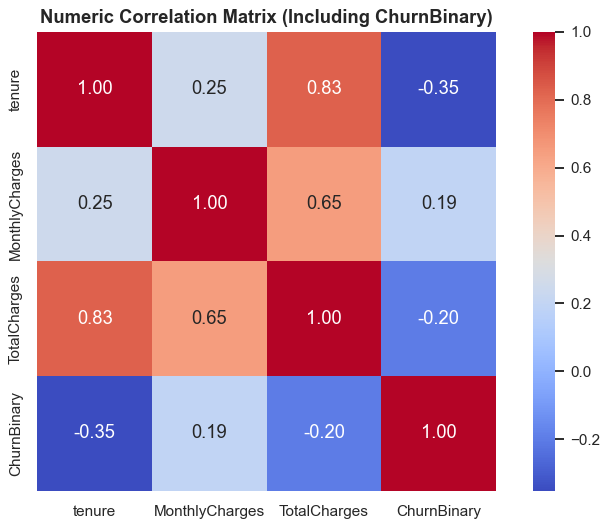

,feature,cramers_v_with_churn
13,Contract,0.2898
7,OnlineSecurity,0.2454
10,TechSupport,0.2422
6,InternetService,0.2277
8,OnlineBackup,0.2064
9,DeviceProtection,0.1988
14,PaperlessBilling,0.1911
15,PaymentMethod,0.1748
3,Dependents,0.1634
12,StreamingMovies,0.1629


In [48]:
# Correlation and association analysis
from scipy.stats import chi2_contingency

corr_df = pd.DataFrame(
    {
        "tenure": eda_numeric_df["tenure"],
        "MonthlyCharges": eda_numeric_df["MonthlyCharges"],
        "TotalCharges": eda_numeric_df["TotalCharges_num"],
        "ChurnBinary": (df["Churn"] == "Yes").astype(int),
    }
)

corr_matrix = corr_df.corr(numeric_only=True)
display(corr_matrix)

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Numeric Correlation Matrix (Including ChurnBinary)")
plt.tight_layout()
save_figure(plt.gcf(), "eda_correlation_matrix")
plt.show()


def cramers_v(x, y):
    contingency = pd.crosstab(x, y)
    chi2 = chi2_contingency(contingency)[0]
    n = contingency.to_numpy().sum()
    r, k = contingency.shape
    phi2 = chi2 / n
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = max((kcorr - 1), (rcorr - 1), 1e-12)
    return np.sqrt(phi2corr / denom)


association_df = df.copy()
association_df["SeniorCitizen"] = association_df["SeniorCitizen"].map({0: "No", 1: "Yes"}).fillna(
    association_df["SeniorCitizen"].astype(str)
)

# `customerID` is a 7,043-level identifier: its Cramer's V against any
# target is a meaningless artifact of cardinality, so it is excluded here
# exactly as it is dropped from the model matrix later in Data Preparation.
ASSOC_EXCLUDED = {"Churn", "customerID"}
categorical_for_assoc = [
    col
    for col in association_df.columns
    if col not in ASSOC_EXCLUDED and association_df[col].dtype in ["object", "category", "str"]
]

assoc_rows = []
for col in categorical_for_assoc:
    score = cramers_v(association_df[col].astype(str), association_df["Churn"].astype(str))
    assoc_rows.append({"feature": col, "cramers_v_with_churn": round(score, 4)})

if assoc_rows:
    association_table = pd.DataFrame(assoc_rows).sort_values("cramers_v_with_churn", ascending=False)
    display(association_table.head(15))
else:
    print("No categorical columns found for Cramer's V analysis.")

**Figure 15. Pearson correlations.** Tenure correlates with the binary churn indicator at about −0.352 and with total charges at about 0.826. Correlated inputs can share predictive information, complicating the interpretation of any one importance measure.

### SHAP dependence plots

For each of the five highest-ranked original features, the plot uses its most influential transformed column. Position shows the feature value and its SHAP contribution; color shows an automatically selected related input. Patterns can reveal variation in model behavior, but color separation alone is not a formal test of interaction.

These plots help describe the fitted model. A communication hypothesis based on them must also consider selection effects, correlated services and omitted user experiences.

Top-5 base features and chosen transformed columns:
  - Contract  (via Contract_Month-to-month)
  - tenure
  - InternetService  (via InternetService_Fiber optic)
  - OnlineSecurity  (via OnlineSecurity_No)
  - MonthlyCharges


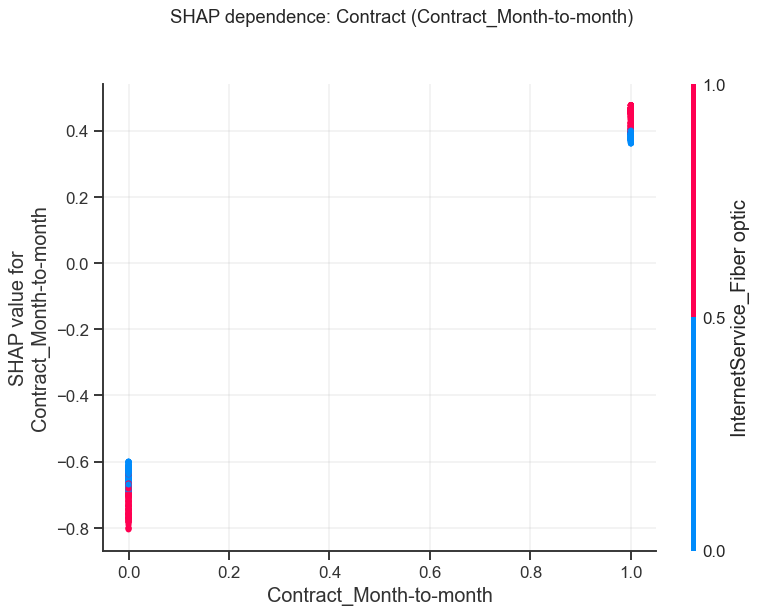

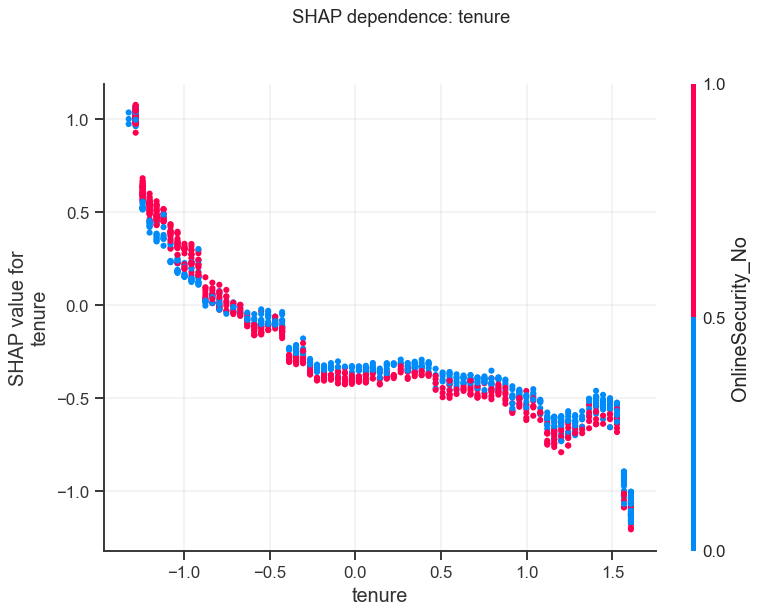

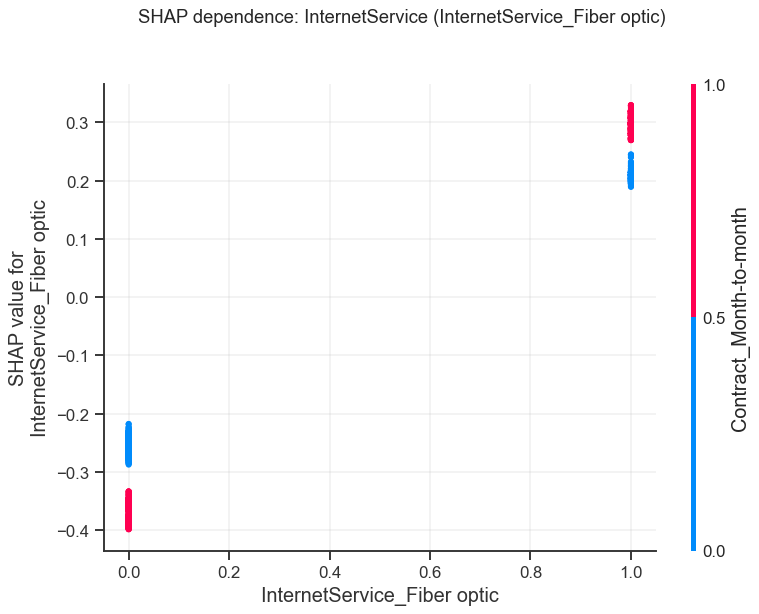

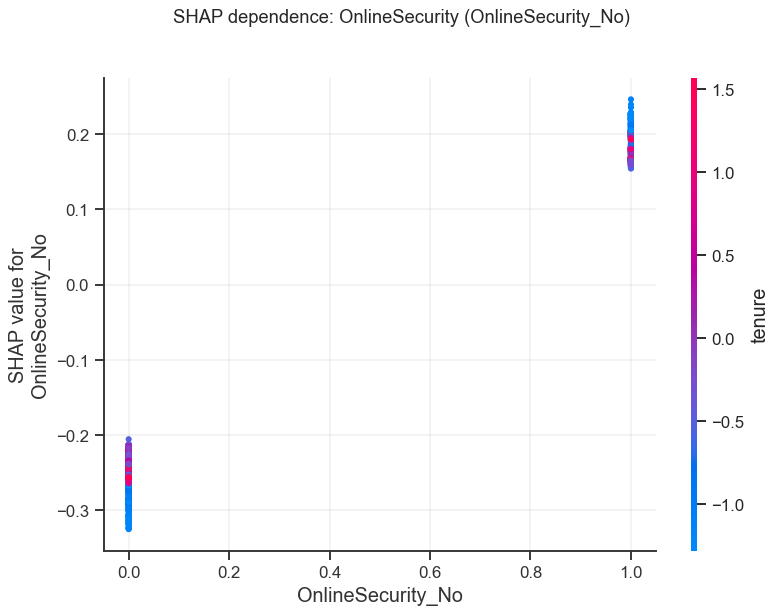

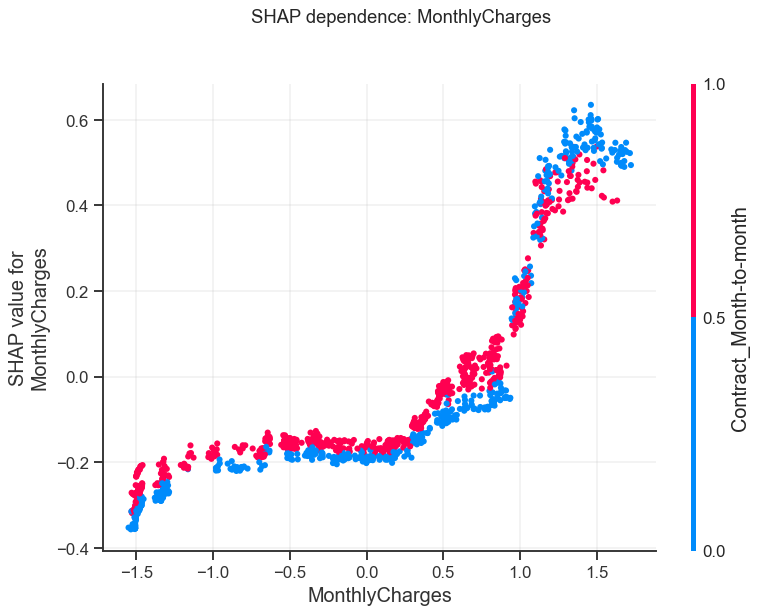

Saved 5 SHAP dependence plots in thesis_exports/figures.


In [49]:
# Phase 3 - Task 3.2: SHAP dependence plots for top-5 base features.
#
# Procedure:
#   1. Take the top-5 base features from shap_grouped_importance.
#   2. For each base feature, pick the transformed column with the
#      largest mean |SHAP| (so categorical features land on their
#      most-impactful one-hot dummy).
#   3. Render shap.dependence_plot with interaction_index='auto' so
#      SHAP picks the strongest second-order interaction.
#   4. Persist each plot via save_figure to PDF + 300 dpi PNG.

top5_base = shap_grouped_importance["base_feature"].head(5).tolist()

dependence_targets = []
for base in top5_base:
    # Map back to transformed columns belonging to this base feature.
    candidates = shap_importance_table[
        shap_importance_table["base_feature"] == base
    ].sort_values("mean_abs_shap", ascending=False)
    if candidates.empty:
        continue
    chosen = candidates.iloc[0]["feature"]
    dependence_targets.append((base, chosen))

print("Top-5 base features and chosen transformed columns:")
for base, chosen in dependence_targets:
    suffix = "" if base == chosen else f"  (via {chosen})"
    print(f"  - {base}{suffix}")

for base, chosen in dependence_targets:
    fig_dep = plt.figure(figsize=(7.5, 5.5))
    shap.dependence_plot(
        chosen,
        shap_values_test,
        X_test_shap,
        interaction_index="auto",
        show=False,
        ax=fig_dep.gca(),
    )
    fig_dep.suptitle(
        f"SHAP dependence: {base}" + (f" ({chosen})" if chosen != base else ""),
        y=1.02,
        fontsize=12,
    )
    fig_dep.tight_layout()
    safe = base.lower().replace(" ", "_")
    save_figure(fig_dep, f"shap_dependence_{safe}")
    plt.show()

print(f"Saved {len(dependence_targets)} SHAP dependence plots in {FIGURES_DIR}.")


**Figure 16 (a–e). Dependence plots for five highly ranked features.** Each panel shows a transformed input and its SHAP contribution. Color adds a second input selected by the plotting heuristic. Categories and nonlinear patterns describe how this model assigns scores; the plots do not establish a causal intervention, a formally tested interaction or why the linear model performs similarly.

## Export manifest

`thesis_exports/tables/export_manifest.csv` records the tables and figures, their paths and their producing phase. The next cell rebuilds it from disk and checks that every listed path exists and every export is listed. Editorial traceability tables are marked as manually maintained.

A stale `survival_*` artifact causes a failure rather than being presented as current evidence. The manifest checks artifact coverage; it does not verify the wording of manuscript citations or prove that every file was produced by this execution. Those checks belong to the repository's build and reproducibility review.

In [50]:
# Regenerate export_manifest.csv from what is actually on disk.
#
# This is the last export cell in the notebook, so by the time it runs every
# table and figure above has been written. It walks thesis_exports/ rather
# than restating a hand-kept list, then asserts the contract in both
# directions:
#   (a) every file on disk is listed in the manifest;
#   (b) every path the manifest lists exists on disk.

EXPORT_ROOT = Path("thesis_exports")
MANIFEST_PATH = TABLES_DIR / "export_manifest.csv"
MANIFEST_COLUMNS = [
    "name", "type", "format", "phase", "producing_cell", "path", "source", "status",
]

# Ordered prefix rules: first match wins. Keys are filename stems, so one rule
# covers a table and its figure twin (e.g. model_learning_curve).
PROVENANCE_RULES = [
    ("export_manifest",             "Manifest",              "this cell (regenerated from disk)"),
    ("finding_traceability_matrix", "Editorial",             "hand-maintained outside the notebook"),
    ("objective_traceability_matrix", "Editorial",           "hand-maintained outside the notebook"),
    ("data_quality_",               "1. Data Preparation",   "missing-value handling cell"),
    ("train_test_split_",           "1. Data Preparation",   "stratified train/test split cell"),
    ("class_balance_",              "1. Data Preparation",   "stratified train/test split cell"),
    ("churn_rate_by_group",         "1. Data Understanding", "churn rate by group cell"),
    ("eda_",                        "1. Data Understanding", "EDA figure cells"),
    ("model_cv_scores",             "2. Evaluation",         "stratified cross-validation cell"),
    ("model_comparison_metrics",    "2. Evaluation",         "calibration cell (single write)"),
    ("svm_decision_rule_metrics",   "2. Evaluation",         "holdout evaluation cell (SVM own decision rule)"),
    ("model_auc_pairwise",          "2. Evaluation",         "pairwise AUC-test cell"),
    ("model_calibration",           "2. Evaluation",         "calibration cell"),
    ("model_overfitting_gap",       "2. Evaluation",         "train-vs-test gap cell"),
    ("model_learning_curve",        "2. Evaluation",         "learning-curve cell"),
    ("model_repeated_cv",           "2. Evaluation",         "repeated cross-validation cell"),
    ("model_ranking",               "2. Evaluation",         "fixed explanation-model / descriptive-ranking cell"),
    ("model_roc_comparison",        "2. Modeling",           "holdout ROC figure cell"),
    ("threshold_",                  "2. Evaluation",         "descriptive holdout threshold-sensitivity cell"),
    ("split_ratio_",                "2. Evaluation",         "split-ratio sensitivity cell"),
    ("tenure_cohort_",              "2. Evaluation",         "tenure-cohort cell"),
    ("permutation_importance",      "2. Evaluation",         "permutation-importance cell"),
    ("inference_latency",           "2. Evaluation",         "inference-cost cell (machine-dependent)"),
    ("shap_feature_importance_transformed", "3. SHAP",       "transformed-feature SHAP importance cell"),
    ("shap_feature_importance_grouped",     "3. SHAP",       "grouped SHAP importance cell"),
    ("shap_summary_",               "3. SHAP",               "global SHAP figure cells"),
    ("shap_dependence_",            "3. SHAP",               "SHAP dependence-plot cell"),
    ("shap_waterfall_",             "3. SHAP",               "local waterfall cell"),
    ("shap_case_overview",          "3. SHAP",               "local-case selection cell"),
    ("shap_case_driver_table",      "3. SHAP",               "local waterfall cell"),
    ("shap_driver_action_matrix",   "3. SHAP",               "driver-to-action matrix cell"),
    ("shap_behavioral_translation", "3. SHAP",               "behavioral-translation cell"),
]


def _scan_exports():
    return sorted(
        p for p in EXPORT_ROOT.rglob("*")
        if p.is_file() and not p.name.startswith(".")
    )


def _describe(path: Path) -> dict:
    stem = path.stem
    phase, producing_cell = "unclassified", "not attributed"
    for prefix, rule_phase, rule_cell in PROVENANCE_RULES:
        if stem.startswith(prefix):
            phase, producing_cell = rule_phase, rule_cell
            break

    if path.parent.name == FIGURES_DIR.name:
        kind = "figure"
    elif path.parent.name == TABLES_DIR.name:
        kind = "table"
    else:
        kind = "other"

    manual = phase == "Editorial"
    return {
        "name": stem,
        "type": kind,
        "format": path.suffix.lstrip("."),
        "phase": phase,
        "producing_cell": producing_cell,
        "path": path.as_posix(),
        "source": "manual" if manual else "notebook",
        "status": "hand-maintained" if manual else "exported",
    }


# A revised run must not present retired estimates as current evidence.
_retired = sorted(p.as_posix() for p in EXPORT_ROOT.rglob("survival_*") if p.is_file())
if _retired:
    raise RuntimeError(
        "Retired survival artifacts remain in thesis_exports; remove these stale outputs "
        "before regenerating the manifest: " + ", ".join(_retired)
    )

# Keep a copy of the previous manifest so the run reports what changed.
_previous_paths = set()
if MANIFEST_PATH.exists():
    try:
        _previous_paths = set(pd.read_csv(MANIFEST_PATH)["path"].astype(str))
    except Exception as exc:  # unreadable or differently-shaped old manifest
        print(f"Previous manifest could not be diffed ({exc}); rebuilding from scratch.")

# The manifest lists itself, so add its own path before writing it.
_paths = {p.as_posix() for p in _scan_exports()}
_paths.add(MANIFEST_PATH.as_posix())

export_manifest_df = pd.DataFrame(
    [_describe(Path(p)) for p in sorted(_paths)], columns=MANIFEST_COLUMNS
)
export_manifest_df.to_csv(MANIFEST_PATH, index=False)

# (a) every file on disk is listed
_disk_paths = {p.as_posix() for p in _scan_exports()}
_listed_paths = set(export_manifest_df["path"])
_unlisted = sorted(_disk_paths - _listed_paths)
assert not _unlisted, f"files on disk missing from the manifest: {_unlisted}"

# (b) every listed path exists
_dangling = sorted(p for p in _listed_paths if not Path(p).exists())
assert not _dangling, f"manifest lists files that do not exist: {_dangling}"

_unclassified = sorted(export_manifest_df.loc[
    export_manifest_df["phase"] == "unclassified", "name"
].unique())
if _unclassified:
    print(
        "WARNING: no provenance rule matched these artifacts -- add one to "
        f"PROVENANCE_RULES: {_unclassified}"
    )

_added = sorted(_listed_paths - _previous_paths)
_removed = sorted(_previous_paths - _listed_paths)
if _previous_paths:
    print(f"Manifest rows added since the previous manifest: {len(_added)}")
    for _p in _added:
        print(f"  + {_p}")
    print(f"Manifest rows removed: {len(_removed)}")
    for _p in _removed:
        print(f"  - {_p}")

display(export_manifest_df.groupby(["type", "phase"], as_index=False).size())
print(
    f"Wrote {MANIFEST_PATH} -- {len(export_manifest_df)} artifacts "
    f"({int((export_manifest_df['type'] == 'table').sum())} tables, "
    f"{int((export_manifest_df['type'] == 'figure').sum())} figures). "
    "Disk and manifest agree in both directions."
)

Manifest rows added since the previous manifest: 1
  + thesis_exports/tables/churn_rate_by_group.csv
Manifest rows removed: 0


,type,phase,size
0,figure,1. Data Understanding,12
1,figure,2. Evaluation,14
2,figure,2. Modeling,2
3,figure,3. SHAP,22
4,table,1. Data Preparation,3
5,table,1. Data Understanding,1
6,table,2. Evaluation,19
7,table,3. SHAP,6
8,table,Editorial,2
9,table,Manifest,1


Wrote thesis_exports/tables/export_manifest.csv -- 82 artifacts (32 tables, 50 figures). Disk and manifest agree in both directions.


<a id="demo-export"></a>
## Offline demo export

The demo illustrates a selected record from the fictional-operator benchmark, its XGBoost score and a short explanation. The export below supplies raw holdout values, all five models' probabilities, SHAP contributions and the tree/preprocessing data used for offline scoring.

An edited input produces a new model score, not an estimate of an intervention's effect. The main defense can use a static example; running the notebook live is unnecessary. The JSON is written to `demo/data/`, separately from the thesis tables.

In [51]:
# Demo export -- OUTSIDE the thesis export contract (demo/data/, not thesis_exports/).
# Reads kernel state only; writes nothing the thesis cites.
import json
import xgboost

DEMO_DIR = Path("demo/data")
DEMO_DIR.mkdir(parents=True, exist_ok=True)

# 1. Fitted preprocessing specification (categories in fitted order, scaler stats).
_pre = best_model_for_shap.named_steps["preprocessor"]
_ohe = _pre.named_transformers_["categorical"]
_sc = _pre.named_transformers_["numeric"]
preprocessor_spec = {
    "categorical": [{"name": c, "categories": [str(v) for v in cats]}
                    for c, cats in zip(cat_cols, _ohe.categories_)],
    "numeric": [{"name": n, "mean": float(m), "scale": float(s)}
                for n, m, s in zip(num_cols, _sc.mean_, _sc.scale_)],
    "feature_names": list(transformed_feature_names),
}
assert len(preprocessor_spec["feature_names"]) == X_test_shap.shape[1]
(DEMO_DIR / "preprocessor.json").write_text(json.dumps(preprocessor_spec, indent=1))

# 2. XGBoost trees, stripped to what a tree walker needs.
_raw = json.loads(bytes(shap_model.get_booster().save_raw(raw_format="json")))
_learner = _raw["learner"]
_base = _learner["learner_model_param"]["base_score"]
_base = float(json.loads(_base)[0]) if str(_base).startswith("[") else float(_base)
assert _learner["objective"]["name"] == "binary:logistic"
_KEEP = ["split_indices", "split_conditions", "left_children", "right_children", "default_left", "sum_hessian"]
xgb_export = {
    "xgboost_version": xgboost.__version__,
    "base_score": _base,
    "num_feature": int(_learner["learner_model_param"]["num_feature"]),
    "trees": [{k: t[k] for k in _KEEP} for t in _learner["gradient_booster"]["model"]["trees"]],
}
(DEMO_DIR / "xgb_model.json").write_text(json.dumps(xgb_export, separators=(",", ":")))

# 3. Logistic Regression as a second opinion (coefficients live in transformed space).
_lr = best_estimators["Logistic Regression"].named_steps["model"]
(DEMO_DIR / "lr_model.json").write_text(json.dumps({
    "coef": _lr.coef_[0].tolist(), "intercept": float(_lr.intercept_[0]),
    "feature_names": list(transformed_feature_names),
}))

# 4. Holdout customers: raw values, every model's probability, XGBoost SHAP.
_raw_rows = X_test.copy()
for c in categorical_features:
    _raw_rows[c] = _raw_rows[c].astype(str)
_customers = []
for pos, (idx, y_true) in enumerate(zip(X_test.index, y_test_enc)):
    row = {k: (float(v) if k in numerical_features else str(v)) for k, v in _raw_rows.loc[idx].items()}
    _customers.append({"row": int(idx), "customerID": str(df.loc[idx, "customerID"]),
                       "y_true": int(y_true), "x": row})
demo_payload = {
    "provenance": {"xgboost": xgboost.__version__, "shap": shap.__version__,
                   "n_test": int(len(X_test)), "expected_value": float(expected_value),
                   "random_state": RANDOM_STATE, "models": list(best_estimators.keys())},
    "customers": _customers,
    "proba": {name: np.round(p, 6).tolist() for name, p in proba_by_model.items()},
    "shap_xgb": np.round(np.asarray(shap_values_test), 6).tolist(),
    "cases": case_overview_df.to_dict("records"),
}
(DEMO_DIR / "demo_data.json").write_text(json.dumps(demo_payload, separators=(",", ":")))

# Self-check: exported SHAP values still add up to each customer's log-odds.
_p = np.clip(proba_by_model["XGBoost"], 1e-9, 1 - 1e-9)
_recon = float(expected_value) + np.asarray(shap_values_test).sum(axis=1)
assert np.allclose(_recon, np.log(_p / (1 - _p)), atol=1e-3), "SHAP additivity check failed"
for _f in ("preprocessor.json", "xgb_model.json", "lr_model.json", "demo_data.json"):
    print(f"Wrote {DEMO_DIR / _f}  ({(DEMO_DIR / _f).stat().st_size / 1e6:.2f} MB)")
print(f"XGBoost trees exported: {len(xgb_export['trees'])}; base_score = {_base:.6f}; SHAP additivity OK.")


Wrote demo/data/preprocessor.json  (0.00 MB)
Wrote demo/data/xgb_model.json  (0.21 MB)
Wrote demo/data/lr_model.json  (0.00 MB)
Wrote demo/data/demo_data.json  (1.99 MB)
XGBoost trees exported: 839; base_score = 0.265353; SHAP additivity OK.
